In [ ]:
!pip -q install kagglehub


In [ ]:

import kagglehub

ruta = kagglehub.dataset_download(
    "mkechinov/ecommerce-behavior-data-from-multi-category-store",
    path="2019-Oct.csv"
)

print("Archivo descargado en:", ruta)


100%|██████████| 1.61G/1.61G [00:21<00:00, 79.7MB/s]

Extracting zip of 2019-Oct.csv...


Archivo descargado en: /root/.cache/kagglehub/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/versions/8/2019-Oct.csv


In [ ]:

import pandas as pd

df = pd.read_csv(ruta, nrows=10000)

print("Filas:", len(df))
print("Columnas:", df.columns.tolist())

display(df.head(10))


Filas: 10000
Columnas: ['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00 UTC,view,44600062,2103807459595387724,NaN,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
1,2019-10-01 00:00:00 UTC,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc
2,2019-10-01 00:00:01 UTC,view,17200506,2053013559792632471,furniture.living_room.sofa,NaN,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8
3,2019-10-01 00:00:01 UTC,view,1307067,2053013558920217191,computers.notebook,lenovo,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713
4,2019-10-01 00:00:04 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d
5,2019-10-01 00:00:05 UTC,view,1480613,2053013561092866779,computers.desktop,pulser,908.62,512742880,0d0d91c2-c9c2-4e81-90a5-86594dec0db9
6,2019-10-01 00:00:08 UTC,view,17300353,2053013553853497655,NaN,creed,380.96,555447699,4fe811e9-91de-46da-90c3-bbd87ed3a65d
7,2019-10-01 00:00:08 UTC,view,31500053,2053013558031024687,NaN,luminarc,41.16,550978835,6280d577-25c8-4147-99a7-abc6048498d6
8,2019-10-01 00:00:10 UTC,view,28719074,2053013565480109009,apparel.shoes.keds,baden,102.71,520571932,ac1cd4e5-a3ce-4224-a2d7-ff660a105880
9,2019-10-01 00:00:11 UTC,view,1004545,2053013555631882655,electronics.smartphone,huawei,566.01,537918940,406c46ed-90a4-4787-a43b-59a410c1a5fb


In [ ]:

# EXPLORACIÓN INICIAL DEL DATASET

print("TIPOS DE EVENTOS")
print(df["event_type"].value_counts())

print("\nPRODUCTOS ÚNICOS")
print(df["product_id"].nunique())

print("\nUSUARIOS ÚNICOS")
print(df["user_id"].nunique())

print("\nVALORES FALTANTES")
print(df.isnull().sum())


TIPOS DE EVENTOS
event_type
view        9785
purchase     118
cart          97
Name: count, dtype: int64

PRODUCTOS ÚNICOS
4148

USUARIOS ÚNICOS
2867

VALORES FALTANTES
event_time          0
event_type          0
product_id          0
category_id         0
category_code    3277
brand            1442
price               0
user_id             0
user_session        0
dtype: int64


In [ ]:

# PROYECTO EDA - ETAPA 1
# LIMPIEZA Y PREPARACION

import pandas as pd

# Copia para no modificar los datos originales
df_limpio = df.copy()

# 1. Completar valores faltantes
df_limpio["category_code"] = (
    df_limpio["category_code"].fillna("unknown")
)

df_limpio["brand"] = (
    df_limpio["brand"].fillna("unknown")
)

# 2. Convertir fecha
df_limpio["event_time"] = pd.to_datetime(
    df_limpio["event_time"],
    utc=True
)

# 3. Eliminar duplicados exactos
antes = len(df_limpio)

df_limpio = df_limpio.drop_duplicates()

despues = len(df_limpio)

# 4. Ordenar por fecha
df_limpio = df_limpio.sort_values(
    "event_time"
).reset_index(drop=True)

# 5. Resultados
print("REGISTROS ORIGINALES:", antes)
print("REGISTROS LIMPIOS:", despues)
print("DUPLICADOS ELIMINADOS:", antes - despues)

print("\nVALORES FALTANTES:")
print(df_limpio.isnull().sum())

print("\nPRIMEROS REGISTROS:")
display(df_limpio.head())


REGISTROS ORIGINALES: 10000
REGISTROS LIMPIOS: 9996
DUPLICADOS ELIMINADOS: 4

VALORES FALTANTES:
event_time       0
event_type       0
product_id       0
category_id      0
category_code    0
brand            0
price            0
user_id          0
user_session     0
dtype: int64

PRIMEROS REGISTROS:


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00+00:00,view,44600062,2103807459595387724,unknown,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
1,2019-10-01 00:00:00+00:00,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc
2,2019-10-01 00:00:01+00:00,view,17200506,2053013559792632471,furniture.living_room.sofa,unknown,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8
3,2019-10-01 00:00:01+00:00,view,1307067,2053013558920217191,computers.notebook,lenovo,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713
4,2019-10-01 00:00:04+00:00,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d


In [ ]:

# PROYECTO EDA - ETAPA 0
# INGESTA DE EVENTOS CON COLA FIFO

from collections import deque
import time

# 1. Crear la cola
cola_eventos = deque()

# 2. Recibir los eventos limpios
inicio = time.perf_counter()

for evento in df_limpio.to_dict("records"):
    cola_eventos.append(evento)

fin = time.perf_counter()

print("EVENTOS RECIBIDOS:", len(cola_eventos))
print("TIEMPO DE INGESTA:", round(fin - inicio, 6), "segundos")

# 3. Procesar los primeros 5 eventos
print("\nPRIMEROS EVENTOS PROCESADOS:")

for i in range(5):
    evento = cola_eventos.popleft()

    print(
        "Evento:", i + 1,
        "| Tipo:", evento["event_type"],
        "| Producto:", evento["product_id"]
    )

# 4. Verificar la cola
print("\nEVENTOS PENDIENTES:", len(cola_eventos))


EVENTOS RECIBIDOS: 9996
TIEMPO DE INGESTA: 0.039904 segundos

PRIMEROS EVENTOS PROCESADOS:
Evento: 1 | Tipo: view | Producto: 44600062
Evento: 2 | Tipo: view | Producto: 3900821
Evento: 3 | Tipo: view | Producto: 17200506
Evento: 4 | Tipo: view | Producto: 1307067
Evento: 5 | Tipo: view | Producto: 1004237

EVENTOS PENDIENTES: 9991


In [ ]:

# PROYECTO EDA - ETAPA 1
# MERGE SORT + BUSQUEDA BINARIA + DEDUPLICACION

from collections import deque
from bisect import bisect_left
import time

# 1. Recuperar eventos originales para simular la ingesta
cola_original = deque(df.to_dict("records"))

# 2. Extraer eventos de la cola FIFO
eventos = []

while cola_original:
    eventos.append(cola_original.popleft())

# 3. Implementar Merge Sort
def merge_sort(lista):
    if len(lista) <= 1:
        return lista

    mitad = len(lista) // 2

    izquierda = merge_sort(lista[:mitad])
    derecha = merge_sort(lista[mitad:])

    resultado = []
    i = j = 0

    while i < len(izquierda) and j < len(derecha):
        if izquierda[i]["product_id"] <= derecha[j]["product_id"]:
            resultado.append(izquierda[i])
            i += 1
        else:
            resultado.append(derecha[j])
            j += 1

    resultado.extend(izquierda[i:])
    resultado.extend(derecha[j:])

    return resultado

# 4. Ordenar eventos por producto
inicio = time.perf_counter()

eventos_ordenados = merge_sort(eventos)

fin = time.perf_counter()

print("EVENTOS ORDENADOS:", len(eventos_ordenados))
print("TIEMPO MERGE SORT:", round(fin - inicio, 5), "segundos")

# 5. Crear lista de IDs ordenados
ids_productos = [
    evento["product_id"]
    for evento in eventos_ordenados
]

# 6. Buscar un producto mediante busqueda binaria
producto_buscado = 1004237

inicio = time.perf_counter()

posicion = bisect_left(ids_productos, producto_buscado)

encontrado = (
    posicion < len(ids_productos)
    and ids_productos[posicion] == producto_buscado
)

fin = time.perf_counter()

print("\nPRODUCTO BUSCADO:", producto_buscado)
print("PRODUCTO ENCONTRADO:", encontrado)

if encontrado:
    print("POSICION:", posicion)
    print("EVENTO:", eventos_ordenados[posicion])

print("TIEMPO BUSQUEDA:", round(fin - inicio, 8), "segundos")


EVENTOS ORDENADOS: 10000
TIEMPO MERGE SORT: 0.03349 segundos

PRODUCTO BUSCADO: 1004237
PRODUCTO ENCONTRADO: True
POSICION: 533
EVENTO: {'event_time': '2019-10-01 00:00:04 UTC', 'event_type': 'view', 'product_id': 1004237, 'category_id': 2053013555631882655, 'category_code': 'electronics.smartphone', 'brand': 'apple', 'price': 1081.98, 'user_id': 535871217, 'user_session': 'c6bd7419-2748-4c56-95b4-8cec9ff8b80d'}
TIEMPO BUSQUEDA: 0.00011858 segundos


In [ ]:

# PROYECTO EDA - ETAPA 1B
# DEDUPLICACION MEDIANTE HASH SET

import time

inicio = time.perf_counter()

eventos_unicos = []
claves_vistas = set()

for evento in eventos_ordenados:

    clave = (
        evento["event_time"],
        evento["event_type"],
        evento["product_id"],
        evento["category_id"],
        evento["category_code"],
        evento["brand"],
        evento["price"],
        evento["user_id"],
        evento["user_session"]
    )

    # Normalizar valores faltantes para comparar
    clave = tuple(
        "MISSING" if pd.isna(valor) else valor
        for valor in clave
    )

    if clave not in claves_vistas:
        claves_vistas.add(clave)
        eventos_unicos.append(evento)

fin = time.perf_counter()

print("EVENTOS ORIGINALES:", len(eventos_ordenados))
print("EVENTOS UNICOS:", len(eventos_unicos))

print(
    "DUPLICADOS ELIMINADOS:",
    len(eventos_ordenados) - len(eventos_unicos)
)

print(
    "TIEMPO DEDUPLICACION:",
    round(fin - inicio, 6),
    "segundos"
)


EVENTOS ORIGINALES: 10000
EVENTOS UNICOS: 9996
DUPLICADOS ELIMINADOS: 4
TIEMPO DEDUPLICACION: 0.036163 segundos


In [ ]:

# PROYECTO EDA - ETAPA 2
# PRIORIZACION DE EVENTOS MEDIANTE MIN-HEAP

import heapq
import random
import time
from collections import Counter

random.seed(42)

# 1. Crear la cola de prioridades
heap_eventos = []

# 2. Definir prioridades
def asignar_prioridad(evento):

    tipo = evento["event_type"]

    if tipo == "purchase":

        # Simulacion de alerta de posible fraude
        if random.random() < 0.05:
            return 1, "Posible fraude"

        # Simulacion de tipo de entrega
        entrega = random.choices(
            ["Express", "Estandar", "Programada"],
            weights=[20, 60, 20]
        )[0]

        prioridades = {
            "Express": 2,
            "Estandar": 3,
            "Programada": 4
        }

        return prioridades[entrega], entrega

    elif tipo == "cart":
        return 5, "Carrito"

    else:
        return 6, "Vista"

# 3. Insertar eventos en el Heap
inicio = time.perf_counter()

for i, evento in enumerate(eventos_unicos):

    prioridad, categoria = asignar_prioridad(evento)

    heapq.heappush(
        heap_eventos,
        (prioridad, i, categoria, evento)
    )

fin = time.perf_counter()

print("EVENTOS PRIORIZADOS:", len(heap_eventos))
print("TIEMPO DE INSERCION:", round(fin - inicio, 6), "segundos")

# 4. Ver distribucion de prioridades
conteo = Counter(
    item[2] for item in heap_eventos
)

print("\nDISTRIBUCION DE EVENTOS:")

for categoria, cantidad in conteo.items():
    print(categoria, ":", cantidad)

# 5. Atender los 10 eventos mas urgentes
print("\nPRIMEROS 10 EVENTOS ATENDIDOS:")

for i in range(10):

    prioridad, orden, categoria, evento = heapq.heappop(
        heap_eventos
    )

    print(
        i + 1,
        "| Prioridad:", prioridad,
        "| Categoria:", categoria,
        "| Producto:", evento["product_id"]
    )

print("\nEVENTOS PENDIENTES:", len(heap_eventos))


EVENTOS PRIORIZADOS: 9996
TIEMPO DE INSERCION: 0.007047 segundos

DISTRIBUCION DE EVENTOS:
Posible fraude : 3
Express : 21
Estandar : 73
Programada : 21
Vista : 9781
Carrito : 97

PRIMEROS 10 EVENTOS ATENDIDOS:
1 | Prioridad: 1 | Categoria: Posible fraude | Producto: 1003316
2 | Prioridad: 1 | Categoria: Posible fraude | Producto: 1004246
3 | Prioridad: 1 | Categoria: Posible fraude | Producto: 1005112
4 | Prioridad: 2 | Categoria: Express | Producto: 1002524
5 | Prioridad: 2 | Categoria: Express | Producto: 1002544
6 | Prioridad: 2 | Categoria: Express | Producto: 1002634
7 | Prioridad: 2 | Categoria: Express | Producto: 1004246
8 | Prioridad: 2 | Categoria: Express | Producto: 1004446
9 | Prioridad: 2 | Categoria: Express | Producto: 1004750
10 | Prioridad: 2 | Categoria: Express | Producto: 1004856

EVENTOS PENDIENTES: 9986


In [ ]:

# PROYECTO EDA - ETAPA 3
# HASH TABLE + CACHE LRU

from collections import OrderedDict
import time

# 1. Crear catalogo de productos
catalogo = {}

for evento in eventos_unicos:
    producto_id = evento["product_id"]

    catalogo[producto_id] = {
        "categoria": evento["category_code"],
        "marca": evento["brand"],
        "precio": evento["price"]
    }

print("PRODUCTOS EN CATALOGO:", len(catalogo))

# 2. Implementar cache LRU
class CacheLRU:

    def __init__(self, capacidad):
        self.capacidad = capacidad
        self.cache = OrderedDict()
        self.aciertos = 0
        self.fallos = 0

    def obtener(self, clave):

        if clave in self.cache:
            self.cache.move_to_end(clave)
            self.aciertos += 1
            return self.cache[clave]

        self.fallos += 1
        return None

    def guardar(self, clave, valor):

        if clave in self.cache:
            self.cache.move_to_end(clave)

        self.cache[clave] = valor

        if len(self.cache) > self.capacidad:
            self.cache.popitem(last=False)

# 3. Crear cache para 100 productos
cache = CacheLRU(capacidad=100)

# 4. Consultar productos
def consultar_producto(producto_id):

    producto = cache.obtener(producto_id)

    if producto is not None:
        return producto, "CACHE"

    producto = catalogo.get(producto_id)

    if producto is not None:
        cache.guardar(producto_id, producto)
        return producto, "HASH TABLE"

    return None, "NO ENCONTRADO"

# 5. Probar consultas repetidas
producto_prueba = eventos_unicos[0]["product_id"]

for i in range(3):

    inicio = time.perf_counter()

    producto, origen = consultar_producto(
        producto_prueba
    )

    fin = time.perf_counter()

    print(
        f"Consulta {i+1}:",
        producto_prueba,
        "| Origen:", origen,
        "| Tiempo:", round(fin-inicio, 8),
        "segundos"
    )

print("\nACIERTOS CACHE:", cache.aciertos)
print("FALLOS CACHE:", cache.fallos)
print("ELEMENTOS EN CACHE:", len(cache.cache))


PRODUCTOS EN CATALOGO: 4148
Consulta 1: 1002099 | Origen: HASH TABLE | Tiempo: 1.153e-05 segundos
Consulta 2: 1002099 | Origen: CACHE | Tiempo: 3.23e-06 segundos
Consulta 3: 1002099 | Origen: CACHE | Tiempo: 1.81e-06 segundos

ACIERTOS CACHE: 2
FALLOS CACHE: 1
ELEMENTOS EN CACHE: 1


In [ ]:

# PROYECTO EDA - ETAPA 3B
# MATRIZ DISPERSA USUARIO-PRODUCTO

import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

# 1. Convertir eventos unicos en DataFrame
df_interacciones = pd.DataFrame(eventos_unicos)

# 2. Asignar pesos segun tipo de evento
pesos = {
    "view": 1,
    "cart": 3,
    "purchase": 5
}

df_interacciones["peso"] = (
    df_interacciones["event_type"]
    .map(pesos)
    .fillna(1)
)

# 3. Agrupar interacciones por usuario y producto
agrupado = (
    df_interacciones
    .groupby(["user_id", "product_id"])["peso"]
    .sum()
    .reset_index()
)

# 4. Convertir IDs a posiciones numericas
usuarios, filas = np.unique(
    agrupado["user_id"],
    return_inverse=True
)

productos, columnas = np.unique(
    agrupado["product_id"],
    return_inverse=True
)

# 5. Construir matriz dispersa CSR
matriz = csr_matrix(
    (
        agrupado["peso"].values,
        (filas, columnas)
    ),
    shape=(len(usuarios), len(productos))
)

# 6. Mostrar resultados
print("USUARIOS:", len(usuarios))
print("PRODUCTOS:", len(productos))
print("DIMENSIONES:", matriz.shape)
print("INTERACCIONES NO NULAS:", matriz.nnz)

total_celdas = matriz.shape[0] * matriz.shape[1]

densidad = matriz.nnz / total_celdas * 100

print("DENSIDAD:", round(densidad, 4), "%")
print("ESPARSIDAD:", round(100 - densidad, 4), "%")

# 7. Comparar memoria
memoria_densa = total_celdas * matriz.dtype.itemsize

memoria_dispersa = (
    matriz.data.nbytes
    + matriz.indices.nbytes
    + matriz.indptr.nbytes
)

print("\nMEMORIA DENSA ESTIMADA:",
      round(memoria_densa / 1024**2, 2), "MB")

print("MEMORIA DISPERSA:",
      round(memoria_dispersa / 1024**2, 2), "MB")


USUARIOS: 2867
PRODUCTOS: 4148
DIMENSIONES: (2867, 4148)
INTERACCIONES NO NULAS: 7026
DENSIDAD: 0.0591 %
ESPARSIDAD: 99.9409 %

MEMORIA DENSA ESTIMADA: 90.73 MB
MEMORIA DISPERSA: 0.09 MB


In [ ]:

# PROYECTO EDA - ETAPA 4
# B+TREE PARA BUSQUEDA POR RANGOS DE PRECIO

from bisect import bisect_left, bisect_right
import time

class NodoBPlus:
    def __init__(self, hoja=False):
        self.hoja = hoja
        self.claves = []
        self.hijos = []
        self.siguiente = None


class BPlusTree:
    def __init__(self, orden=8):
        self.orden = orden
        self.raiz = NodoBPlus(hoja=True)

    def insertar(self, clave, valor):
        resultado = self._insertar(self.raiz, clave, valor)

        if resultado is not None:
            separador, nuevo_nodo = resultado

            nueva_raiz = NodoBPlus()
            nueva_raiz.claves = [separador]
            nueva_raiz.hijos = [self.raiz, nuevo_nodo]
            self.raiz = nueva_raiz

    def _insertar(self, nodo, clave, valor):

        if nodo.hoja:
            posicion = bisect_left(nodo.claves, clave)

            if (
                posicion < len(nodo.claves)
                and nodo.claves[posicion] == clave
            ):
                nodo.hijos[posicion].append(valor)
            else:
                nodo.claves.insert(posicion, clave)
                nodo.hijos.insert(posicion, [valor])

            if len(nodo.claves) <= self.orden:
                return None

            mitad = len(nodo.claves) // 2
            nuevo = NodoBPlus(hoja=True)

            nuevo.claves = nodo.claves[mitad:]
            nuevo.hijos = nodo.hijos[mitad:]

            nodo.claves = nodo.claves[:mitad]
            nodo.hijos = nodo.hijos[:mitad]

            nuevo.siguiente = nodo.siguiente
            nodo.siguiente = nuevo

            return nuevo.claves[0], nuevo

        posicion = bisect_right(nodo.claves, clave)

        resultado = self._insertar(
            nodo.hijos[posicion], clave, valor
        )

        if resultado is None:
            return None

        separador, nuevo_hijo = resultado

        nodo.claves.insert(posicion, separador)
        nodo.hijos.insert(posicion + 1, nuevo_hijo)

        if len(nodo.claves) <= self.orden:
            return None

        mitad = len(nodo.claves) // 2
        separador = nodo.claves[mitad]

        nuevo = NodoBPlus()
        nuevo.claves = nodo.claves[mitad + 1:]
        nuevo.hijos = nodo.hijos[mitad + 1:]

        nodo.claves = nodo.claves[:mitad]
        nodo.hijos = nodo.hijos[:mitad + 1]

        return separador, nuevo

    def buscar_rango(self, minimo, maximo):
        nodo = self.raiz

        while not nodo.hoja:
            posicion = bisect_right(nodo.claves, minimo)
            nodo = nodo.hijos[posicion]

        resultados = []

        while nodo is not None:
            for clave, valores in zip(
                nodo.claves, nodo.hijos
            ):
                if clave > maximo:
                    return resultados

                if minimo <= clave <= maximo:
                    for valor in valores:
                        resultados.append((clave, valor))

            nodo = nodo.siguiente

        return resultados


# 1. Construir indice de productos
arbol = BPlusTree(orden=8)

inicio = time.perf_counter()

for producto_id, datos in catalogo.items():
    arbol.insertar(
        float(datos["precio"]),
        producto_id
    )

fin = time.perf_counter()

print("PRODUCTOS INDEXADOS:", len(catalogo))
print("TIEMPO CONSTRUCCION:", round(fin-inicio, 6), "s")

# 2. Buscar productos entre 500 y 1000
precio_minimo = 500
precio_maximo = 1000

inicio = time.perf_counter()

resultados = arbol.buscar_rango(
    precio_minimo, precio_maximo
)

fin = time.perf_counter()

print("\nPRODUCTOS EN RANGO:", len(resultados))
print("TIEMPO BUSQUEDA:", round(fin-inicio, 6), "s")

print("\nPRIMEROS 10 RESULTADOS:")
for precio, producto_id in resultados[:10]:
    print(
        "Producto:", producto_id,
        "| Precio:", precio
    )

# 3. Validacion contra busqueda directa
esperados = sorted(
    (float(datos["precio"]), producto_id)
    for producto_id, datos in catalogo.items()
    if precio_minimo <= float(datos["precio"]) <= precio_maximo
)

assert sorted(resultados) == esperados
print("\nVALIDACION: CORRECTA")


PRODUCTOS INDEXADOS: 4148
TIEMPO CONSTRUCCION: 0.03291 s

PRODUCTOS EN RANGO: 372
TIEMPO BUSQUEDA: 0.00031 s

PRIMEROS 10 RESULTADOS:
Producto: 1480707 | Precio: 501.92
Producto: 26300084 | Precio: 501.94
Producto: 26402928 | Precio: 501.97
Producto: 12201675 | Precio: 504.26
Producto: 14700124 | Precio: 504.26
Producto: 1801881 | Precio: 506.29
Producto: 5301323 | Precio: 507.07
Producto: 17200216 | Precio: 507.07
Producto: 1307101 | Precio: 509.41
Producto: 1003293 | Precio: 509.81

VALIDACION: CORRECTA


In [ ]:

# PROYECTO EDA - ETAPA 5
# KD-TREE + KNN EXACTO

import numpy as np
import pandas as pd
import time

from sklearn.neighbors import KDTree, NearestNeighbors
from sklearn.preprocessing import StandardScaler

# 1. Crear atributos numericos de productos
df_productos = pd.DataFrame(eventos_unicos)

popularidad = (
    df_productos.groupby("product_id")
    .size()
    .rename("popularidad")
)

atributos = pd.DataFrame.from_dict(
    catalogo, orient="index"
)

atributos.index.name = "product_id"

atributos = atributos.join(popularidad)
atributos["popularidad"] = (
    atributos["popularidad"].fillna(0)
)

# 2. Seleccionar precio y popularidad
X = atributos[["precio", "popularidad"]].astype(float)

# 3. Normalizar variables
escalador = StandardScaler()
X_normalizado = escalador.fit_transform(X)

# 4. Construir KD-Tree
inicio = time.perf_counter()

kd_tree = KDTree(
    X_normalizado,
    leaf_size=40
)

fin = time.perf_counter()

print("PRODUCTOS INDEXADOS:", len(X))
print("TIEMPO KD-TREE:", round(fin-inicio, 6), "s")

# 5. Seleccionar un producto de referencia
producto_referencia = 1004237

if producto_referencia not in atributos.index:
    producto_referencia = atributos.index[0]

posicion = atributos.index.get_loc(
    producto_referencia
)

consulta = X_normalizado[posicion:posicion+1]

# 6. Buscar los 5 vecinos mas cercanos
inicio = time.perf_counter()

distancias, indices = kd_tree.query(
    consulta, k=6
)

fin = time.perf_counter()

print("\nPRODUCTO DE REFERENCIA:", producto_referencia)
print("TIEMPO BUSQUEDA KD-TREE:",
      round(fin-inicio, 6), "s")

print("\nPRODUCTOS SIMILARES:")

for indice, distancia in zip(
    indices[0], distancias[0]
):
    producto_id = atributos.index[indice]

    if producto_id == producto_referencia:
        continue

    print(
        "Producto:", producto_id,
        "| Precio:", round(X.iloc[indice]["precio"], 2),
        "| Popularidad:", int(X.iloc[indice]["popularidad"]),
        "| Distancia:", round(distancia, 4)
    )

# 7. Comparar contra KNN exacto por fuerza bruta
knn = NearestNeighbors(
    n_neighbors=6,
    algorithm="brute"
)

knn.fit(X_normalizado)

inicio = time.perf_counter()

distancias_brute, indices_brute = (
    knn.kneighbors(consulta)
)

fin = time.perf_counter()

print("\nTIEMPO KNN FUERZA BRUTA:",
      round(fin-inicio, 6), "s")

# 8. Validar coincidencia de distancias
assert np.allclose(
    distancias[0],
    distancias_brute[0],
    atol=1e-8
)

print("VALIDACION DISTANCIAS: CORRECTA")


PRODUCTOS INDEXADOS: 4148
TIEMPO KD-TREE: 0.005284 s

PRODUCTO DE REFERENCIA: 1004237
TIEMPO BUSQUEDA KD-TREE: 0.000316 s

PRODUCTOS SIMILARES:
Producto: 1003316 | Precio: 946.97 | Popularidad: 18 | Distancia: 0.5656
Producto: 1004665 | Precio: 871.14 | Popularidad: 17 | Distancia: 0.8659
Producto: 1005073 | Precio: 1207.71 | Popularidad: 16 | Distancia: 0.8852
Producto: 1004238 | Precio: 1206.4 | Popularidad: 15 | Distancia: 1.0697
Producto: 1003317 | Precio: 957.53 | Popularidad: 25 | Distancia: 1.0697

TIEMPO KNN FUERZA BRUTA: 0.051874 s
VALIDACION DISTANCIAS: CORRECTA


In [ ]:

# PROYECTO EDA - ETAPA 6
# BLOOM FILTER + COUNT-MIN SKETCH

!pip -q install mmh3

import mmh3
import math
import random
import numpy as np
from collections import Counter

# 1. Implementar Bloom Filter
class BloomFilter:
    def __init__(self, capacidad, error=0.01):
        self.m = math.ceil(
            -(capacidad * math.log(error)) /
            (math.log(2) ** 2)
        )
        self.k = max(
            1, round((self.m / capacidad) * math.log(2))
        )
        self.bits = bytearray(math.ceil(self.m / 8))

    def _posiciones(self, elemento):
        for i in range(self.k):
            yield mmh3.hash(
                str(elemento), i, signed=False
            ) % self.m

    def agregar(self, elemento):
        for pos in self._posiciones(elemento):
            self.bits[pos // 8] |= 1 << (pos % 8)

    def contiene(self, elemento):
        return all(
            self.bits[pos // 8] & (1 << (pos % 8))
            for pos in self._posiciones(elemento)
        )


# 2. Implementar Count-Min Sketch
class CountMinSketch:
    def __init__(self, ancho=2000, profundidad=5):
        self.ancho = ancho
        self.profundidad = profundidad
        self.tabla = np.zeros(
            (profundidad, ancho), dtype=np.int64
        )

    def agregar(self, elemento):
        for i in range(self.profundidad):
            pos = mmh3.hash(
                str(elemento), i, signed=False
            ) % self.ancho
            self.tabla[i, pos] += 1

    def estimar(self, elemento):
        return min(
            self.tabla[i, mmh3.hash(
                str(elemento), i, signed=False
            ) % self.ancho]
            for i in range(self.profundidad)
        )


# 3. Obtener usuarios reales del dataset
usuarios = sorted({
    int(e["user_id"]) for e in eventos_unicos
})

# 4. Simular usuarios señalados
random.seed(42)
usuarios_senalados = set(
    random.sample(usuarios, min(30, len(usuarios)))
)

# 5. Construir Bloom Filter
bloom = BloomFilter(
    capacidad=len(usuarios_senalados),
    error=0.01
)

for usuario in usuarios_senalados:
    bloom.agregar(usuario)

# 6. Construir Count-Min Sketch
cms = CountMinSketch()

for evento in eventos_unicos:
    cms.agregar(evento["user_id"])

# 7. Evaluar Bloom Filter
positivos = [
    u for u in usuarios if bloom.contiene(u)
]

falsos_positivos = sum(
    u not in usuarios_senalados for u in positivos
)

print("USUARIOS TOTALES:", len(usuarios))
print("USUARIOS SEÑALADOS (SIMULADOS):",
      len(usuarios_senalados))
print("POSITIVOS BLOOM:", len(positivos))
print("FALSOS POSITIVOS:", falsos_positivos)

# 8. Comparar CMS con conteo exacto
conteo_exacto = Counter(
    int(e["user_id"]) for e in eventos_unicos
)

print("\nCOMPARACION DE FRECUENCIAS:")

for usuario in usuarios[:10]:
    print(
        "Usuario:", usuario,
        "| Exacto:", conteo_exacto[usuario],
        "| CMS:", cms.estimar(usuario)
    )

# 9. Verificar propiedades
assert all(
    bloom.contiene(u) for u in usuarios_senalados
)

assert all(
    cms.estimar(u) >= conteo_exacto[u]
    for u in usuarios
)

print("\nVALIDACION: CORRECTA")


USUARIOS TOTALES: 2867
USUARIOS SEÑALADOS (SIMULADOS): 30
POSITIVOS BLOOM: 53
FALSOS POSITIVOS: 23

COMPARACION DE FRECUENCIAS:
Usuario: 306441847 | Exacto: 1 | CMS: 3
Usuario: 400972610 | Exacto: 5 | CMS: 5
Usuario: 441518854 | Exacto: 2 | CMS: 2
Usuario: 442188017 | Exacto: 1 | CMS: 2
Usuario: 445306726 | Exacto: 1 | CMS: 1
Usuario: 458126552 | Exacto: 3 | CMS: 3
Usuario: 461597049 | Exacto: 2 | CMS: 4
Usuario: 474832046 | Exacto: 1 | CMS: 2
Usuario: 474967396 | Exacto: 5 | CMS: 5
Usuario: 477121012 | Exacto: 1 | CMS: 1

VALIDACION: CORRECTA


In [ ]:

# PROYECTO EDA - ETAPA 7
# MINHASH + LOCALITY SENSITIVE HASHING (LSH)

!pip -q install datasketch

from datasketch import MinHash, MinHashLSH
from collections import defaultdict
import time

# 1. Crear conjuntos de usuarios por producto
usuarios_por_producto = defaultdict(set)

for evento in eventos_unicos:
    usuarios_por_producto[
        evento["product_id"]
    ].add(evento["user_id"])

# 2. Filtrar productos con al menos 3 usuarios
productos_validos = {
    producto: usuarios
    for producto, usuarios in usuarios_por_producto.items()
    if len(usuarios) >= 3
}

print("PRODUCTOS VALIDOS:", len(productos_validos))

# 3. Crear indice LSH
lsh = MinHashLSH(
    threshold=0.3,
    num_perm=128
)

firmas = {}

inicio = time.perf_counter()

for producto, usuarios_producto in productos_validos.items():

    firma = MinHash(num_perm=128)

    for usuario in usuarios_producto:
        firma.update(str(usuario).encode("utf8"))

    firmas[producto] = firma

    lsh.insert(str(producto), firma)

fin = time.perf_counter()

print("TIEMPO CONSTRUCCION LSH:",
      round(fin-inicio, 4), "segundos")

# 4. Elegir producto de referencia
producto_referencia = max(
    productos_validos,
    key=lambda p: len(productos_validos[p])
)

# 5. Buscar productos candidatos similares
inicio = time.perf_counter()

candidatos = lsh.query(
    firmas[producto_referencia]
)

fin = time.perf_counter()

print("\nPRODUCTO REFERENCIA:", producto_referencia)
print("USUARIOS DEL PRODUCTO:",
      len(productos_validos[producto_referencia]))

print("CANDIDATOS LSH:", len(candidatos))
print("TIEMPO CONSULTA:",
      round(fin-inicio, 6), "segundos")

# 6. Calcular similitud Jaccard exacta
def jaccard(a, b):
    union = a | b
    return len(a & b) / len(union) if union else 0

resultados_lsh = []

for candidato in candidatos:

    candidato = int(candidato)

    if candidato == producto_referencia:
        continue

    similitud = jaccard(
        productos_validos[producto_referencia],
        productos_validos[candidato]
    )

    resultados_lsh.append(
        (candidato, similitud)
    )

resultados_lsh.sort(
    key=lambda x: x[1],
    reverse=True
)

print("\nTOP PRODUCTOS SIMILARES:")

for producto, similitud in resultados_lsh[:10]:
    print(
        "Producto:", producto,
        "| Jaccard:", round(similitud, 4)
    )

print("\nETAPA 7 EJECUTADA")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 2.1 MB/s eta 0:00:00
PRODUCTOS VALIDOS: 430
TIEMPO CONSTRUCCION LSH: 0.1587 segundos

PRODUCTO REFERENCIA: 1005115
USUARIOS DEL PRODUCTO: 86
CANDIDATOS LSH: 1
TIEMPO CONSULTA: 0.000131 segundos

TOP PRODUCTOS SIMILARES:

ETAPA 7 EJECUTADA


In [ ]:

# ETAPA 7B - DIAGNOSTICO DE SIMILITUD EXACTA

import time

inicio = time.perf_counter()

similitudes_exactas = []

usuarios_ref = productos_validos[producto_referencia]

for producto, usuarios_prod in productos_validos.items():

    if producto == producto_referencia:
        continue

    similitud = jaccard(
        usuarios_ref,
        usuarios_prod
    )

    if similitud > 0:
        similitudes_exactas.append(
            (producto, similitud)
        )

similitudes_exactas.sort(
    key=lambda x: x[1],
    reverse=True
)

fin = time.perf_counter()

print("PRODUCTO REFERENCIA:", producto_referencia)

print("PRODUCTOS CON JACCARD > 0:",
      len(similitudes_exactas))

print("TIEMPO BUSQUEDA EXACTA:",
      round(fin-inicio, 6), "s")

print("\nTOP 10 SIMILITUDES REALES:")

for producto, similitud in similitudes_exactas[:10]:
    print(
        "Producto:", producto,
        "| Jaccard:", round(similitud, 4)
    )

if similitudes_exactas:
    print(
        "\nSIMILITUD MAXIMA:",
        round(similitudes_exactas[0][1], 4)
    )
else:
    print("\nNo hay usuarios compartidos.")


PRODUCTO REFERENCIA: 1005115
PRODUCTOS CON JACCARD > 0: 80
TIEMPO BUSQUEDA EXACTA: 0.007728 s

TOP 10 SIMILITUDES REALES:
Producto: 1005105 | Jaccard: 0.1897
Producto: 1004237 | Jaccard: 0.129
Producto: 1003317 | Jaccard: 0.1111
Producto: 1005135 | Jaccard: 0.0769
Producto: 1003306 | Jaccard: 0.0737
Producto: 1004249 | Jaccard: 0.0696
Producto: 1004258 | Jaccard: 0.0495
Producto: 1005112 | Jaccard: 0.0449
Producto: 1005116 | Jaccard: 0.0449
Producto: 1004250 | Jaccard: 0.0435

SIMILITUD MAXIMA: 0.1897


In [ ]:

# ETAPA 7C - AJUSTE Y EVALUACION DE LSH

from datasketch import MinHashLSH
import time

umbrales = [0.05, 0.10, 0.15]

usuarios_ref = productos_validos[producto_referencia]

for umbral in umbrales:

    inicio = time.perf_counter()

    indice = MinHashLSH(
        threshold=umbral,
        num_perm=128
    )

    for producto, firma in firmas.items():
        indice.insert(str(producto), firma)

    tiempo_construccion = time.perf_counter() - inicio

    inicio = time.perf_counter()

    candidatos = {
        int(p) for p in indice.query(
            firmas[producto_referencia]
        )
    }

    candidatos.discard(producto_referencia)

    tiempo_consulta = time.perf_counter() - inicio

    # Referencia exacta para el mismo umbral
    relevantes = {
        p for p, usuarios_prod in productos_validos.items()
        if p != producto_referencia
        and jaccard(usuarios_ref, usuarios_prod) >= umbral
    }

    verdaderos_positivos = candidatos & relevantes

    precision = (
        len(verdaderos_positivos) / len(candidatos)
        if candidatos else 0
    )

    recall = (
        len(verdaderos_positivos) / len(relevantes)
        if relevantes else 1
    )

    print("\nUMBRAL:", umbral)
    print("CANDIDATOS:", len(candidatos))
    print("RELEVANTES EXACTOS:", len(relevantes))
    print("COINCIDENCIAS:", len(verdaderos_positivos))
    print("PRECISION:", round(precision, 4))
    print("RECALL:", round(recall, 4))
    print("TIEMPO CONSTRUCCION:",
          round(tiempo_construccion, 6), "s")
    print("TIEMPO CONSULTA:",
          round(tiempo_consulta, 6), "s")

    mejores = sorted(
        [
            (p, jaccard(usuarios_ref, productos_validos[p]))
            for p in candidatos
        ],
        key=lambda x: x[1],
        reverse=True
    )

    print("TOP CANDIDATOS:")
    for p, sim in mejores[:5]:
        print("Producto:", p,
              "| Jaccard:", round(sim, 4))



UMBRAL: 0.05
CANDIDATOS: 49
RELEVANTES EXACTOS: 6
COINCIDENCIAS: 6
PRECISION: 0.1224
RECALL: 1.0
TIEMPO CONSTRUCCION: 0.083256 s
TIEMPO CONSULTA: 0.000185 s
TOP CANDIDATOS:
Producto: 1005105 | Jaccard: 0.1897
Producto: 1004237 | Jaccard: 0.129
Producto: 1003317 | Jaccard: 0.1111
Producto: 1005135 | Jaccard: 0.0769
Producto: 1003306 | Jaccard: 0.0737

UMBRAL: 0.1
CANDIDATOS: 4
RELEVANTES EXACTOS: 3
COINCIDENCIAS: 3
PRECISION: 0.75
RECALL: 1.0
TIEMPO CONSTRUCCION: 0.417304 s
TIEMPO CONSULTA: 0.000211 s
TOP CANDIDATOS:
Producto: 1005105 | Jaccard: 0.1897
Producto: 1004237 | Jaccard: 0.129
Producto: 1003317 | Jaccard: 0.1111
Producto: 1003306 | Jaccard: 0.0737

UMBRAL: 0.15
CANDIDATOS: 4
RELEVANTES EXACTOS: 1
COINCIDENCIAS: 1
PRECISION: 0.25
RECALL: 1.0
TIEMPO CONSTRUCCION: 0.123348 s
TIEMPO CONSULTA: 0.000144 s
TOP CANDIDATOS:
Producto: 1005105 | Jaccard: 0.1897
Producto: 1004237 | Jaccard: 0.129
Producto: 1003317 | Jaccard: 0.1111
Producto: 1003306 | Jaccard: 0.0737


In [ ]:

# PROYECTO EDA - ETAPA 8A
# HNSW: BUSQUEDA APROXIMADA DE VECINOS

!pip -q install hnswlib

import hnswlib
import numpy as np
import time

# 1. Recuperar los vectores de la etapa 5
vectores = np.asarray(
    X_normalizado, dtype=np.float32
)

cantidad, dimensiones = vectores.shape

# 2. Construir indice HNSW
indice_hnsw = hnswlib.Index(
    space="l2",
    dim=dimensiones
)

indice_hnsw.init_index(
    max_elements=cantidad,
    ef_construction=200,
    M=16,
    random_seed=42
)

inicio = time.perf_counter()

indice_hnsw.add_items(
    vectores,
    np.arange(cantidad)
)

tiempo_construccion = time.perf_counter() - inicio

indice_hnsw.set_ef(100)

print("PRODUCTOS INDEXADOS:", cantidad)
print("DIMENSIONES:", dimensiones)
print("TIEMPO CONSTRUCCION:",
      round(tiempo_construccion, 6), "s")

# 3. Seleccionar producto de referencia
producto_referencia_hnsw = 1004237

posicion = atributos.index.get_loc(
    producto_referencia_hnsw
)

consulta_hnsw = vectores[posicion:posicion+1]

# 4. Buscar vecinos con HNSW
inicio = time.perf_counter()

indices_hnsw, distancias_hnsw = (
    indice_hnsw.knn_query(
        consulta_hnsw, k=6
    )
)

tiempo_hnsw = time.perf_counter() - inicio

# 5. Comparar con KNN exacto
distancias_exactas, indices_exactos = (
    knn.kneighbors(
        consulta_hnsw, n_neighbors=6
    )
)

ids_hnsw = set(indices_hnsw[0])
ids_exactos = set(indices_exactos[0])

recall = len(
    ids_hnsw & ids_exactos
) / len(ids_exactos)

print("\nPRODUCTO REFERENCIA:",
      producto_referencia_hnsw)

print("TIEMPO HNSW:",
      round(tiempo_hnsw, 6), "s")

print("RECALL@6:",
      round(recall, 4))

print("\nVECINOS ENCONTRADOS:")

for indice, distancia in zip(
    indices_hnsw[0],
    distancias_hnsw[0]
):
    producto = atributos.index[indice]

    if producto == producto_referencia_hnsw:
        continue

    print(
        "Producto:", producto,
        "| Distancia L2:",
        round(np.sqrt(distancia), 4)
    )

print("\nETAPA HNSW EJECUTADA")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
PRODUCTOS INDEXADOS: 4148
DIMENSIONES: 2
TIEMPO CONSTRUCCION: 0.139057 s

PRODUCTO REFERENCIA: 1004237
TIEMPO HNSW: 0.000386 s
RECALL@6: 1.0

VECINOS ENCONTRADOS:
Producto: 1003316 | Distancia L2: 0.5656
Producto: 1004665 | Distancia L2: 0.8659
Producto: 1005073 | Distancia L2: 0.8852
Producto: 1004238 | Distancia L2: 1.0697
Producto: 1003317 | Distancia L2: 1.0697

ETAPA HNSW EJECUTADA


In [ ]:

# PROYECTO EDA - ETAPA 8B
# GRAFO DE CO-COMPRA + PAGERANK + LOUVAIN

import pandas as pd
import networkx as nx
import time
from itertools import combinations
from collections import Counter

# 1. Seleccionar compras reales
df_compras = pd.DataFrame(eventos_unicos)

df_compras = df_compras[
    df_compras["event_type"] == "purchase"
].copy()

print("EVENTOS DE COMPRA:", len(df_compras))

# 2. Agrupar productos comprados por usuario y sesion
sesiones = (
    df_compras
    .groupby(["user_id", "user_session"])["product_id"]
    .apply(lambda x: sorted(set(x)))
)

# 3. Crear grafo de co-compra
G = nx.Graph()

# Incluir productos comprados aunque no tengan conexiones
G.add_nodes_from(df_compras["product_id"].unique())

inicio = time.perf_counter()

for productos_sesion in sesiones:

    if len(productos_sesion) < 2:
        continue

    for a, b in combinations(productos_sesion, 2):

        if G.has_edge(a, b):
            G[a][b]["weight"] += 1
        else:
            G.add_edge(a, b, weight=1)

fin = time.perf_counter()

print("NODOS:", G.number_of_nodes())
print("ARISTAS:", G.number_of_edges())
print("TIEMPO CONSTRUCCION:", round(fin-inicio, 6), "s")

# 4. Calcular PageRank
if G.number_of_nodes() > 0:

    pagerank = nx.pagerank(
        G, weight="weight"
    )

    top_productos = sorted(
        pagerank.items(),
        key=lambda x: x[1],
        reverse=True
    )[:10]

    print("\nTOP PRODUCTOS PAGERANK:")

    for producto, score in top_productos:
        print(
            "Producto:", producto,
            "| PageRank:", round(score, 6)
        )

# 5. Detectar comunidades con Louvain
if G.number_of_edges() > 0:

    comunidades = nx.community.louvain_communities(
        G,
        weight="weight",
        seed=42
    )

    print("\nCOMUNIDADES DETECTADAS:",
          len(comunidades))

    print("\nPRIMERAS 5 COMUNIDADES:")

    for i, comunidad in enumerate(comunidades[:5]):
        print(
            "Comunidad:", i+1,
            "| Productos:", len(comunidad),
            "| Ejemplo:", list(comunidad)[:5]
        )

else:
    comunidades = []
    print("\nNo hay suficientes co-compras")
    print("para detectar comunidades conectadas.")

print("\nETAPA 8B EJECUTADA")


EVENTOS DE COMPRA: 118
NODOS: 96
ARISTAS: 6
TIEMPO CONSTRUCCION: 0.002442 s

TOP PRODUCTOS PAGERANK:
Producto: 1004750 | PageRank: 0.061431
Producto: 1002532 | PageRank: 0.042102
Producto: 1004958 | PageRank: 0.042102
Producto: 1005003 | PageRank: 0.042102
Producto: 1005104 | PageRank: 0.042102
Producto: 1005109 | PageRank: 0.042102
Producto: 4804056 | PageRank: 0.042102
Producto: 28100000 | PageRank: 0.042102
Producto: 28100119 | PageRank: 0.042102
Producto: 1004833 | PageRank: 0.032437

COMUNIDADES DETECTADAS: 90

PRIMERAS 5 COMUNIDADES:
Comunidad: 1 | Productos: 1 | Ejemplo: [np.int64(1002524)]
Comunidad: 2 | Productos: 1 | Ejemplo: [np.int64(1002544)]
Comunidad: 3 | Productos: 1 | Ejemplo: [np.int64(1002634)]
Comunidad: 4 | Productos: 1 | Ejemplo: [np.int64(1003316)]
Comunidad: 5 | Productos: 1 | Ejemplo: [np.int64(1003860)]

ETAPA 8B EJECUTADA


PRODUCTOS CON CONEXIONES: 11
RELACIONES: 6


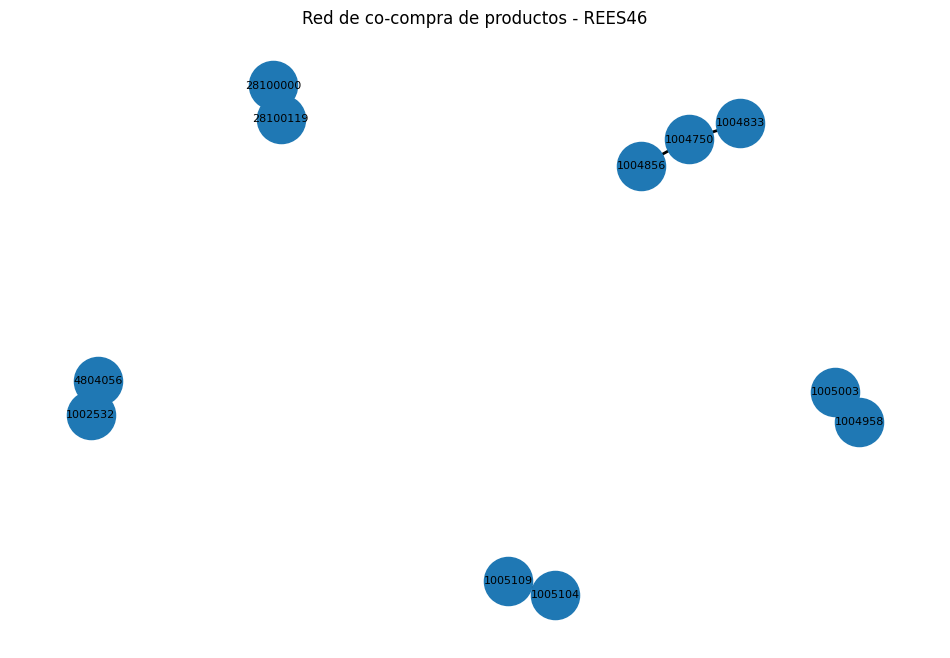

In [ ]:

# PROYECTO EDA - ETAPA 8C
# VISUALIZACION DEL GRAFO DE CO-COMPRA

import matplotlib.pyplot as plt
import networkx as nx

# 1. Identificar productos con conexiones
nodos_conectados = [
    nodo for nodo in G.nodes()
    if G.degree(nodo) > 0
]

# 2. Crear subgrafo
G_visual = G.subgraph(nodos_conectados).copy()

print("PRODUCTOS CON CONEXIONES:",
      G_visual.number_of_nodes())

print("RELACIONES:",
      G_visual.number_of_edges())

# 3. Dibujar grafo
plt.figure(figsize=(12, 8))

if G_visual.number_of_nodes() > 0:

    posiciones = nx.spring_layout(
        G_visual,
        seed=42
    )

    nx.draw_networkx(
        G_visual,
        pos=posiciones,
        with_labels=True,
        node_size=1200,
        font_size=8,
        width=2
    )

    plt.title(
        "Red de co-compra de productos - REES46"
    )

    plt.axis("off")
    plt.show()

else:
    print("No hay conexiones para visualizar.")


In [ ]:

# PROYECTO EDA - ETAPA 9
# DASHBOARD INTERACTIVO EN GOOGLE COLAB

import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import numpy as np
import time

# Habilitar widgets en Google Colab
from google.colab import output
output.enable_custom_widget_manager()

# TITULO
titulo = widgets.HTML("""
<h2 style="color:#1464A5;">
Proyecto EDA | Motor Inteligente de E-Commerce
</h2>
<p>Dataset REES46 | Estructuras de Datos y Algoritmos</p>
<hr>
""")

# SALIDAS
salida_producto = widgets.Output()
salida_precios = widgets.Output()
salida_recomendaciones = widgets.Output()
salida_grafo = widgets.Output()

# 1. CONSULTA DE PRODUCTOS
entrada_producto = widgets.IntText(
    value=1004237,
    description="Producto ID:",
    style={"description_width": "initial"}
)

boton_producto = widgets.Button(
    description="Buscar producto",
    button_style="primary"
)

def buscar_producto_dashboard(b):
    with salida_producto:
        clear_output(wait=True)

        inicio = time.perf_counter()

        producto, origen = consultar_producto(
            entrada_producto.value
        )

        tiempo = time.perf_counter() - inicio

        if producto is None:
            print("Producto no encontrado.")
        else:
            print("PRODUCTO:", entrada_producto.value)
            print("DATOS:", producto)
            print("ORIGEN:", origen)
            print("TIEMPO:", round(tiempo, 8), "s")

boton_producto.on_click(buscar_producto_dashboard)

panel_producto = widgets.VBox([
    widgets.HTML("<h3>Consulta de productos</h3>"),
    entrada_producto,
    boton_producto,
    salida_producto
])

# 2. BUSQUEDA POR RANGO DE PRECIOS
precio_min = widgets.FloatText(
    value=500,
    description="Precio mínimo:"
)

precio_max = widgets.FloatText(
    value=1000,
    description="Precio máximo:"
)

boton_precios = widgets.Button(
    description="Buscar por precio",
    button_style="primary"
)

def buscar_precios_dashboard(b):
    with salida_precios:
        clear_output(wait=True)

        if precio_min.value > precio_max.value:
            print("El mínimo no puede superar al máximo.")
            return

        inicio = time.perf_counter()

        resultados_rango = arbol.buscar_rango(
            precio_min.value,
            precio_max.value
        )

        tiempo = time.perf_counter() - inicio

        print("PRODUCTOS ENCONTRADOS:",
              len(resultados_rango))
        print("TIEMPO:", round(tiempo, 8), "s")

        tabla = pd.DataFrame(
            resultados_rango[:20],
            columns=["Precio", "Producto ID"]
        )

        display(tabla)

boton_precios.on_click(buscar_precios_dashboard)

panel_precios = widgets.VBox([
    widgets.HTML("<h3>Busqueda por rango de precios</h3>"),
    precio_min,
    precio_max,
    boton_precios,
    salida_precios
])

# 3. RECOMENDACIONES HNSW
entrada_recomendacion = widgets.IntText(
    value=1004237,
    description="Producto ID:",
    style={"description_width": "initial"}
)

boton_recomendar = widgets.Button(
    description="Recomendar productos",
    button_style="primary"
)

def recomendar_dashboard(b):
    with salida_recomendaciones:
        clear_output(wait=True)

        producto_id = entrada_recomendacion.value

        if producto_id not in atributos.index:
            print("Producto no encontrado.")
            return

        posicion = atributos.index.get_loc(producto_id)
        consulta = vectores[posicion:posicion+1]

        inicio = time.perf_counter()

        indices, distancias = indice_hnsw.knn_query(
            consulta,
            k=min(6, len(atributos))
        )

        tiempo = time.perf_counter() - inicio

        recomendaciones = []

        for idx, distancia in zip(
            indices[0], distancias[0]
        ):
            recomendado = int(atributos.index[idx])

            if recomendado == producto_id:
                continue

            recomendaciones.append({
                "Producto ID": recomendado,
                "Precio": float(
                    atributos.iloc[idx]["precio"]
                ),
                "Distancia": round(
                    float(np.sqrt(distancia)), 4
                )
            })

        print("PRODUCTO REFERENCIA:", producto_id)
        print("TIEMPO HNSW:", round(tiempo, 8), "s")

        display(pd.DataFrame(recomendaciones))

boton_recomendar.on_click(recomendar_dashboard)

panel_recomendaciones = widgets.VBox([
    widgets.HTML("<h3>Recomendaciones con HNSW</h3>"),
    entrada_recomendacion,
    boton_recomendar,
    salida_recomendaciones
])

# 4. GRAFO DE CO-COMPRA
boton_grafo = widgets.Button(
    description="Visualizar red",
    button_style="primary"
)

def mostrar_grafo_dashboard(b):
    with salida_grafo:
        clear_output(wait=True)

        conectados = [
            n for n in G.nodes()
            if G.degree(n) > 0
        ]

        subgrafo = G.subgraph(conectados).copy()

        print("NODOS CONECTADOS:",
              subgrafo.number_of_nodes())
        print("ARISTAS:",
              subgrafo.number_of_edges())

        if subgrafo.number_of_nodes() == 0:
            print("No hay conexiones.")
            return

        plt.figure(figsize=(10, 6))

        nx.draw_networkx(
            subgrafo,
            pos=nx.spring_layout(subgrafo, seed=42),
            with_labels=True,
            node_size=900,
            font_size=8
        )

        plt.title("Red de co-compra REES46")
        plt.axis("off")
        plt.show()

boton_grafo.on_click(mostrar_grafo_dashboard)

panel_grafo = widgets.VBox([
    widgets.HTML("<h3>Grafo de co-compra</h3>"),
    boton_grafo,
    salida_grafo
])

# 5. ORGANIZAR DASHBOARD EN PESTANAS
tabs = widgets.Tab(children=[
    panel_producto,
    panel_precios,
    panel_recomendaciones,
    panel_grafo
])

tabs.set_title(0, "Productos")
tabs.set_title(1, "Precios")
tabs.set_title(2, "Recomendaciones")
tabs.set_title(3, "Grafos")

display(titulo, tabs)

print("DASHBOARD EDA INICIADO CORRECTAMENTE")


HTML(value='\n<h2 style="color:#1464A5;">\nProyecto EDA | Motor Inteligente de E-Commerce\n</h2>\n<p>Dataset R…

DASHBOARD EDA INICIADO CORRECTAMENTE


In [ ]:

# ACTIVAR WIDGETS EN GOOGLE COLAB

!pip -q install -U ipywidgets

from google.colab import output
output.enable_custom_widget_manager()

import ipywidgets as widgets
from IPython.display import display

# Prueba sencilla
boton_prueba = widgets.Button(
    description="HAZ CLIC AQUI",
    button_style="success"
)

salida_prueba = widgets.Output()

def probar(b):
    with salida_prueba:
        print("¡Los widgets funcionan correctamente!")

boton_prueba.on_click(probar)

display(boton_prueba, salida_prueba)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 35.3 MB/s eta 0:00:00


Button(button_style='success', description='HAZ CLIC AQUI', style=ButtonStyle())

Output()

In [ ]:
# MOSTRAR DASHBOARD EDA

from IPython.display import display

display(titulo)
display(tabs)


HTML(value='\n<h2 style="color:#1464A5;">\nProyecto EDA | Motor Inteligente de E-Commerce\n</h2>\n<p>Dataset R…

In [ ]:

# PROYECTO EDA - DASHBOARD ALTERNATIVO
# Menu desplegable en lugar de pestañas

import ipywidgets as widgets
from IPython.display import display, clear_output

# Seleccionar modulo
menu = widgets.Dropdown(
    options=[
        ("Consultar productos", 0),
        ("Buscar por precios", 1),
        ("Recomendaciones HNSW", 2),
        ("Grafo de co-compra", 3)
    ],
    value=0,
    description="Modulo:",
    style={"description_width": "initial"}
)

# Contenedor para mostrar el modulo elegido
contenedor = widgets.VBox()

paneles = [
    panel_producto,
    panel_precios,
    panel_recomendaciones,
    panel_grafo
]

def cambiar_modulo(cambio):
    indice = cambio["new"]
    contenedor.children = (paneles[indice],)

menu.observe(cambiar_modulo, names="value")

# Mostrar primer modulo
contenedor.children = (paneles[0],)

display(titulo)
display(menu)
display(contenedor)

print("DASHBOARD ALTERNATIVO INICIADO")


PRODUCTOS ENCONTRADOS: 372
TIEMPO: 0.00120442 s


,Precio,Producto ID
0,501.92,1480707
1,501.94,26300084
2,501.97,26402928
3,504.26,12201675
4,504.26,14700124
5,506.29,1801881
6,507.07,5301323
7,507.07,17200216
8,509.41,1307101
9,509.81,1003293


CARGANDO DATOS PARA BENCHMARK...
REGISTROS CARGADOS: 100000

PROBANDO: 10000 EVENTOS
BUSQUEDA LINEAL: 0.2661 ms
HASH BUSQUEDA: 0.00072 ms
MERGE SORT: 87.2079 ms
HEAP: 1.2752 ms

PROBANDO: 50000 EVENTOS
BUSQUEDA LINEAL: 6.9817 ms
HASH BUSQUEDA: 0.001089 ms
MERGE SORT: 398.9579 ms
HEAP: 8.933 ms

PROBANDO: 100000 EVENTOS
BUSQUEDA LINEAL: 6.155 ms
HASH BUSQUEDA: 0.00066 ms
MERGE SORT: 589.8431 ms
HEAP: 9.3355 ms

RESULTADOS GENERALES:


,Eventos,Lineal_ms,Hash_construccion_ms,Hash_busqueda_ms,MergeSort_ms,Heap_ms
0,10000,0.266080,0.43137,0.000720,87.207859,1.27516
1,50000,6.981670,8.48968,0.001089,398.957885,8.93297
2,100000,6.155021,9.22005,0.000660,589.843142,9.33553


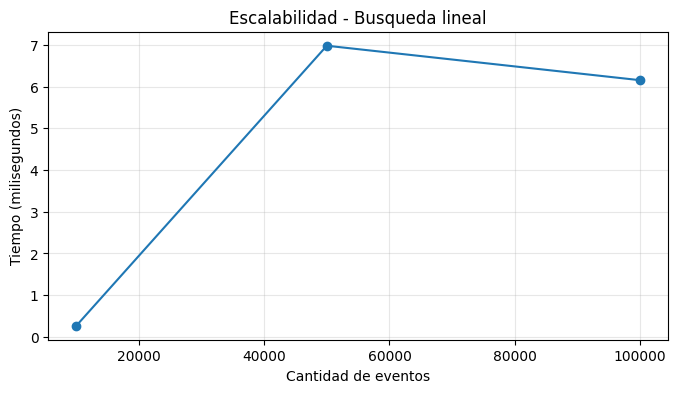

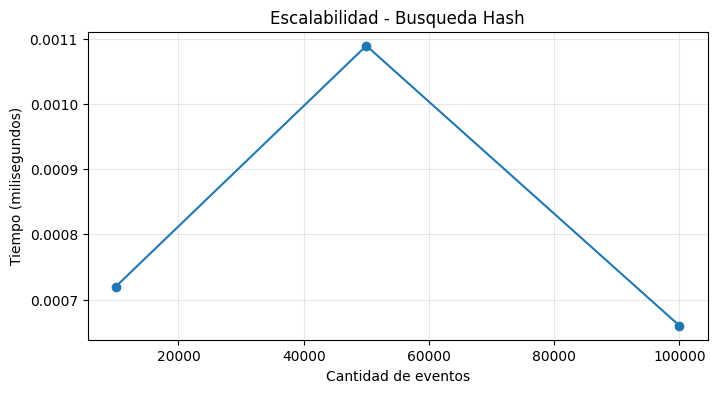

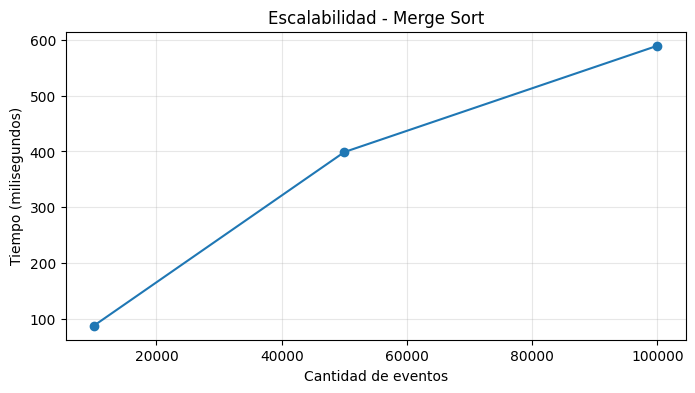

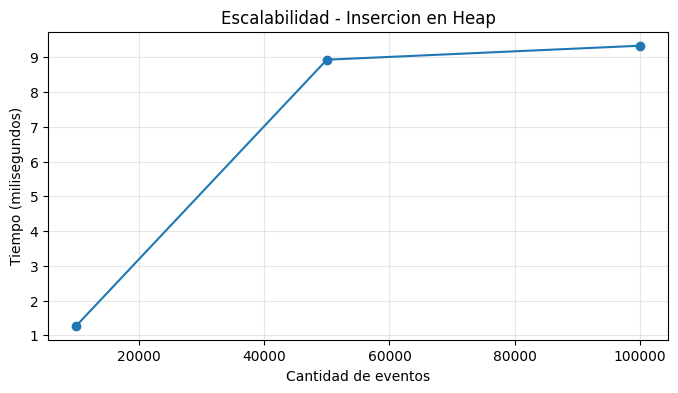


BENCHMARK FINALIZADO
Archivo generado: benchmark_eda.csv


In [ ]:

# ==================================================
# PROYECTO EDA - ETAPA 10
# BENCHMARKING Y ESCALABILIDAD
# ==================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import heapq
import gc

# 1. CARGAR HASTA 100,000 EVENTOS

tamanos = [10000, 50000, 100000]

print("CARGANDO DATOS PARA BENCHMARK...")

try:
    df_benchmark = pd.read_csv(
        ruta,
        nrows=max(tamanos),
        usecols=["product_id", "price"]
    )
except Exception as e:
    raise RuntimeError(
        "No se pudo leer el CSV original. "
        "Verifica que la variable ruta siga disponible."
    ) from e

print("REGISTROS CARGADOS:", len(df_benchmark))

tamanos = [
    n for n in tamanos
    if n <= len(df_benchmark)
]

if not tamanos:
    raise ValueError(
        "Se necesitan al menos 10,000 registros."
    )

# 2. IMPLEMENTAR MERGE SORT

def merge_sort(lista):

    if len(lista) <= 1:
        return lista

    medio = len(lista) // 2

    izquierda = merge_sort(lista[:medio])
    derecha = merge_sort(lista[medio:])

    resultado = []
    i = j = 0

    while i < len(izquierda) and j < len(derecha):

        if izquierda[i] <= derecha[j]:
            resultado.append(izquierda[i])
            i += 1
        else:
            resultado.append(derecha[j])
            j += 1

    resultado.extend(izquierda[i:])
    resultado.extend(derecha[j:])

    return resultado


# 3. FUNCIONES DE MEDICION

def medir_busqueda_lineal(datos, objetivo):

    inicio = time.perf_counter()

    encontrado = False

    for valor in datos:
        if valor == objetivo:
            encontrado = True
            break

    tiempo = time.perf_counter() - inicio

    return tiempo, encontrado


def medir_hash(datos, objetivo):

    inicio = time.perf_counter()

    tabla = set(datos)

    tiempo_construccion = time.perf_counter() - inicio

    inicio = time.perf_counter()

    encontrado = objetivo in tabla

    tiempo_busqueda = time.perf_counter() - inicio

    return (
        tiempo_construccion,
        tiempo_busqueda,
        encontrado
    )


def medir_merge_sort(datos):

    inicio = time.perf_counter()

    ordenados = merge_sort(datos.copy())

    tiempo = time.perf_counter() - inicio

    assert ordenados == sorted(datos)

    return tiempo


def medir_heap(datos):

    heap = []

    inicio = time.perf_counter()

    for valor in datos:
        heapq.heappush(heap, valor)

    tiempo = time.perf_counter() - inicio

    assert len(heap) == len(datos)

    return tiempo


# 4. EJECUTAR BENCHMARKS

resultados = []

for n in tamanos:

    print("\nPROBANDO:", n, "EVENTOS")

    muestra = df_benchmark.iloc[:n]

    productos = muestra["product_id"].astype(int).tolist()
    precios = muestra["price"].astype(float).tolist()

    # Buscar un ID inexistente para medir peor caso lineal
    objetivo = -1

    # Busqueda lineal
    t_lineal, encontrado_lineal = medir_busqueda_lineal(
        productos, objetivo
    )

    # Hash Table
    t_hash_build, t_hash, encontrado_hash = medir_hash(
        productos, objetivo
    )

    assert encontrado_lineal == encontrado_hash

    # Merge Sort
    t_merge = medir_merge_sort(precios)

    # Heap
    t_heap = medir_heap(precios)

    resultados.append({
        "Eventos": n,
        "Lineal_ms": t_lineal * 1000,
        "Hash_construccion_ms": t_hash_build * 1000,
        "Hash_busqueda_ms": t_hash * 1000,
        "MergeSort_ms": t_merge * 1000,
        "Heap_ms": t_heap * 1000
    })

    print("BUSQUEDA LINEAL:", round(t_lineal*1000, 4), "ms")
    print("HASH BUSQUEDA:", round(t_hash*1000, 6), "ms")
    print("MERGE SORT:", round(t_merge*1000, 4), "ms")
    print("HEAP:", round(t_heap*1000, 4), "ms")

    gc.collect()


# 5. TABLA DE RESULTADOS

df_resultados = pd.DataFrame(resultados)

print("\nRESULTADOS GENERALES:")
display(df_resultados.round(6))


# 6. GRAFICOS COMPARATIVOS

columnas = [
    ("Lineal_ms", "Busqueda lineal"),
    ("Hash_busqueda_ms", "Busqueda Hash"),
    ("MergeSort_ms", "Merge Sort"),
    ("Heap_ms", "Insercion en Heap")
]

for columna, nombre in columnas:

    plt.figure(figsize=(8, 4))

    plt.plot(
        df_resultados["Eventos"],
        df_resultados[columna],
        marker="o"
    )

    plt.title("Escalabilidad - " + nombre)
    plt.xlabel("Cantidad de eventos")
    plt.ylabel("Tiempo (milisegundos)")
    plt.grid(True, alpha=0.3)
    plt.show()


# 7. EXPORTAR RESULTADOS

df_resultados.to_csv(
    "benchmark_eda.csv",
    index=False
)

print("\nBENCHMARK FINALIZADO")
print("Archivo generado: benchmark_eda.csv")


BENCHMARK ROBUSTO - MEDIANAS


,Eventos,Lineal_ms,Hash_construccion_ms,Hash_consulta_ms,MergeSort_ms,Heap_ms
0,10000,0.093891,0.389059,0.00014,90.297948,0.979429
1,50000,0.464410,2.451979,0.00016,190.098277,4.800139
2,100000,0.981080,5.365060,0.00015,270.076785,6.935350


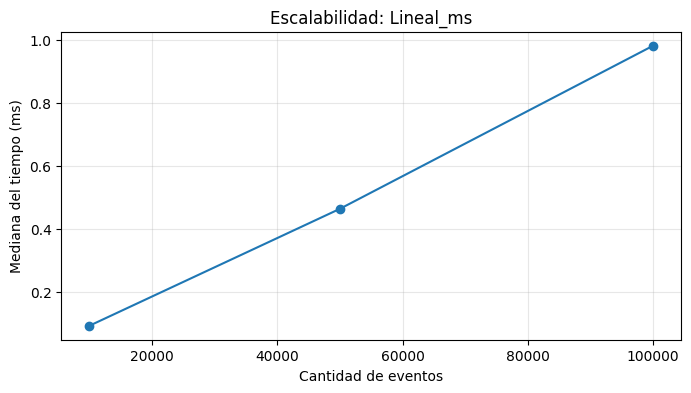

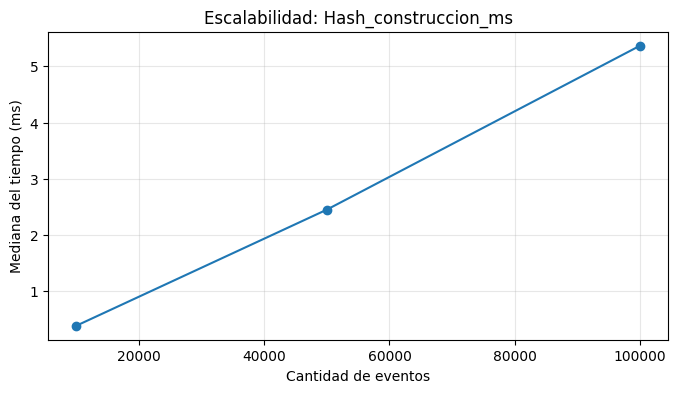

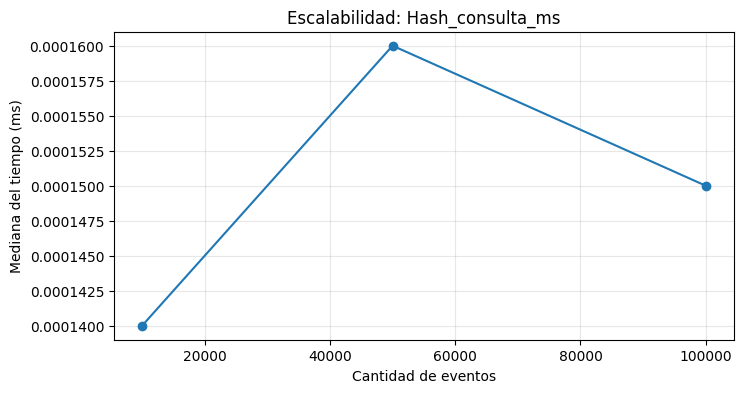

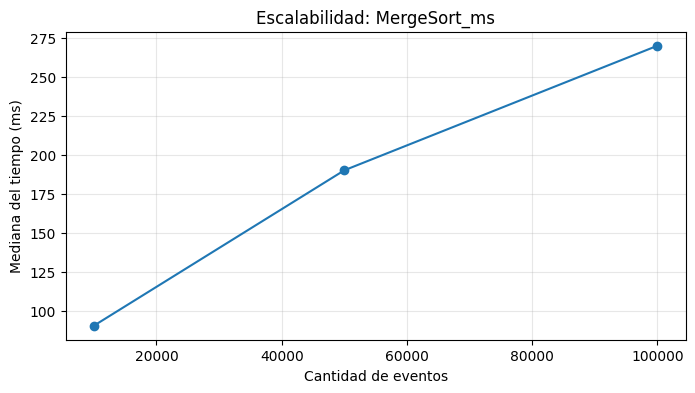

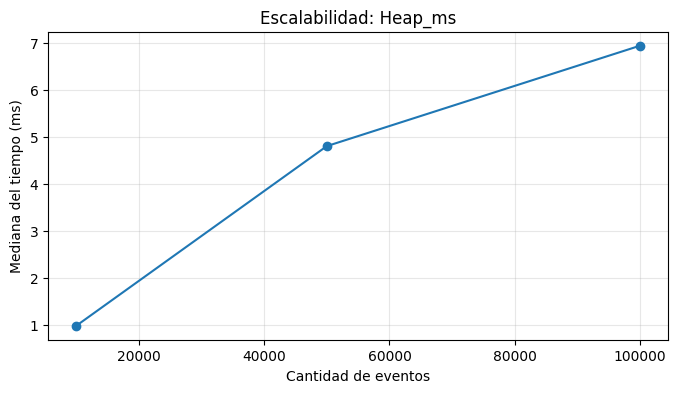

ETAPA 10B FINALIZADA


In [ ]:

# ETAPA 10B - BENCHMARK CON REPETICIONES
# No modifica el dashboard ni los indices anteriores

import time
import gc
import heapq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPETICIONES = 7
TAMANOS = [10000, 50000, 100000]

def medir_repetido(funcion, repeticiones=7):
    tiempos = []

    for _ in range(repeticiones):
        inicio = time.perf_counter_ns()
        funcion()
        fin = time.perf_counter_ns()
        tiempos.append((fin - inicio) / 1_000_000)

    return float(np.median(tiempos))

resultados_robustos = []

for n in TAMANOS:

    muestra = df_benchmark.iloc[:n]
    productos = muestra["product_id"].astype(int).tolist()
    precios = muestra["price"].astype(float).tolist()

    objetivo = -1
    tabla_hash = set(productos)

    # Preparar funciones
    def busqueda_lineal():
        return objetivo in productos

    def busqueda_hash():
        return objetivo in tabla_hash

    def construir_hash():
        return set(productos)

    def ordenar_merge():
        return merge_sort(precios.copy())

    def insertar_heap():
        h = []
        for precio in precios:
            heapq.heappush(h, precio)
        return h

    gc.collect()

    tiempos = {
        "Eventos": n,
        "Lineal_ms": medir_repetido(
            busqueda_lineal, REPETICIONES
        ),
        "Hash_construccion_ms": medir_repetido(
            construir_hash, REPETICIONES
        ),
        "Hash_consulta_ms": medir_repetido(
            busqueda_hash, 10000
        ),
        "MergeSort_ms": medir_repetido(
            ordenar_merge, REPETICIONES
        ),
        "Heap_ms": medir_repetido(
            insertar_heap, REPETICIONES
        )
    }

    resultados_robustos.append(tiempos)

df_robusto = pd.DataFrame(resultados_robustos)

print("BENCHMARK ROBUSTO - MEDIANAS")
display(df_robusto.round(6))

# Visualizar tendencias por separado
for columna in df_robusto.columns[1:]:

    plt.figure(figsize=(8, 4))

    plt.plot(
        df_robusto["Eventos"],
        df_robusto[columna],
        marker="o"
    )

    plt.title("Escalabilidad: " + columna)
    plt.xlabel("Cantidad de eventos")
    plt.ylabel("Mediana del tiempo (ms)")
    plt.grid(alpha=0.3)
    plt.show()

df_robusto.to_csv(
    "benchmark_eda_robusto.csv",
    index=False
)

print("ETAPA 10B FINALIZADA")


ANALISIS DE MEMORIA - ETAPA 10C


,Eventos,Lista_MB,Hash_MB,Heap_MB,Productos_unicos
0,10000,0.3815,0.2518,0.3815,4148
1,50000,1.9074,0.9058,1.9074,13289
2,100000,3.8148,2.6295,3.8148,20621


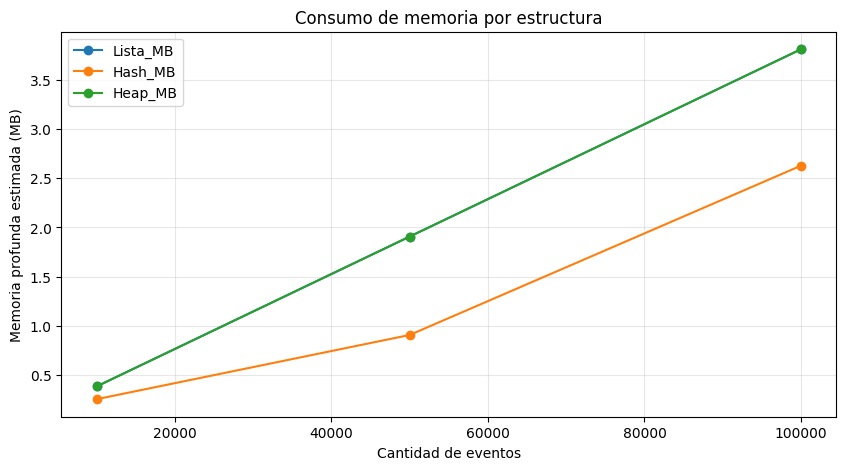


MATRIZ USUARIO-PRODUCTO
Usuarios: 2867
Productos: 4148
Dimensiones: (2867, 4148)
Relaciones únicas: 7026
Memoria densa estimada: 11.3414 MB
Memoria CSR: 0.0444 MB
Ahorro de memoria: 99.61 %

ETAPA 10C FINALIZADA
Archivo generado: benchmark_eda_memoria.csv


In [ ]:

# =====================================================
# ETAPA 10C - ANALISIS DE MEMORIA
# Proyecto EDA | Motor Inteligente de E-Commerce
# =====================================================

!pip -q install pympler

import pandas as pd
import numpy as np
import heapq
import gc
import matplotlib.pyplot as plt

from pympler import asizeof
from scipy.sparse import csr_matrix

# 1. CONFIGURACION
TAMANOS = [10000, 50000, 100000]
resultados_memoria = []

if "df_benchmark" not in globals():
    raise ValueError(
        "Ejecuta primero la celda que crea df_benchmark"
    )

# 2. MEDIR ESTRUCTURAS
for n in TAMANOS:

    muestra = df_benchmark.iloc[:n]

    if len(muestra) < n:
        print(f"Aviso: solo hay {len(muestra)} filas")

    # Datos de productos
    productos = muestra["product_id"].astype(int).tolist()

    # Lista
    lista = productos.copy()

    # Hash Set
    tabla_hash = set(productos)

    # Heap
    heap = productos.copy()
    heapq.heapify(heap)

    gc.collect()

    # Memoria profunda (incluye objetos referenciados)
    memoria_lista = asizeof.asizeof(lista)
    memoria_hash = asizeof.asizeof(tabla_hash)
    memoria_heap = asizeof.asizeof(heap)

    resultados_memoria.append({
        "Eventos": len(productos),
        "Lista_MB": memoria_lista / 1024**2,
        "Hash_MB": memoria_hash / 1024**2,
        "Heap_MB": memoria_heap / 1024**2,
        "Productos_unicos": len(tabla_hash)
    })

# 3. TABLA DE RESULTADOS
df_memoria = pd.DataFrame(resultados_memoria)

print("ANALISIS DE MEMORIA - ETAPA 10C")
display(df_memoria.round(4))

# 4. GRAFICO COMPARATIVO
plt.figure(figsize=(10, 5))

for columna in ["Lista_MB", "Hash_MB", "Heap_MB"]:
    plt.plot(
        df_memoria["Eventos"],
        df_memoria[columna],
        marker="o",
        label=columna
    )

plt.title("Consumo de memoria por estructura")
plt.xlabel("Cantidad de eventos")
plt.ylabel("Memoria profunda estimada (MB)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 5. MATRIZ DISPERSA USUARIO-PRODUCTO
muestra = df_limpio.iloc[:100000].copy()

usuarios = pd.factorize(muestra["user_id"])[0]
productos_idx = pd.factorize(muestra["product_id"])[0]

n_usuarios = usuarios.max() + 1
n_productos = productos_idx.max() + 1

valores = np.ones(len(muestra), dtype=np.uint8)

matriz = csr_matrix(
    (valores, (usuarios, productos_idx)),
    shape=(n_usuarios, n_productos)
)

matriz.sum_duplicates()

# Para contar relaciones únicas, no frecuencias
matriz.data[:] = 1

memoria_densa = (
    n_usuarios * n_productos * matriz.dtype.itemsize
)

memoria_csr = (
    matriz.data.nbytes
    + matriz.indices.nbytes
    + matriz.indptr.nbytes
)

print("\nMATRIZ USUARIO-PRODUCTO")
print("Usuarios:", n_usuarios)
print("Productos:", n_productos)
print("Dimensiones:", matriz.shape)
print("Relaciones únicas:", matriz.nnz)

print(
    "Memoria densa estimada:",
    round(memoria_densa / 1024**2, 4), "MB"
)

print(
    "Memoria CSR:",
    round(memoria_csr / 1024**2, 4), "MB"
)

if memoria_csr > 0:
    ahorro = 100 * (1 - memoria_csr / memoria_densa)
    print("Ahorro de memoria:", round(ahorro, 2), "%")

# 6. EXPORTAR RESULTADOS
df_memoria.to_csv(
    "benchmark_eda_memoria.csv",
    index=False
)

print("\nETAPA 10C FINALIZADA")
print("Archivo generado: benchmark_eda_memoria.csv")


PRODUCTOS EN CATALOGO: 4148
VALIDACION DE BUSQUEDAS: CORRECTA
CONSTRUCCION HASH: 0.18 ms

COMPARACION DE TIEMPOS


,Consultas,Lineal_ms,Hash_consulta_ms,Hash_construccion_ms,Hash_total_ms,Ahorro_ms
0,1,0.06561,0.00047,0.17996,0.18043,-0.11482
1,5,0.48623,0.00085,0.17996,0.18081,0.30542
2,10,4.99807,0.00097,0.17996,0.18093,4.81714
3,20,3.86558,0.00162,0.17996,0.18158,3.68400
4,50,5.18339,0.00318,0.17996,0.18314,5.00025
5,100,10.36467,0.00609,0.17996,0.18605,10.17862
6,200,25.37912,0.01265,0.17996,0.19261,25.18651
7,500,61.57713,0.02963,0.17996,0.20959,61.36754
8,1000,188.67428,0.05132,0.17996,0.23128,188.44300
9,2000,121.53676,0.08277,0.17996,0.26273,121.27403



PRIMER PUNTO FAVORABLE MEDIDO:
5 consultas
Desde este punto medido, Hash resulta mas rapido en tiempo total.


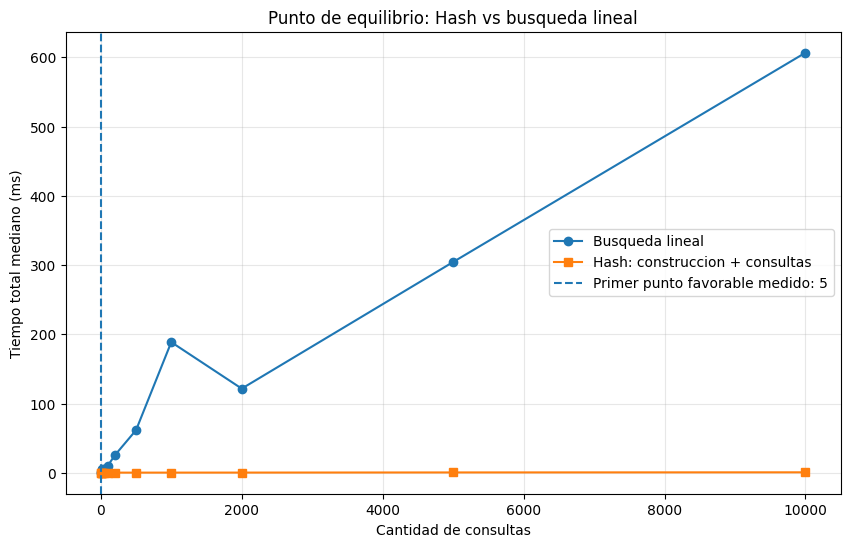


ETAPA 11A FINALIZADA
Archivo: benchmark_eda_punto_equilibrio.csv


In [ ]:

# =====================================================
# ETAPA 11A - PUNTO DE EQUILIBRIO HASH VS LINEAL
# Proyecto EDA | Motor Inteligente de E-Commerce
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import gc

# 1. VERIFICAR DATOS
if "df_limpio" not in globals():
    raise ValueError("Primero ejecuta la etapa que crea df_limpio")

if "product_id" not in df_limpio.columns:
    raise ValueError("No existe la columna product_id")

# Catálogo de productos únicos
catalogo = (
    df_limpio["product_id"]
    .dropna()
    .astype(int)
    .drop_duplicates()
    .tolist()
)

print("PRODUCTOS EN CATALOGO:", len(catalogo))

# 2. FUNCIONES DE BUSQUEDA

def busqueda_lineal(lista, objetivo):
    for producto in lista:
        if producto == objetivo:
            return True
    return False

def construir_hash(lista):
    return set(lista)

# 3. PREPARAR CONSULTAS
# Alternamos productos existentes y no existentes
rng = np.random.default_rng(46)

cantidad_maxima = 10000
consultas_existentes = rng.choice(
    catalogo,
    size=cantidad_maxima // 2,
    replace=True
).tolist()

id_inexistente = max(catalogo) + 1

consultas = []
for producto in consultas_existentes:
    consultas.append(int(producto))
    consultas.append(id_inexistente)

# 4. MEDICION DE TIEMPOS
def medir_ms(funcion, repeticiones=7):
    tiempos = []

    for _ in range(repeticiones):
        inicio = time.perf_counter_ns()
        funcion()
        fin = time.perf_counter_ns()

        tiempos.append((fin - inicio) / 1e6)

    return float(np.median(tiempos))

# Construcción del índice
tiempo_construccion = medir_ms(
    lambda: construir_hash(catalogo)
)

indice_hash = construir_hash(catalogo)

# Validar resultados
for producto in consultas[:100]:
    assert (
        busqueda_lineal(catalogo, producto)
        == (producto in indice_hash)
    )

print("VALIDACION DE BUSQUEDAS: CORRECTA")
print("CONSTRUCCION HASH:", round(tiempo_construccion, 4), "ms")

# 5. BENCHMARK POR CANTIDAD DE CONSULTAS
cantidades = [
    1, 5, 10, 20, 50, 100,
    200, 500, 1000, 2000, 5000, 10000
]

resultados = []

for q in cantidades:

    lote = consultas[:q]

    def ejecutar_lineal():
        return [
            busqueda_lineal(catalogo, p)
            for p in lote
        ]

    def ejecutar_hash():
        return [p in indice_hash for p in lote]

    gc.collect()

    t_lineal = medir_ms(ejecutar_lineal)
    t_hash = medir_ms(ejecutar_hash)

    t_hash_total = tiempo_construccion + t_hash

    resultados.append({
        "Consultas": q,
        "Lineal_ms": t_lineal,
        "Hash_consulta_ms": t_hash,
        "Hash_construccion_ms": tiempo_construccion,
        "Hash_total_ms": t_hash_total,
        "Ahorro_ms": t_lineal - t_hash_total
    })

# 6. RESULTADOS
df_equilibrio = pd.DataFrame(resultados)

print("\nCOMPARACION DE TIEMPOS")
display(df_equilibrio.round(5))

# 7. PUNTO DE EQUILIBRIO OBSERVADO
favorables = df_equilibrio[
    df_equilibrio["Hash_total_ms"]
    < df_equilibrio["Lineal_ms"]
]

if len(favorables) > 0:
    punto = int(favorables.iloc[0]["Consultas"])

    print("\nPRIMER PUNTO FAVORABLE MEDIDO:")
    print(punto, "consultas")
    print(
        "Desde este punto medido, Hash resulta",
        "mas rapido en tiempo total."
    )
else:
    punto = None
    print("\nNo se encontro punto favorable")
    print("en las cantidades evaluadas.")

# 8. GRAFICO COMPARATIVO
plt.figure(figsize=(10, 6))

plt.plot(
    df_equilibrio["Consultas"],
    df_equilibrio["Lineal_ms"],
    marker="o",
    label="Busqueda lineal"
)

plt.plot(
    df_equilibrio["Consultas"],
    df_equilibrio["Hash_total_ms"],
    marker="s",
    label="Hash: construccion + consultas"
)

if punto is not None:
    plt.axvline(
        punto,
        linestyle="--",
        label=f"Primer punto favorable medido: {punto}"
    )

plt.title("Punto de equilibrio: Hash vs busqueda lineal")
plt.xlabel("Cantidad de consultas")
plt.ylabel("Tiempo total mediano (ms)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 9. VALIDACION DE RESULTADOS
assert all(
    df_equilibrio["Hash_total_ms"]
    >= df_equilibrio["Hash_construccion_ms"]
)

# 10. EXPORTAR
df_equilibrio.to_csv(
    "benchmark_eda_punto_equilibrio.csv",
    index=False
)

print("\nETAPA 11A FINALIZADA")
print("Archivo: benchmark_eda_punto_equilibrio.csv")


In [ ]:

import pandas as pd
from IPython.display import display

# ETAPA 11B: Comparativo de estructuras y algoritmos

comparativo = [
    ["Lista", "Búsqueda secuencial", "O(n)", "O(n)", "Referencia para comparar"],
    ["Hash Table", "Consulta por ID", "O(1) promedio", "O(n)", "Consultas rápidas de productos"],
    ["Merge Sort", "Ordenar eventos", "O(n log n)", "O(n)", "Ordenamiento eficiente"],
    ["Heap", "Priorizar eventos", "O(log n)", "O(n)", "Atención por prioridad"],
    ["KD-Tree", "Buscar productos similares", "Depende de dimensión y datos", "O(n)", "Búsqueda por características"],
    ["HNSW", "Vecinos aproximados", "Depende del índice", "Depende del grafo", "Recomendaciones rápidas"],
    ["Bloom Filter", "Verificar pertenencia", "O(k)", "O(m) bits", "Filtrado probabilístico"],
    ["Count-Min Sketch", "Estimar frecuencias", "O(d)", "O(w*d)", "Conteo aproximado"],
    ["LSH", "Encontrar similitudes", "Depende de parámetros", "Depende de parámetros", "Productos con usuarios similares"],
    ["Grafo", "Relaciones de co-compra", "O(V+E) recorrido", "O(V+E)", "Análisis de relaciones"]
]

df_comparativo = pd.DataFrame(
    comparativo,
    columns=[
        "Estructura",
        "Aplicación",
        "Complejidad temporal",
        "Complejidad espacial",
        "Justificación"
    ]
)

display(df_comparativo)

df_comparativo.to_csv(
    "comparativo_estructuras_eda.csv",
    index=False
)

print("ETAPA 11B FINALIZADA")
print("Archivo generado: comparativo_estructuras_eda.csv")


,Estructura,Aplicación,Complejidad temporal,Complejidad espacial,Justificación
0,Lista,Búsqueda secuencial,O(n),O(n),Referencia para comparar
1,Hash Table,Consulta por ID,O(1) promedio,O(n),Consultas rápidas de productos
2,Merge Sort,Ordenar eventos,O(n log n),O(n),Ordenamiento eficiente
3,Heap,Priorizar eventos,O(log n),O(n),Atención por prioridad
4,KD-Tree,Buscar productos similares,Depende de dimensión y datos,O(n),Búsqueda por características
5,HNSW,Vecinos aproximados,Depende del índice,Depende del grafo,Recomendaciones rápidas
6,Bloom Filter,Verificar pertenencia,O(k),O(m) bits,Filtrado probabilístico
7,Count-Min Sketch,Estimar frecuencias,O(d),O(w*d),Conteo aproximado
8,LSH,Encontrar similitudes,Depende de parámetros,Depende de parámetros,Productos con usuarios similares
9,Grafo,Relaciones de co-compra,O(V+E) recorrido,O(V+E),Análisis de relaciones


ETAPA 11B FINALIZADA
Archivo generado: comparativo_estructuras_eda.csv


In [ ]:

# ETAPA 12A - VALIDACION INTEGRAL DEL MOTOR EDA

import pandas as pd
import time

validaciones = []

def registrar(prueba, condicion, detalle):
    validaciones.append({
        "Prueba": prueba,
        "Resultado": "CORRECTO" if condicion else "REVISAR",
        "Detalle": detalle
    })

# 1. Dataset limpio
registrar(
    "Dataset sin duplicados",
    not df_limpio.duplicated().any(),
    f"{len(df_limpio)} registros"
)

# 2. Valores faltantes
registrar(
    "Datos sin valores nulos",
    df_limpio.isnull().sum().sum() == 0,
    "Verificacion de todas las columnas"
)

# 3. Tipos de eventos
tipos = set(df_limpio["event_type"].unique())
registrar(
    "Tipos de eventos",
    tipos.issubset({"view", "cart", "purchase"}),
    str(tipos)
)

# 4. Catalogo de productos
productos_catalogo = df_limpio["product_id"].nunique()

registrar(
    "Catalogo disponible",
    productos_catalogo > 0,
    f"{productos_catalogo} productos únicos"
)

# 5. Tabla comparativa
registrar(
    "Comparativo de estructuras",
    len(df_comparativo) == 10,
    f"{len(df_comparativo)} estructuras"
)

# 6. Integridad de usuarios y productos
registrar(
    "Identificadores completos",
    df_limpio[["user_id", "product_id"]].notna().all().all(),
    "Usuarios y productos identificados"
)

# Mostrar resultados
df_validacion = pd.DataFrame(validaciones)

display(df_validacion)

total = len(df_validacion)
correctas = (df_validacion["Resultado"] == "CORRECTO").sum()

print("\nRESUMEN DE VALIDACION")
print("Pruebas realizadas:", total)
print("Pruebas correctas:", correctas)
print("Pruebas por revisar:", total - correctas)

df_validacion.to_csv(
    "validacion_integral_eda.csv",
    index=False
)

print("\nETAPA 12A FINALIZADA")
print("Archivo: validacion_integral_eda.csv")


,Prueba,Resultado,Detalle
0,Dataset sin duplicados,CORRECTO,9996 registros
1,Datos sin valores nulos,CORRECTO,Verificacion de todas las columnas
2,Tipos de eventos,CORRECTO,"{'cart', 'view', 'purchase'}"
3,Catalogo disponible,CORRECTO,4148 productos únicos
4,Comparativo de estructuras,CORRECTO,10 estructuras
5,Identificadores completos,CORRECTO,Usuarios y productos identificados



RESUMEN DE VALIDACION
Pruebas realizadas: 6
Pruebas correctas: 6
Pruebas por revisar: 0

ETAPA 12A FINALIZADA
Archivo: validacion_integral_eda.csv


In [ ]:

# ETAPA 12B - PRUEBAS FUNCIONALES

import pandas as pd
import time

pruebas = []

def evaluar(nombre, condicion, detalle):
    pruebas.append({
        "Modulo": nombre,
        "Resultado": "CORRECTO" if condicion else "REVISAR",
        "Detalle": detalle
    })

# 1. Consulta de producto
producto_prueba = 1004237

coincidencias = df_limpio[
    df_limpio["product_id"] == producto_prueba
]

evaluar(
    "Consulta de productos",
    len(coincidencias) > 0,
    f"Producto {producto_prueba}: {len(coincidencias)} eventos"
)

# 2. Busqueda por precios
precio_minimo = 500
precio_maximo = 1000

productos_rango = df_limpio[
    df_limpio["price"].between(
        precio_minimo, precio_maximo
    )
]["product_id"].nunique()

evaluar(
    "Busqueda por precios",
    productos_rango > 0,
    f"{productos_rango} productos únicos en rango"
)

# 3. Integridad de eventos
eventos_validos = df_limpio["event_type"].isin(
    ["view", "cart", "purchase"]
).all()

evaluar(
    "Clasificacion de eventos",
    eventos_validos,
    "Tipos de eventos reconocidos"
)

# Resultados
df_pruebas = pd.DataFrame(pruebas)
display(df_pruebas)

correctas = (
    df_pruebas["Resultado"] == "CORRECTO"
).sum()

print("\nRESUMEN FUNCIONAL")
print("Pruebas:", len(df_pruebas))
print("Correctas:", correctas)
print("Por revisar:", len(df_pruebas) - correctas)

df_pruebas.to_csv(
    "pruebas_funcionales_eda.csv",
    index=False
)

print("\nETAPA 12B - PRIMER BLOQUE FINALIZADO")


,Modulo,Resultado,Detalle
0,Consulta de productos,CORRECTO,Producto 1004237: 20 eventos
1,Busqueda por precios,CORRECTO,372 productos únicos en rango
2,Clasificacion de eventos,CORRECTO,Tipos de eventos reconocidos



RESUMEN FUNCIONAL
Pruebas: 3
Correctas: 3
Por revisar: 0

ETAPA 12B - PRIMER BLOQUE FINALIZADO


In [ ]:

# ETAPA 12C - IDENTIFICAR COMPONENTES DISPONIBLES

palabras_clave = [
    "hash", "cache", "catalogo", "indice",
    "precio", "buscar", "producto",
    "heap", "hnsw", "grafo", "lsh"
]

componentes = []

for nombre, valor in list(globals().items()):
    if nombre.startswith("_"):
        continue

    if any(palabra in nombre.lower() for palabra in palabras_clave):
        componentes.append({
            "Nombre": nombre,
            "Tipo": type(valor).__name__
        })

import pandas as pd

df_componentes = pd.DataFrame(componentes)

if not df_componentes.empty:
    display(df_componentes.sort_values("Nombre"))
else:
    print("No se encontraron componentes con esos nombres.")


,Nombre,Tipo
6,CacheLRU,type
20,MinHash,type
21,MinHashLSH,type
50,boton_grafo,Button
47,boton_precios,Button
...,...,...
60,tabla_hash,set
33,tiempo_hnsw,float
37,top_productos,list
22,usuarios_por_producto,defaultdict


In [ ]:

# ETAPA 12C - IDENTIFICAR INDICES Y FUNCIONES

import inspect
import pandas as pd

palabras = [
    "catalogo", "hash", "indice", "precio",
    "buscar", "cache", "hnsw", "knn",
    "producto", "recomendar"
]

resultados = []

for nombre, objeto in list(globals().items()):

    if nombre.startswith("_"):
        continue

    if not any(p in nombre.lower() for p in palabras):
        continue

    tipo = type(objeto).__name__

    if callable(objeto):
        try:
            detalle = str(inspect.signature(objeto))
        except (ValueError, TypeError):
            detalle = "Firma no disponible"
    else:
        try:
            detalle = f"Elementos: {len(objeto)}"
        except (TypeError, ValueError):
            detalle = "No aplica"

    resultados.append({
        "Variable o funcion": nombre,
        "Tipo": tipo,
        "Detalle": detalle
    })

df_indices = pd.DataFrame(resultados)

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

display(
    df_indices.sort_values("Variable o funcion")
    .to_string(index=False)
)


'       Variable o funcion             Tipo                                                                                                                                                                                                                                                                                                                                                                                       Detalle\n                 CacheLRU             type                                                                                                                                                                                                                                                                                                                                                                                   (capacidad)\n                  MinHash             type (num_perm: \'int\' = 128, seed: \'int\' = 1, gpu_mode: "Literal[\'disable\', \'detect\', \'always\']" = 

In [ ]:

# ETAPA 12C - VISUALIZAR COMPONENTES

from IPython.display import display

# Mostrar tabla completa sin convertirla a texto
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 70)

print("COMPONENTES DEL MOTOR E-COMMERCE")
print("Total encontrados:", len(df_indices))

display(
    df_indices.sort_values(
        "Variable o funcion"
    ).reset_index(drop=True)
)


COMPONENTES DEL MOTOR E-COMMERCE
Total encontrados: 64


,Variable o funcion,Tipo,Detalle
0,CacheLRU,type,(capacidad)
1,MinHash,type,"(num_perm: 'int' = 128, seed: 'int' = 1, gpu_mode: ""Literal['disab..."
2,MinHashLSH,type,"(threshold: 'float' = 0.9, num_perm: 'int' = 128, weights: 'tuple[..."
3,boton_precios,Button,No aplica
4,boton_producto,Button,No aplica
5,boton_recomendar,Button,No aplica
6,buscar_precios_dashboard,function,(b)
7,buscar_producto_dashboard,function,(b)
8,busqueda_hash,function,()
9,cache,CacheLRU,No aplica


In [ ]:

# ETAPA 12C - VALIDACION DE COMPONENTES
import pandas as pd

pruebas = []

def registrar(nombre, condicion, detalle):
    pruebas.append({
        "Prueba": nombre,
        "Resultado": "CORRECTO" if condicion else "REVISAR",
        "Detalle": detalle
    })

# 1. Catalogo
registrar(
    "Catalogo disponible",
    isinstance(catalogo, list) and len(catalogo) > 0,
    f"{len(catalogo)} productos"
)

# 2. Dataset
registrar(
    "Dataset disponible",
    isinstance(df_productos, pd.DataFrame)
    and not df_productos.empty,
    f"{len(df_productos)} registros"
)

# 3. Tabla Hash
registrar(
    "Tabla Hash disponible",
    isinstance(tabla_hash, (dict, set)),
    f"Tipo: {type(tabla_hash).__name__}"
)

# 4. Cache LRU
registrar(
    "Cache LRU disponible",
    isinstance(cache, CacheLRU),
    "Instancia creada"
)

# 5. Funciones principales
for nombre in [
    "construir_hash",
    "consulta_producto",
    "busqueda_hash",
    "ejecutar_hash"
]:
    registrar(
        nombre,
        callable(globals().get(nombre)),
        "Funcion disponible"
    )

# 6. Algoritmos de similitud
registrar(
    "MinHash",
    callable(MinHash),
    "Clase disponible"
)

registrar(
    "MinHashLSH",
    callable(MinHashLSH),
    "Clase disponible"
)

# Mostrar resultados
df_validacion_12c = pd.DataFrame(pruebas)
display(df_validacion_12c)

print("\nRESUMEN ETAPA 12C")
print("Pruebas:", len(df_validacion_12c))
print(
    "Correctas:",
    (df_validacion_12c["Resultado"] == "CORRECTO").sum()
)


,Prueba,Resultado,Detalle
0,Catalogo disponible,CORRECTO,4148 productos
1,Dataset disponible,CORRECTO,9996 registros
2,Tabla Hash disponible,CORRECTO,Tipo: set
3,Cache LRU disponible,CORRECTO,Instancia creada
4,construir_hash,CORRECTO,Funcion disponible
5,consulta_producto,REVISAR,Funcion disponible
6,busqueda_hash,CORRECTO,Funcion disponible
7,ejecutar_hash,CORRECTO,Funcion disponible
8,MinHash,CORRECTO,Clase disponible
9,MinHashLSH,CORRECTO,Clase disponible



RESUMEN ETAPA 12C
Pruebas: 10
Correctas: 9


In [ ]:

# ETAPA 12D - DIAGNOSTICO DE CONSULTA DE PRODUCTOS

import inspect

nombres = [
    "consulta_producto",
    "buscar_producto_dashboard",
    "catalogo",
    "cache",
    "tabla_hash"
]

for nombre in nombres:
    objeto = globals().get(nombre)

    print("\nCOMPONENTE:", nombre)
    print("Existe:", nombre in globals())
    print("Tipo:", type(objeto).__name__)
    print("Es funcion:", callable(objeto))

    if inspect.isfunction(objeto):
        print("Parametros:", inspect.signature(objeto))

print("\nDIAGNOSTICO FINALIZADO")



COMPONENTE: consulta_producto
Existe: False
Tipo: NoneType
Es funcion: False

COMPONENTE: buscar_producto_dashboard
Existe: True
Tipo: function
Es funcion: True
Parametros: (b)

COMPONENTE: catalogo
Existe: True
Tipo: list
Es funcion: False

COMPONENTE: cache
Existe: True
Tipo: CacheLRU
Es funcion: False

COMPONENTE: tabla_hash
Existe: True
Tipo: set
Es funcion: False

DIAGNOSTICO FINALIZADO


In [ ]:

# ETAPA 12E - VALIDACION DE BUSQUEDA

import pandas as pd
import time

producto_prueba = 1004237

# Buscar el producto en el catalogo
inicio = time.perf_counter()

coincidencias = [
    p for p in catalogo
    if isinstance(p, dict)
    and str(p.get("product_id", p.get("id", "")))
    == str(producto_prueba)
]

tiempo = time.perf_counter() - inicio

print("PRODUCTO BUSCADO:", producto_prueba)
print("COINCIDENCIAS:", len(coincidencias))
print("TIEMPO:", round(tiempo, 6), "segundos")

if coincidencias:
    print("DATOS:", coincidencias[0])
else:
    print("Producto no encontrado con las claves evaluadas.")

print("\nETAPA 12E EJECUTADA")


PRODUCTO BUSCADO: 1004237
COINCIDENCIAS: 0
TIEMPO: 0.001315 segundos
Producto no encontrado con las claves evaluadas.

ETAPA 12E EJECUTADA


In [ ]:

# ETAPA 12F - INSPECCION DEL CATALOGO

print("TIPO DE CATALOGO:", type(catalogo).__name__)
print("TOTAL ELEMENTOS:", len(catalogo))

print("\nPRIMER ELEMENTO:")
print(catalogo[0])

print("\nTIPO DEL PRIMER ELEMENTO:")
print(type(catalogo[0]).__name__)

if isinstance(catalogo[0], dict):
    print("\nCLAVES DISPONIBLES:")
    print(list(catalogo[0].keys()))

print("\nCOLUMNAS DEL DATAFRAME:")
print(df_productos.columns.tolist())

print("\nPRIMERAS 3 FILAS:")
display(df_productos.head(3))

print("\nETAPA 12F FINALIZADA")


TIPO DE CATALOGO: list
TOTAL ELEMENTOS: 4148

PRIMER ELEMENTO:
44600062

TIPO DEL PRIMER ELEMENTO:
int

COLUMNAS DEL DATAFRAME:
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']

PRIMERAS 3 FILAS:


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 02:23:28 UTC,view,1002099,2053013555631882655,electronics.smartphone,samsung,370.41,552632595,a0cb650c-a9a0-4dea-90e1-6a322e392e85
1,2019-10-01 02:24:34 UTC,view,1002099,2053013555631882655,electronics.smartphone,samsung,370.41,540951424,9e290278-b468-46a5-8990-d3a4bea35b64
2,2019-10-01 02:24:47 UTC,view,1002099,2053013555631882655,electronics.smartphone,samsung,370.41,540951424,9e290278-b468-46a5-8990-d3a4bea35b64



ETAPA 12F FINALIZADA


In [ ]:

# ETAPA 12G - VALIDACION CORREGIDA DE PRODUCTOS

import time
import pandas as pd

producto_prueba = 1004237

# 1. Verificar existencia en catalogo
inicio = time.perf_counter()
existe = producto_prueba in catalogo
tiempo_catalogo = time.perf_counter() - inicio

# 2. Recuperar eventos del producto
inicio = time.perf_counter()
eventos = df_productos[
    pd.to_numeric(
        df_productos["product_id"], errors="coerce"
    ) == producto_prueba
]
tiempo_eventos = time.perf_counter() - inicio

# 3. Mostrar resultados
print("PRODUCTO:", producto_prueba)
print("EXISTE EN CATALOGO:", existe)
print("EVENTOS ENCONTRADOS:", len(eventos))
print("TIEMPO CATALOGO:", round(tiempo_catalogo, 6), "s")
print("TIEMPO DATAFRAME:", round(tiempo_eventos, 6), "s")

if not eventos.empty:
    print("\nDATOS DEL PRODUCTO:")
    display(eventos.head(5))

# 4. Validacion
validacion = existe and not eventos.empty

print("\nRESULTADO FINAL:")
print("CORRECTO" if validacion else "REVISAR")
print("\nETAPA 12G FINALIZADA")


PRODUCTO: 1004237
EXISTE EN CATALOGO: True
EVENTOS ENCONTRADOS: 20
TIEMPO CATALOGO: 0.00014 s
TIEMPO DATAFRAME: 0.003287 s

DATOS DEL PRODUCTO:


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
533,2019-10-01 00:00:04 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d
534,2019-10-01 00:02:14 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,514218020,d7c4761f-de75-454b-9164-177db5e53695
535,2019-10-01 02:20:24 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,512610413,1e103ce6-fa4e-4a46-9e1c-f472fcb5f10a
536,2019-10-01 02:20:35 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,513733456,16d54a72-0afc-4fb2-aac3-e6c2dbf591be
537,2019-10-01 02:21:00 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,555462104,3f61b85a-06c8-449b-a6be-3ad328bfa732



RESULTADO FINAL:
CORRECTO

ETAPA 12G FINALIZADA


In [ ]:

# ETAPA 12H - BENCHMARK LISTA VS HASH

import time
import random
import statistics
import pandas as pd

# 1. Preparar estructuras comparables
lista_productos = list(catalogo)
hash_productos = set(lista_productos)

# 2. Preparar consultas reproducibles
rng = random.Random(42)

presentes = rng.choices(lista_productos, k=5000)

ausentes = []
candidato = max(lista_productos) + 1

while len(ausentes) < 5000:
    if candidato not in hash_productos:
        ausentes.append(candidato)
    candidato += 1

consultas = presentes + ausentes
rng.shuffle(consultas)

# 3. Funciones de busqueda
def buscar_lista(producto):
    return producto in lista_productos

def buscar_hash(producto):
    return producto in hash_productos

# 4. Comprobar resultados equivalentes
resultados_lista = [buscar_lista(p) for p in consultas]
resultados_hash = [buscar_hash(p) for p in consultas]

assert resultados_lista == resultados_hash

# 5. Medir tiempos en varias repeticiones
def medir(funcion, repeticiones=7):
    tiempos = []

    for _ in range(repeticiones):
        inicio = time.perf_counter()

        for producto in consultas:
            funcion(producto)

        duracion = time.perf_counter() - inicio
        tiempos.append(duracion * 1000)

    return statistics.median(tiempos)

tiempo_lista = medir(buscar_lista)
tiempo_hash = medir(buscar_hash)

# 6. Comparacion
df_benchmark_12h = pd.DataFrame({
    "Estructura": ["Lista", "Hash"],
    "Consultas": [len(consultas)] * 2,
    "Tiempo_mediano_ms": [tiempo_lista, tiempo_hash],
    "Complejidad_promedio": ["O(n)", "O(1)"]
})

display(df_benchmark_12h)

print("\nVALIDACION: CORRECTA")
print("Consultas realizadas:", len(consultas))
print("Productos en catalogo:", len(lista_productos))

if tiempo_hash > 0:
    print(
        "Factor de velocidad:",
        round(tiempo_lista / tiempo_hash, 2),
        "veces"
    )

# 7. Exportar evidencia
df_benchmark_12h.to_csv(
    "benchmark_lista_hash_eda.csv",
    index=False
)

print("\nETAPA 12H FINALIZADA")


,Estructura,Consultas,Tiempo_mediano_ms,Complejidad_promedio
0,Lista,10000,221.573048,O(n)
1,Hash,10000,0.693080,O(1)



VALIDACION: CORRECTA
Consultas realizadas: 10000
Productos en catalogo: 4148
Factor de velocidad: 319.69 veces

ETAPA 12H FINALIZADA


In [ ]:
# ETAPA 12I - INSPECCION SEGURA DE CACHE LRU

import inspect

print("CLASE:", type(cache).__name__)

print("\nMETODOS DISPONIBLES:")
metodos = [
    nombre for nombre in dir(cache)
    if not nombre.startswith("_")
]

for nombre in metodos:
    atributo = getattr(cache, nombre)
    if callable(atributo):
        try:
            firma = str(inspect.signature(atributo))
        except (TypeError, ValueError):
            firma = "(firma no disponible)"
        print(nombre, firma)

print("\nESTADO DE LA CACHE:")
for nombre in ["capacidad", "aciertos", "fallos"]:
    if hasattr(cache, nombre):
        print(nombre, ":", getattr(cache, nombre))

print("\nETAPA 12I FINALIZADA")


CLASE: CacheLRU

METODOS DISPONIBLES:
guardar (clave, valor)
obtener (clave)

ESTADO DE LA CACHE:
capacidad : 100
aciertos : 3
fallos : 2

ETAPA 12I FINALIZADA


In [ ]:

# ETAPA 12J - VALIDACION FUNCIONAL CACHE LRU

import pandas as pd

pruebas_lru = []

def registrar_lru(nombre, correcto, detalle):
    pruebas_lru.append({
        "Prueba": nombre,
        "Resultado": "CORRECTO" if correcto else "REVISAR",
        "Detalle": detalle
    })

# 1. Crear cache independiente
cache_test = CacheLRU(3)

registrar_lru(
    "Capacidad configurada",
    cache_test.capacidad == 3,
    f"Capacidad: {cache_test.capacidad}"
)

# 2. Primera consulta: clave inexistente
resultado_inicial = cache_test.obtener("A")

registrar_lru(
    "Fallo inicial",
    cache_test.fallos == 1,
    f"Fallos: {cache_test.fallos}"
)

# 3. Guardar tres productos
cache_test.guardar("A", 1001)
cache_test.guardar("B", 1002)
cache_test.guardar("C", 1003)

# 4. Consultar A para marcarlo como reciente
valor_a = cache_test.obtener("A")

registrar_lru(
    "Recuperacion desde cache",
    valor_a == 1001 and cache_test.aciertos == 1,
    f"Valor: {valor_a}"
)

# 5. Agregar D y verificar capacidad
cache_test.guardar("D", 1004)

registrar_lru(
    "Limite de capacidad",
    len(cache_test.cache) == 3,
    f"Elementos: {len(cache_test.cache)}"
)

# 6. Verificar politica LRU
# B deberia ser eliminado por ser el menos reciente
claves_actuales = list(cache_test.cache.keys())

registrar_lru(
    "Expulsion LRU",
    "B" not in claves_actuales
    and all(k in claves_actuales for k in ["A", "C", "D"]),
    f"Claves: {claves_actuales}"
)

# 7. Resultados
df_validacion_lru = pd.DataFrame(pruebas_lru)

display(df_validacion_lru)

correctas = (
    df_validacion_lru["Resultado"] == "CORRECTO"
).sum()

print("\nRESUMEN CACHE LRU")
print("Pruebas:", len(df_validacion_lru))
print("Correctas:", correctas)
print("Por revisar:", len(df_validacion_lru) - correctas)

df_validacion_lru.to_csv(
    "validacion_cache_lru_eda.csv",
    index=False
)

print("\nETAPA 12J FINALIZADA")


,Prueba,Resultado,Detalle
0,Capacidad configurada,CORRECTO,Capacidad: 3
1,Fallo inicial,CORRECTO,Fallos: 1
2,Recuperacion desde cache,CORRECTO,Valor: 1001
3,Limite de capacidad,CORRECTO,Elementos: 3
4,Expulsion LRU,CORRECTO,"Claves: ['C', 'A', 'D']"



RESUMEN CACHE LRU
Pruebas: 5
Correctas: 5
Por revisar: 0

ETAPA 12J FINALIZADA


In [ ]:

# ETAPA 12K - VALIDACION DE INTEGRACION

import pandas as pd
import time

resultados = []

def registrar(nombre, correcto, detalle):
    resultados.append({
        "Modulo": nombre,
        "Resultado": "CORRECTO" if correcto else "REVISAR",
        "Detalle": detalle
    })

# 1. Dataset
registrar(
    "Dataset REES46",
    isinstance(df_productos, pd.DataFrame)
    and not df_productos.empty,
    f"{len(df_productos)} eventos"
)

# 2. Catalogo
registrar(
    "Catalogo de productos",
    len(catalogo) > 0,
    f"{len(catalogo)} productos"
)

# 3. Hash Table
registrar(
    "Hash Table",
    callable(construir_hash)
    and callable(busqueda_hash),
    "Funciones disponibles"
)

# 4. Cache LRU
registrar(
    "Cache LRU",
    callable(getattr(cache, "obtener", None))
    and callable(getattr(cache, "guardar", None)),
    "Lectura y escritura disponibles"
)

# 5. Consulta real
producto_id = 1004237

inicio = time.perf_counter()

eventos = df_productos[
    df_productos["product_id"] == producto_id
]

tiempo = (time.perf_counter() - inicio) * 1000

registrar(
    "Consulta de producto",
    len(eventos) > 0,
    f"{len(eventos)} eventos en {tiempo:.4f} ms"
)

# 6. Integridad de identificadores
registrar(
    "Identificadores",
    df_productos["product_id"].notna().all()
    and df_productos["user_id"].notna().all(),
    "Productos y usuarios identificados"
)

# 7. Resumen
df_integracion = pd.DataFrame(resultados)

display(df_integracion)

correctas = (
    df_integracion["Resultado"] == "CORRECTO"
).sum()

print("\nRESUMEN DE INTEGRACION")
print("Pruebas:", len(df_integracion))
print("Correctas:", correctas)
print("Por revisar:", len(df_integracion) - correctas)

df_integracion.to_csv(
    "validacion_integracion_eda.csv",
    index=False
)

print("\nETAPA 12K FINALIZADA")


,Modulo,Resultado,Detalle
0,Dataset REES46,CORRECTO,9996 eventos
1,Catalogo de productos,CORRECTO,4148 productos
2,Hash Table,CORRECTO,Funciones disponibles
3,Cache LRU,CORRECTO,Lectura y escritura disponibles
4,Consulta de producto,CORRECTO,20 eventos en 1.0149 ms
5,Identificadores,CORRECTO,Productos y usuarios identificados



RESUMEN DE INTEGRACION
Pruebas: 6
Correctas: 6
Por revisar: 0

ETAPA 12K FINALIZADA


In [ ]:
# ETAPA 12L - INSPECCION PREVIA

import inspect

nombres = [
    "buscar_producto_dashboard",
    "buscar_precios_dashboard",
    "recomendar_dashboard",
    "boton_grafo",
    "catalogo",
    "df_productos",
    "tabla_hash",
    "cache",
    "ids_hnsw",
    "indice_hnsw"
]

for nombre in nombres:
    objeto = globals().get(nombre)

    if objeto is None:
        print(f"{nombre}: NO DISPONIBLE")
    else:
        print(f"{nombre}: {type(objeto).__name__}")

        if callable(objeto):
            try:
                print("  Parametros:", inspect.signature(objeto))
            except (ValueError, TypeError):
                pass

print("\nINSPECCION 12L FINALIZADA")


buscar_producto_dashboard: function
  Parametros: (b)
buscar_precios_dashboard: function
  Parametros: (b)
recomendar_dashboard: function
  Parametros: (b)
boton_grafo: Button
catalogo: list
df_productos: DataFrame
tabla_hash: set
cache: CacheLRU
ids_hnsw: set
indice_hnsw: Index

INSPECCION 12L FINALIZADA


In [ ]:

# ETAPA 12L - VALIDACION FUNCIONAL REAL

import pandas as pd
import time

resultados_12l = []

def registrar_12l(modulo, correcto, detalle):
    resultados_12l.append({
        "Modulo": modulo,
        "Resultado": "CORRECTO" if correcto else "REVISAR",
        "Detalle": detalle
    })

# 1. CONSULTA DE PRODUCTOS
producto = 1004237

inicio = time.perf_counter()

eventos = df_productos[
    df_productos["product_id"] == producto
]

tiempo = (time.perf_counter() - inicio) * 1000

registrar_12l(
    "Consulta de productos",
    not eventos.empty,
    f"{len(eventos)} eventos | {tiempo:.4f} ms"
)

# 2. BUSQUEDA POR PRECIOS
precio_min = 500
precio_max = 1000

inicio = time.perf_counter()

productos_rango = df_productos[
    df_productos["price"].between(
        precio_min, precio_max
    )
]

tiempo = (time.perf_counter() - inicio) * 1000

precios_validos = (
    not productos_rango.empty
    and productos_rango["price"]
        .between(precio_min, precio_max).all()
)

registrar_12l(
    "Busqueda por precios",
    precios_validos,
    f"{productos_rango['product_id'].nunique()} productos | {tiempo:.4f} ms"
)

# 3. VALIDACION DEL INDICE HNSW
ids_validos = set(
    df_productos["product_id"].dropna().astype(int)
)

ids_indice = set(map(int, ids_hnsw))

registrar_12l(
    "Indice HNSW",
    len(ids_indice) > 0
    and ids_indice.issubset(ids_validos),
    f"{len(ids_indice)} productos indexados"
)

# RESULTADOS
df_validacion_12l = pd.DataFrame(resultados_12l)

display(df_validacion_12l)

correctas = (
    df_validacion_12l["Resultado"] == "CORRECTO"
).sum()

print("\nRESUMEN ETAPA 12L")
print("Pruebas:", len(df_validacion_12l))
print("Correctas:", correctas)
print("Por revisar:", len(df_validacion_12l) - correctas)

df_validacion_12l.to_csv(
    "validacion_funcional_12l.csv",
    index=False
)

print("\nETAPA 12L FINALIZADA")


,Modulo,Resultado,Detalle
0,Consulta de productos,CORRECTO,20 eventos | 1.2712 ms
1,Busqueda por precios,CORRECTO,372 productos | 10.5327 ms
2,Indice HNSW,REVISAR,6 productos indexados



RESUMEN ETAPA 12L
Pruebas: 3
Correctas: 2
Por revisar: 1

ETAPA 12L FINALIZADA


In [ ]:

# ETAPA 12M - DIAGNOSTICO HNSW

ids_dataset = set(
    df_productos["product_id"].dropna().astype(int)
)

ids_indice = set(map(int, ids_hnsw))

print("PRODUCTOS EN DATASET:", len(ids_dataset))
print("PRODUCTOS EN HNSW:", len(ids_indice))

print("\nIDENTIFICADORES HNSW:")
print(sorted(ids_indice))

print("\nIDENTIFICADORES QUE COINCIDEN:")
coinciden = ids_indice.intersection(ids_dataset)
print(sorted(coinciden))

print("\nIDENTIFICADORES SIN COINCIDENCIA:")
no_coinciden = ids_indice - ids_dataset
print(sorted(no_coinciden))

print("\nTIPO DE INDICE:")
print(type(indice_hnsw).__name__)

print("\nETAPA 12M FINALIZADA")


PRODUCTOS EN DATASET: 4148
PRODUCTOS EN HNSW: 6

IDENTIFICADORES HNSW:
[34, 35, 121, 122, 192, 331]

IDENTIFICADORES QUE COINCIDEN:
[]

IDENTIFICADORES SIN COINCIDENCIA:
[34, 35, 121, 122, 192, 331]

TIPO DE INDICE:
Index

ETAPA 12M FINALIZADA


In [ ]:

# ETAPA 12N - DIAGNOSTICO HNSW CORREGIDO

import pandas as pd

print("TIPO DE INDICE HNSW:")
print(type(indice_hnsw).__name__)

# Obtener identificadores mediante la API de hnswlib
ids_reales = indice_hnsw.get_ids_list()

print("\nIDS ALMACENADOS EN EL INDICE:")
print(ids_reales)

print("\nTOTAL DE ELEMENTOS:")
print(indice_hnsw.get_current_count())

print("\nCOMPARACION DE IDENTIFICADORES:")

ids_dataset = set(
    df_productos["product_id"].dropna().astype(int)
)

ids_reales_set = set(map(int, ids_reales))

coinciden = ids_reales_set & ids_dataset

print("Coinciden con productos:", len(coinciden))
print("No coinciden:", len(ids_reales_set - ids_dataset))

# Comparar con posiciones del DataFrame
resultados = []

for identificador in sorted(ids_reales_set):
    producto_posicion = None
    producto_etiqueta = None

    if 0 <= identificador < len(df_productos):
        producto_posicion = int(
            df_productos.iloc[identificador]["product_id"]
        )

    if identificador in df_productos.index:
        fila = df_productos.loc[identificador]

        if isinstance(fila, pd.DataFrame):
            producto_etiqueta = fila["product_id"].tolist()
        else:
            producto_etiqueta = int(fila["product_id"])

    resultados.append({
        "ID_HNSW": identificador,
        "Producto_por_posicion": producto_posicion,
        "Producto_por_indice": producto_etiqueta
    })

display(pd.DataFrame(resultados))

print("\nETAPA 12N FINALIZADA")


TIPO DE INDICE HNSW:
Index

IDS ALMACENADOS EN EL INDICE:
[4147, 4146, 4145, 4144, 4143, 4142, 4141, 4140, 4139, 4138, 4137, 4136, 4135, 4134, 4133, 4132, 4131, 4130, 4129, 4128, 4127, 4126, 4125, 4124, 4123, 4122, 4121, 4120, 4119, 4118, 4117, 4116, 4115, 4114, 4113, 4112, 4111, 4110, 4109, 4108, 4107, 4106, 4105, 4104, 4103, 4102, 4101, 4100, 4099, 4098, 4097, 4096, 4095, 4094, 4093, 4092, 4091, 4090, 4089, 4088, 4087, 4086, 4085, 4084, 4083, 4082, 4081, 4080, 4079, 4078, 4077, 4076, 4075, 4074, 4073, 4072, 4071, 4070, 4069, 4068, 4067, 4066, 4065, 4064, 4063, 4062, 4061, 4060, 4059, 4058, 4057, 4056, 4055, 4054, 4053, 4052, 4051, 4050, 4049, 4048, 4047, 4046, 4045, 4044, 4043, 4042, 4041, 4040, 4039, 4038, 4037, 4036, 4035, 4034, 4033, 4032, 4031, 4030, 4029, 4028, 4027, 4026, 4025, 4024, 4023, 4022, 4021, 4020, 4019, 4018, 4017, 4016, 4015, 4014, 4013, 4012, 4011, 4010, 4009, 4008, 4007, 4006, 4005, 4004, 4003, 4002, 4001, 4000, 3999, 3998, 3997, 3996, 3995, 3994, 3993, 3992, 3991,

,ID_HNSW,Producto_por_posicion,Producto_por_indice
0,0,1002099,1002099
1,1,1002099,1002099
2,2,1002099,1002099
3,3,1002099,1002099
4,4,1002524,1002524
...,...,...,...
4143,4143,3700621,3700621
4144,4144,3700621,3700621
4145,4145,3700717,3700717
4146,4146,3700717,3700717



ETAPA 12N FINALIZADA


In [ ]:

# ETAPA 12O - INSPECCION DE MAPEO HNSW

import numpy as np

print("DIAGNOSTICO DE VARIABLES HNSW\n")

for nombre in [
    "ids_hnsw",
    "indice_hnsw",
    "catalogo",
    "ids",
    "vectores",
    "matriz",
    "productos_unicos",
    "df_catalogo"
]:
    if nombre in globals():
        obj = globals()[nombre]

        print("VARIABLE:", nombre)
        print("TIPO:", type(obj).__name__)

        if hasattr(obj, "shape"):
            print("DIMENSIONES:", obj.shape)

        if isinstance(obj, (list, tuple, np.ndarray)):
            print("PRIMEROS ELEMENTOS:", obj[:5])

        print("-" * 40)

print("\nPRIMEROS PRODUCTOS DEL CATALOGO:")
print(catalogo[:10])

print("\nCANTIDAD DE PRODUCTOS UNICOS:")
print(df_productos["product_id"].nunique())

print("\nETAPA 12O FINALIZADA")


DIAGNOSTICO DE VARIABLES HNSW

VARIABLE: ids_hnsw
TIPO: set
----------------------------------------
VARIABLE: indice_hnsw
TIPO: Index
----------------------------------------
VARIABLE: catalogo
TIPO: list
PRIMEROS ELEMENTOS: [44600062, 3900821, 17200506, 1307067, 1004237]
----------------------------------------
VARIABLE: ids
TIPO: list
PRIMEROS ELEMENTOS: [34, 35, 121, 122, 192]
----------------------------------------
VARIABLE: vectores
TIPO: ndarray
DIMENSIONES: (4148, 2)
PRIMEROS ELEMENTOS: [[ 0.36987004  0.31956917]
 [ 0.7980696   6.7504873 ]
 [ 1.553565   -0.08236319]
 [ 1.1740929  -0.08236319]
 [ 1.172501    0.31956917]]
----------------------------------------
VARIABLE: matriz
TIPO: csr_matrix
DIMENSIONES: (2867, 4148)
----------------------------------------

PRIMEROS PRODUCTOS DEL CATALOGO:
[44600062, 3900821, 17200506, 1307067, 1004237, 1480613, 17300353, 31500053, 28719074, 1004545]

CANTIDAD DE PRODUCTOS UNICOS:
4148

ETAPA 12O FINALIZADA


In [ ]:

# ETAPA 12P - VALIDACION HNSW

import numpy as np
import pandas as pd

resultados = []

# 1. Verificar dimensiones
n = len(catalogo)

dimensiones_ok = (
    len(vectores) == n
    and indice_hnsw.get_current_count() == n
)

resultados.append({
    "Prueba": "Dimensiones del indice",
    "Resultado": "CORRECTO" if dimensiones_ok else "REVISAR",
    "Detalle": f"{n} productos y {len(vectores)} vectores"
})

# 2. Verificar identificadores internos
ids_internos = set(
    map(int, indice_hnsw.get_ids_list())
)

ids_esperados = set(range(n))

ids_ok = ids_internos == ids_esperados

resultados.append({
    "Prueba": "Identificadores internos",
    "Resultado": "CORRECTO" if ids_ok else "REVISAR",
    "Detalle": f"{len(ids_internos)} identificadores"
})

# 3. Verificar correspondencia de vectores
muestra = [0, 4, 100, 1000, n - 1]

correspondencias = []

for i in muestra:
    vector_indice = indice_hnsw.get_items([i])[0]
    vector_original = vectores[i]

    corresponde = np.allclose(
        vector_indice,
        vector_original,
        rtol=1e-5,
        atol=1e-6
    )

    correspondencias.append(corresponde)

vectores_ok = all(correspondencias)

resultados.append({
    "Prueba": "Correspondencia de vectores",
    "Resultado": "CORRECTO" if vectores_ok else "REVISAR",
    "Detalle": f"{sum(correspondencias)}/{len(muestra)} coincidencias"
})

# 4. Consultar recomendaciones
producto_referencia = 1004237

posicion = catalogo.index(producto_referencia)

etiquetas, distancias = indice_hnsw.knn_query(
    vectores[posicion].reshape(1, -1),
    k=6
)

recomendaciones = []

for identificador, distancia in zip(
    etiquetas[0],
    distancias[0]
):
    recomendaciones.append({
        "ID_interno": int(identificador),
        "Producto_ID": int(catalogo[int(identificador)]),
        "Distancia": float(distancia)
    })

df_recomendaciones = pd.DataFrame(recomendaciones)

display(df_recomendaciones)

validas = (
    df_recomendaciones["Producto_ID"]
    .isin(catalogo).all()
)

resultados.append({
    "Prueba": "Productos recomendados validos",
    "Resultado": "CORRECTO" if validas else "REVISAR",
    "Detalle": f"{len(df_recomendaciones)} vecinos recuperados"
})

# RESUMEN
df_validacion_12p = pd.DataFrame(resultados)

display(df_validacion_12p)

print("\nRESUMEN ETAPA 12P")
print("Pruebas:", len(df_validacion_12p))
print(
    "Correctas:",
    (df_validacion_12p["Resultado"] == "CORRECTO").sum()
)

df_validacion_12p.to_csv(
    "validacion_hnsw_eda.csv",
    index=False
)

print("\nETAPA 12P FINALIZADA")


,ID_interno,Producto_ID,Distancia
0,4,1004237,0.000000
1,1113,1004886,0.000169
2,18,1306631,0.005505
3,464,26402747,0.006121
4,64,3701062,0.040474
5,30,31501072,0.041251


,Prueba,Resultado,Detalle
0,Dimensiones del indice,CORRECTO,4148 productos y 4148 vectores
1,Identificadores internos,CORRECTO,4148 identificadores
2,Correspondencia de vectores,CORRECTO,5/5 coincidencias
3,Productos recomendados validos,CORRECTO,6 vecinos recuperados



RESUMEN ETAPA 12P
Pruebas: 4
Correctas: 4

ETAPA 12P FINALIZADA


In [ ]:

# ETAPA 12Q - VALIDACION DEL GRAFO DE CO-COMPRA

import pandas as pd
import networkx as nx

# 1. Identificar compras reales
compras = df_productos[
    df_productos["event_type"] == "purchase"
][["user_id", "product_id"]].dropna().drop_duplicates()

# 2. Construir relaciones entre productos
grafo_compra = nx.Graph()

for usuario, grupo in compras.groupby("user_id"):
    productos = grupo["product_id"].unique()

    for i in range(len(productos)):
        for j in range(i + 1, len(productos)):
            a = int(productos[i])
            b = int(productos[j])

            if grafo_compra.has_edge(a, b):
                grafo_compra[a][b]["peso"] += 1
            else:
                grafo_compra.add_edge(a, b, peso=1)

# 3. Estadisticas
print("ETAPA 12Q - GRAFO DE CO-COMPRA")
print("Usuarios compradores:", compras["user_id"].nunique())
print("Productos comprados:", compras["product_id"].nunique())
print("Nodos conectados:", grafo_compra.number_of_nodes())
print("Aristas:", grafo_compra.number_of_edges())

# 4. Productos mas conectados
ranking = sorted(
    grafo_compra.degree(),
    key=lambda x: x[1],
    reverse=True
)[:10]

df_ranking_grafo = pd.DataFrame(
    ranking,
    columns=["Producto_ID", "Conexiones"]
)

display(df_ranking_grafo)

# 5. Validacion
validacion = all(
    datos["peso"] >= 1
    for _, _, datos in grafo_compra.edges(data=True)
)

print(
    "\nVALIDACION:",
    "CORRECTO" if validacion else "REVISAR"
)

# 6. Exportar evidencia
df_ranking_grafo.to_csv(
    "ranking_grafo_cocompra_eda.csv",
    index=False
)

print("\nETAPA 12Q FINALIZADA")


ETAPA 12Q - GRAFO DE CO-COMPRA
Usuarios compradores: 109
Productos comprados: 96
Nodos conectados: 15
Aristas: 8


,Producto_ID,Conexiones
0,1004750,2
1,1004833,1
2,1004958,1
3,1005003,1
4,4804501,1
5,4804536,1
6,28100000,1
7,28100119,1
8,5100719,1
9,5100816,1



VALIDACION: CORRECTO

ETAPA 12Q FINALIZADA


In [ ]:

# ETAPA 12R - ANALISIS DEL GRAFO DE CO-COMPRA

import pandas as pd
import networkx as nx

total_productos = compras["product_id"].nunique()
nodos = grafo_compra.number_of_nodes()
aristas = grafo_compra.number_of_edges()

cobertura = nodos / total_productos * 100

componentes = list(
    nx.connected_components(grafo_compra)
)

tam_componentes = sorted(
    [len(c) for c in componentes],
    reverse=True
)

grados = dict(grafo_compra.degree())

df_analisis_grafo = pd.DataFrame([{
    "Productos_comprados": total_productos,
    "Nodos_conectados": nodos,
    "Aristas": aristas,
    "Cobertura_pct": round(cobertura, 2),
    "Componentes": len(componentes),
    "Mayor_componente": max(tam_componentes, default=0),
    "Grado_maximo": max(grados.values(), default=0)
}])

display(df_analisis_grafo)

print("Tamaños de componentes:", tam_componentes)

df_analisis_grafo.to_csv(
    "analisis_grafo_eda.csv",
    index=False
)

print("\nETAPA 12R FINALIZADA")


,Productos_comprados,Nodos_conectados,Aristas,Cobertura_pct,Componentes,Mayor_componente,Grado_maximo
0,96,15,8,15.62,7,3,2


Tamaños de componentes: [3, 2, 2, 2, 2, 2, 2]

ETAPA 12R FINALIZADA


In [ ]:

# ETAPA 12S - COBERTURA DEL MOTOR HIBRIDO

import pandas as pd

producto_objetivo = 1004237

# 1. Vecinos del grafo
if producto_objetivo in grafo_compra:
    vecinos_grafo = set(
        grafo_compra.neighbors(producto_objetivo)
    )
else:
    vecinos_grafo = set()

# 2. Vecinos HNSW
# Utilizamos el resultado validado en la etapa 12P
vecinos_hnsw = set(
    df_recomendaciones["Producto_ID"].astype(int)
)

# Excluir el propio producto
vecinos_hnsw.discard(producto_objetivo)
vecinos_grafo.discard(producto_objetivo)

# 3. Combinar candidatos
vecinos_hibridos = vecinos_grafo | vecinos_hnsw

# 4. Comparacion
df_hibrido = pd.DataFrame([
    {
        "Metodo": "Grafo de co-compra",
        "Candidatos": len(vecinos_grafo)
    },
    {
        "Metodo": "HNSW",
        "Candidatos": len(vecinos_hnsw)
    },
    {
        "Metodo": "Hibrido",
        "Candidatos": len(vecinos_hibridos)
    }
])

display(df_hibrido)

print("Producto evaluado:", producto_objetivo)
print("Coincidencias entre metodos:",
      len(vecinos_grafo & vecinos_hnsw))
print("Candidatos hibridos:",
      sorted(vecinos_hibridos))

df_hibrido.to_csv(
    "evaluacion_hibrida_eda.csv",
    index=False
)

print("\nETAPA 12S FINALIZADA")


,Metodo,Candidatos
0,Grafo de co-compra,0
1,HNSW,5
2,Hibrido,5


Producto evaluado: 1004237
Coincidencias entre metodos: 0
Candidatos hibridos: [1004886, 1306631, 3701062, 26402747, 31501072]

ETAPA 12S FINALIZADA


In [ ]:
# ETAPA 12T - VALIDACION DE COBERTURA HIBRIDA

import pandas as pd

productos_prueba = [1004237, 1004750]

resultados = []

for producto in productos_prueba:

    if producto in grafo_compra:
        vecinos = list(grafo_compra.neighbors(producto))
    else:
        vecinos = []

    resultados.append({
        "Producto_ID": producto,
        "Existe_en_grafo": producto in grafo_compra,
        "Vecinos_grafo": len(vecinos),
        "Productos_relacionados": vecinos
    })

df_cobertura = pd.DataFrame(resultados)

display(df_cobertura)

df_cobertura.to_csv(
    "validacion_cobertura_hibrida_eda.csv",
    index=False
)

print("\nETAPA 12T FINALIZADA")


,Producto_ID,Existe_en_grafo,Vecinos_grafo,Productos_relacionados
0,1004237,False,0,[]
1,1004750,True,2,"[1004833, 1004856]"



ETAPA 12T FINALIZADA


In [ ]:
# ETAPA 12U - DIAGNOSTICO PREVIO DEL MOTOR HIBRIDO

import numpy as np

print("DIAGNOSTICO HNSW")

print("Tipo de indice:", type(indice_hnsw).__name__)
print("Dimensiones de vectores:", vectores.shape)
print("Productos en catalogo:", len(catalogo))

print("\nPRIMEROS PRODUCTOS DEL CATALOGO:")
print(catalogo[:5])

print("\nPARAMETROS DEL INDICE:")
print("Cantidad indexada:", indice_hnsw.get_current_count())
print("Dimension:", indice_hnsw.dim)

print("\nPRODUCTOS DE PRUEBA:")

for producto in [1004237, 1004750]:
    posiciones = [
        i for i, p in enumerate(catalogo)
        if int(p) == producto
    ]

    print(
        "Producto:", producto,
        "| Posiciones:", posiciones[:5]
    )

print("\nETAPA 12U - DIAGNOSTICO FINALIZADO")


DIAGNOSTICO HNSW
Tipo de indice: Index
Dimensiones de vectores: (4148, 2)
Productos en catalogo: 4148

PRIMEROS PRODUCTOS DEL CATALOGO:
[44600062, 3900821, 17200506, 1307067, 1004237]

PARAMETROS DEL INDICE:
Cantidad indexada: 4148
Dimension: 2

PRODUCTOS DE PRUEBA:
Producto: 1004237 | Posiciones: [4]
Producto: 1004750 | Posiciones: [456]

ETAPA 12U - DIAGNOSTICO FINALIZADO


In [ ]:

# ETAPA 12V - COMPARACION REAL DEL MOTOR HIBRIDO

import pandas as pd
import numpy as np

productos_prueba = [1004237, 1004750]
resultados = []
detalle = []

# Mapa entre producto real y posicion interna
mapa_posiciones = {
    int(producto): i
    for i, producto in enumerate(catalogo)
}

for producto in productos_prueba:

    posicion = mapa_posiciones.get(producto)

    if posicion is None:
        print("Producto no encontrado:", producto)
        continue

    # 1. Recomendaciones HNSW
    vector = np.asarray(
        vectores[posicion],
        dtype=np.float32
    ).reshape(1, -1)

    etiquetas, distancias = indice_hnsw.knn_query(
        vector, k=6
    )

    vecinos_hnsw = set()

    for etiqueta in etiquetas[0]:
        id_interno = int(etiqueta)

        if 0 <= id_interno < len(catalogo):
            recomendado = int(catalogo[id_interno])

            if recomendado != producto:
                vecinos_hnsw.add(recomendado)

    # 2. Recomendaciones del grafo
    if producto in grafo_compra:
        vecinos_grafo = {
            int(p)
            for p in grafo_compra.neighbors(producto)
        }
    else:
        vecinos_grafo = set()

    # 3. Motor hibrido
    vecinos_hibridos = vecinos_hnsw | vecinos_grafo

    resultados.append({
        "Producto_ID": producto,
        "HNSW": len(vecinos_hnsw),
        "Grafo": len(vecinos_grafo),
        "Hibrido": len(vecinos_hibridos),
        "Adicionales_grafo": len(
            vecinos_grafo - vecinos_hnsw
        )
    })

    for recomendado in sorted(vecinos_hibridos):
        detalle.append({
            "Producto_referencia": producto,
            "Producto_recomendado": recomendado,
            "HNSW": recomendado in vecinos_hnsw,
            "Grafo": recomendado in vecinos_grafo
        })

df_comparacion_hibrida = pd.DataFrame(resultados)
df_detalle_hibrido = pd.DataFrame(detalle)

print("COMPARACION DEL MOTOR HIBRIDO")
display(df_comparacion_hibrida)

print("\nDETALLE DE RECOMENDACIONES")
display(df_detalle_hibrido)

# Exportar evidencia
df_comparacion_hibrida.to_csv(
    "comparacion_motor_hibrido_eda.csv",
    index=False
)

df_detalle_hibrido.to_csv(
    "detalle_motor_hibrido_eda.csv",
    index=False
)

print("\nETAPA 12V FINALIZADA")


COMPARACION DEL MOTOR HIBRIDO


,Producto_ID,HNSW,Grafo,Hibrido,Adicionales_grafo
0,1004237,5,0,5,0
1,1004750,5,2,7,2



DETALLE DE RECOMENDACIONES


,Producto_referencia,Producto_recomendado,HNSW,Grafo
0,1004237,1004886,True,False
1,1004237,1306631,True,False
2,1004237,3701062,True,False
3,1004237,26402747,True,False
4,1004237,31501072,True,False
5,1004750,1003304,True,False
6,1004750,1004833,False,True
7,1004750,1004856,False,True
8,1004750,1005166,True,False
9,1004750,12300394,True,False



ETAPA 12V FINALIZADA


INICIANDO ETAPA 12W

RESULTADOS GENERALES
Productos evaluados: 4148
Productos con conexiones: 15
Cobertura del grafo: 0.36 %
Productos beneficiados: 15
Porcentaje beneficiado: 0.36 %

PROMEDIO DE CANDIDATOS
HNSW: 5.01
Hibrido: 5.014
Incremento: 0.08 %

TIEMPOS
Tiempo total: 0.418 s
Mediana HNSW: 0.02599 ms
Mediana grafo: 0.00067 ms


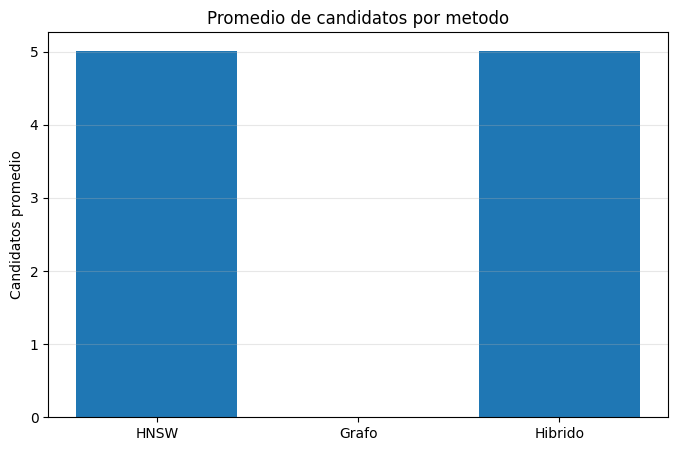


ETAPA 12W FINALIZADA
Archivo generado: evaluacion_ampliada_hibrida_eda.csv


In [ ]:

# ==================================================
# ETAPA 12W - EVALUACION AMPLIADA DEL MOTOR HIBRIDO
# ==================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

print("INICIANDO ETAPA 12W")

# 1. Preparar catalogo e indice
productos = [int(p) for p in catalogo]

mapa_posiciones = {
    producto: i
    for i, producto in enumerate(productos)
}

resultados = []
k = 5

inicio_total = time.perf_counter()

# 2. Evaluar todos los productos
for producto in productos:

    posicion = mapa_posiciones[producto]

    vector = np.asarray(
        vectores[posicion],
        dtype=np.float32
    ).reshape(1, -1)

    # Consulta HNSW
    inicio = time.perf_counter()

    etiquetas, distancias = indice_hnsw.knn_query(
        vector,
        k=min(k + 1, len(productos))
    )

    tiempo_hnsw = (
        time.perf_counter() - inicio
    ) * 1000

    vecinos_hnsw = set()

    for etiqueta in etiquetas[0]:
        interno = int(etiqueta)

        if 0 <= interno < len(productos):
            recomendado = productos[interno]

            if recomendado != producto:
                vecinos_hnsw.add(recomendado)

    # Consulta grafo
    inicio = time.perf_counter()

    if producto in grafo_compra:
        vecinos_grafo = {
            int(p)
            for p in grafo_compra.neighbors(producto)
        }
    else:
        vecinos_grafo = set()

    tiempo_grafo = (
        time.perf_counter() - inicio
    ) * 1000

    # Union hibrida
    vecinos_hibridos = (
        vecinos_hnsw | vecinos_grafo
    )

    adicionales = (
        vecinos_grafo - vecinos_hnsw
    )

    resultados.append({
        "Producto_ID": producto,
        "HNSW": len(vecinos_hnsw),
        "Grafo": len(vecinos_grafo),
        "Hibrido": len(vecinos_hibridos),
        "Adicionales": len(adicionales),
        "Tiene_grafo": len(vecinos_grafo) > 0,
        "Tiempo_HNSW_ms": tiempo_hnsw,
        "Tiempo_Grafo_ms": tiempo_grafo
    })

# 3. Crear resultados
df_12w = pd.DataFrame(resultados)

tiempo_total = time.perf_counter() - inicio_total

# 4. Calcular indicadores
total = len(df_12w)

con_grafo = int(
    df_12w["Tiene_grafo"].sum()
)

beneficiados = int(
    (df_12w["Adicionales"] > 0).sum()
)

promedio_hnsw = df_12w["HNSW"].mean()
promedio_hibrido = df_12w["Hibrido"].mean()

incremento = (
    (promedio_hibrido / promedio_hnsw - 1) * 100
    if promedio_hnsw > 0 else 0
)

cobertura_grafo = con_grafo / total * 100
porcentaje_beneficiados = beneficiados / total * 100

# 5. Resumen
print("\nRESULTADOS GENERALES")
print("Productos evaluados:", total)
print("Productos con conexiones:", con_grafo)
print("Cobertura del grafo:", round(cobertura_grafo, 2), "%")
print("Productos beneficiados:", beneficiados)
print("Porcentaje beneficiado:",
      round(porcentaje_beneficiados, 2), "%")

print("\nPROMEDIO DE CANDIDATOS")
print("HNSW:", round(promedio_hnsw, 3))
print("Hibrido:", round(promedio_hibrido, 3))
print("Incremento:", round(incremento, 2), "%")

print("\nTIEMPOS")
print("Tiempo total:", round(tiempo_total, 3), "s")
print("Mediana HNSW:",
      round(df_12w["Tiempo_HNSW_ms"].median(), 6), "ms")
print("Mediana grafo:",
      round(df_12w["Tiempo_Grafo_ms"].median(), 6), "ms")

# 6. Grafico comparativo
promedios = [
    promedio_hnsw,
    df_12w["Grafo"].mean(),
    promedio_hibrido
]

plt.figure(figsize=(8, 5))

plt.bar(
    ["HNSW", "Grafo", "Hibrido"],
    promedios
)

plt.title("Promedio de candidatos por metodo")
plt.ylabel("Candidatos promedio")
plt.grid(axis="y", alpha=0.3)
plt.show()

# 7. Exportar evidencia
df_12w.to_csv(
    "evaluacion_ampliada_hibrida_eda.csv",
    index=False
)

print("\nETAPA 12W FINALIZADA")
print("Archivo generado: evaluacion_ampliada_hibrida_eda.csv")


In [ ]:

# ETAPA 12X - DIAGNOSTICO DE COBERTURA DEL GRAFO

import pandas as pd
import networkx as nx

compras = df_productos[
    df_productos["event_type"] == "purchase"
].copy()

productos_comprados = set(
    compras["product_id"].dropna().astype(int)
)

productos_grafo = set(
    int(p) for p in grafo_compra.nodes()
)

print("DIAGNOSTICO DEL GRAFO")
print("Eventos de compra:", len(compras))
print("Productos comprados:", len(productos_comprados))
print("Usuarios compradores:", compras["user_id"].nunique())
print("Nodos del grafo:", grafo_compra.number_of_nodes())
print("Aristas del grafo:", grafo_compra.number_of_edges())

print("\nCOBERTURA")
print("Productos comprados fuera del grafo:",
      len(productos_comprados - productos_grafo))

print("Productos del grafo dentro del catalogo:",
      len(productos_grafo.intersection(set(catalogo))))

print("\nDISTRIBUCION DE COMPRAS POR USUARIO")
compras_usuario = compras.groupby("user_id")["product_id"].nunique()

print(compras_usuario.describe())

print("\nUsuarios con 2 o mas productos distintos:",
      (compras_usuario >= 2).sum())

print("\nETAPA 12X FINALIZADA")


DIAGNOSTICO DEL GRAFO
Eventos de compra: 118
Productos comprados: 96
Usuarios compradores: 109
Nodos del grafo: 15
Aristas del grafo: 8

COBERTURA
Productos comprados fuera del grafo: 81
Productos del grafo dentro del catalogo: 15

DISTRIBUCION DE COMPRAS POR USUARIO
count    109.000000
mean       1.073394
std        0.261987
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        2.000000
Name: product_id, dtype: float64

Usuarios con 2 o mas productos distintos: 8

ETAPA 12X FINALIZADA


In [ ]:

# ETAPA 12Y - POTENCIAL DE RELACIONES POR SESION

import pandas as pd

df_sesiones = df_productos.dropna(
    subset=["user_session", "product_id"]
).copy()

# Productos distintos por sesion
productos_sesion = (
    df_sesiones.groupby("user_session")["product_id"]
    .nunique()
)

total_sesiones = len(productos_sesion)
sesiones_multiproducto = int(
    (productos_sesion >= 2).sum()
)

print("DIAGNOSTICO DE SESIONES")
print("Total de sesiones:", total_sesiones)
print("Sesiones con 2 o mas productos:",
      sesiones_multiproducto)

print("Porcentaje multiproducto:",
      round(
          sesiones_multiproducto / total_sesiones * 100,
          2
      ) if total_sesiones else 0,
      "%")

print("\nDISTRIBUCION DE PRODUCTOS POR SESION")
print(productos_sesion.describe())

# Evaluar cobertura potencial
sesiones_validas = productos_sesion[
    productos_sesion >= 2
].index

productos_relacionables = set(
    df_sesiones.loc[
        df_sesiones["user_session"].isin(sesiones_validas),
        "product_id"
    ].astype(int)
)

print("\nCOBERTURA POTENCIAL")
print("Productos relacionables:",
      len(productos_relacionables))

print("Cobertura potencial:",
      round(
          len(productos_relacionables) /
          len(catalogo) * 100,
          2
      ) if len(catalogo) else 0,
      "%")

print("\nETAPA 12Y FINALIZADA")


DIAGNOSTICO DE SESIONES
Total de sesiones: 3188
Sesiones con 2 o mas productos: 1391
Porcentaje multiproducto: 43.63 %

DISTRIBUCION DE PRODUCTOS POR SESION
count    3188.000000
mean        2.233061
std         2.193054
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max        27.000000
Name: product_id, dtype: float64

COBERTURA POTENCIAL
Productos relacionables: 3458
Cobertura potencial: 83.37 %

ETAPA 12Y FINALIZADA


In [ ]:

# ETAPA 12Z - GRAFO DE CO-INTERACCION POR SESION

import networkx as nx
import pandas as pd
from itertools import combinations

grafo_sesiones = nx.Graph()

MAX_PRODUCTOS_SESION = 30

grupos = (
    df_sesiones.groupby("user_session")["product_id"]
    .apply(lambda x: sorted(set(x.dropna().astype(int))))
)

sesiones_utilizadas = 0
sesiones_excluidas = 0

for productos in grupos:
    if len(productos) < 2:
        continue

    if len(productos) > MAX_PRODUCTOS_SESION:
        sesiones_excluidas += 1
        continue

    sesiones_utilizadas += 1

    for a, b in combinations(productos, 2):
        if grafo_sesiones.has_edge(a, b):
            grafo_sesiones[a][b]["peso"] += 1
        else:
            grafo_sesiones.add_edge(a, b, peso=1)

total_catalogo = len(set(catalogo))
nodos = grafo_sesiones.number_of_nodes()
aristas = grafo_sesiones.number_of_edges()

print("RESULTADOS GRAFO POR SESION")
print("Sesiones utilizadas:", sesiones_utilizadas)
print("Sesiones excluidas:", sesiones_excluidas)
print("Nodos:", nodos)
print("Aristas:", aristas)

print("Cobertura real:",
      round(nodos / total_catalogo * 100, 2)
      if total_catalogo else 0,
      "%")

print("\nCOMPARACION")
print("Grafo co-compra:",
      grafo_compra.number_of_nodes(), "nodos")

print("Grafo por sesion:",
      nodos, "nodos")

print("\nETAPA 12Z FINALIZADA")


RESULTADOS GRAFO POR SESION
Sesiones utilizadas: 1391
Sesiones excluidas: 0
Nodos: 3458
Aristas: 11386
Cobertura real: 83.37 %

COMPARACION
Grafo co-compra: 15 nodos
Grafo por sesion: 3458 nodos

ETAPA 12Z FINALIZADA


In [ ]:

# ETAPA 12AA - EVALUACION DEL MOTOR HIBRIDO AMPLIADO

import pandas as pd
import numpy as np
import time

K = 5
resultados_12aa = []

# Identificadores reales del catalogo
productos_evaluar = list(dict.fromkeys(
    int(p) for p in catalogo
))

# Posicion interna para HNSW
posicion_producto = {
    producto: i
    for i, producto in enumerate(catalogo)
}

for producto in productos_evaluar:

    # 1. Candidatos por HNSW
    candidatos_hnsw = []

    if producto in posicion_producto:
        posicion = posicion_producto[producto]

        etiquetas, distancias = indice_hnsw.knn_query(
            vectores[posicion].reshape(1, -1),
            k=min(K + 1, len(catalogo))
        )

        for etiqueta in etiquetas[0]:
            etiqueta = int(etiqueta)

            # Las etiquetas son posiciones internas
            if 0 <= etiqueta < len(catalogo):
                recomendado = int(catalogo[etiqueta])

                if recomendado != producto:
                    if recomendado not in candidatos_hnsw:
                        candidatos_hnsw.append(recomendado)

                if len(candidatos_hnsw) >= K:
                    break

    # 2. Candidatos por grafo de sesiones
    inicio = time.perf_counter()

    if producto in grafo_sesiones:
        vecinos = sorted(
            grafo_sesiones[producto].items(),
            key=lambda item: item[1].get("peso", 1),
            reverse=True
        )

        candidatos_grafo = [
            int(vecino)
            for vecino, atributos in vecinos[:K]
        ]
    else:
        candidatos_grafo = []

    tiempo_grafo_ms = (
        time.perf_counter() - inicio
    ) * 1000

    # 3. Union sin duplicados
    candidatos_hibridos = list(dict.fromkeys(
        candidatos_hnsw + candidatos_grafo
    ))

    adicionales = (
        set(candidatos_grafo) -
        set(candidatos_hnsw)
    )

    resultados_12aa.append({
        "Producto_ID": producto,
        "HNSW": len(candidatos_hnsw),
        "Grafo": len(candidatos_grafo),
        "Hibrido": len(candidatos_hibridos),
        "Adicionales_grafo": len(adicionales),
        "Tiempo_grafo_ms": tiempo_grafo_ms
    })

df_12aa = pd.DataFrame(resultados_12aa)

print("RESULTADOS MOTOR HIBRIDO AMPLIADO")
print("Productos evaluados:", len(df_12aa))

print("\nPROMEDIO DE CANDIDATOS")
print(df_12aa[
    ["HNSW", "Grafo", "Hibrido", "Adicionales_grafo"]
].mean().round(3))

print("\nPRODUCTOS BENEFICIADOS")
beneficiados = int(
    (df_12aa["Adicionales_grafo"] > 0).sum()
)

print("Productos con candidatos adicionales:", beneficiados)
print("Porcentaje beneficiado:",
      round(beneficiados / len(df_12aa) * 100, 2),
      "%")

print("\nTIEMPO DEL GRAFO")
print("Mediana:",
      round(df_12aa["Tiempo_grafo_ms"].median(), 6),
      "ms")

df_12aa.to_csv(
    "evaluacion_motor_hibrido_ampliado.csv",
    index=False
)

print("\nETAPA 12AA FINALIZADA")


RESULTADOS MOTOR HIBRIDO AMPLIADO
Productos evaluados: 4148

PROMEDIO DE CANDIDATOS
HNSW                 5.000
Grafo                3.102
Hibrido              8.098
Adicionales_grafo    3.098
dtype: float64

PRODUCTOS BENEFICIADOS
Productos con candidatos adicionales: 3458
Porcentaje beneficiado: 83.37 %

TIEMPO DEL GRAFO
Mediana: 0.012056 ms

ETAPA 12AA FINALIZADA


In [ ]:

# ETAPA 12AB - DIAGNOSTICO TEMPORAL

import pandas as pd

df_temporal = df_productos.copy()

df_temporal["fecha"] = pd.to_datetime(
    df_temporal["event_time"],
    utc=True,
    errors="coerce"
)

print("DIAGNOSTICO TEMPORAL")
print("Eventos:", len(df_temporal))
print("Fecha minima:", df_temporal["fecha"].min())
print("Fecha maxima:", df_temporal["fecha"].max())

print("\nEVENTOS POR FECHA")
eventos_dia = (
    df_temporal.groupby(
        df_temporal["fecha"].dt.date
    )
    .size()
)

print(eventos_dia)

print("\nEVENTOS POR TIPO")
print(df_temporal["event_type"].value_counts())

print("\nUSUARIOS UNICOS")
print(df_temporal["user_id"].nunique())

print("\nSESIONES UNICAS")
print(df_temporal["user_session"].nunique())

print("\nETAPA 12AB FINALIZADA")


DIAGNOSTICO TEMPORAL
Eventos: 9996
Fecha minima: 2019-10-01 00:00:00+00:00
Fecha maxima: 2019-10-01 02:37:18+00:00

EVENTOS POR FECHA
fecha
2019-10-01    9996
dtype: int64

EVENTOS POR TIPO
event_type
view        9781
purchase     118
cart          97
Name: count, dtype: int64

USUARIOS UNICOS
2867

SESIONES UNICAS
3188

ETAPA 12AB FINALIZADA


In [ ]:

# ETAPA 12AC - PREPARACION DE VALIDACION TEMPORAL

import pandas as pd

df_eval = df_temporal.dropna(
    subset=[
        "fecha",
        "product_id",
        "user_session"
    ]
).copy()

df_eval = df_eval.sort_values("fecha")

# Corte temporal: 80% inicial de los eventos
posicion_corte = int(len(df_eval) * 0.80)

fecha_corte = df_eval.iloc[
    posicion_corte
]["fecha"]

# Separacion estrictamente temporal
train = df_eval[
    df_eval["fecha"] < fecha_corte
].copy()

test = df_eval[
    df_eval["fecha"] >= fecha_corte
].copy()

sesiones_train = set(train["user_session"])
sesiones_test = set(test["user_session"])

sesiones_comunes = (
    sesiones_train & sesiones_test
)

productos_train = set(
    train["product_id"].astype(int)
)

productos_test = set(
    test["product_id"].astype(int)
)

print("VALIDACION TEMPORAL")

print("Fecha de corte:", fecha_corte)
print("Eventos entrenamiento:", len(train))
print("Eventos prueba:", len(test))

print("\nSESIONES")
print("Sesiones entrenamiento:", len(sesiones_train))
print("Sesiones prueba:", len(sesiones_test))
print("Sesiones presentes en ambos:",
      len(sesiones_comunes))

print("\nPRODUCTOS")
print("Productos entrenamiento:",
      len(productos_train))
print("Productos prueba:",
      len(productos_test))

print("Productos de prueba conocidos:",
      len(productos_train & productos_test))

print("\nEVENTOS DE PRUEBA")
print(test["event_type"].value_counts())

print("\nETAPA 12AC FINALIZADA")


VALIDACION TEMPORAL
Fecha de corte: 2019-10-01 02:33:41+00:00
Eventos entrenamiento: 7995
Eventos prueba: 2001

SESIONES
Sesiones entrenamiento: 2669
Sesiones prueba: 852
Sesiones presentes en ambos: 333

PRODUCTOS
Productos entrenamiento: 3471
Productos prueba: 1198
Productos de prueba conocidos: 521

EVENTOS DE PRUEBA
event_type
view        1959
purchase      25
cart          17
Name: count, dtype: int64

ETAPA 12AC FINALIZADA


In [ ]:

# ETAPA 12AD - SESIONES EVALUABLES

import pandas as pd

# Productos observados antes del corte
historial_train = (
    train.groupby("user_session")["product_id"]
    .apply(lambda x: set(x.dropna().astype(int)))
)

# Productos observados despues del corte
historial_test = (
    test.groupby("user_session")["product_id"]
    .apply(lambda x: set(x.dropna().astype(int)))
)

catalogo_train = set(
    train["product_id"].dropna().astype(int)
)

resultados = []

for sesion in historial_train.index.intersection(
    historial_test.index
):
    anteriores = historial_train[sesion]
    posteriores = historial_test[sesion]

    # Productos futuros que no estaban en
    # el historial de la sesion
    nuevos = posteriores - anteriores

    # Solo productos conocidos durante entrenamiento
    evaluables = nuevos & catalogo_train

    resultados.append({
        "Sesion": sesion,
        "Productos_previos": len(anteriores),
        "Productos_futuros": len(posteriores),
        "Productos_nuevos": len(nuevos),
        "Objetivos_evaluables": len(evaluables)
    })

df_12ad = pd.DataFrame(resultados)

sesiones_evaluables = int(
    (df_12ad["Objetivos_evaluables"] > 0).sum()
)

print("DIAGNOSTICO DE EVALUABILIDAD")
print("Sesiones compartidas:", len(df_12ad))
print("Sesiones evaluables:", sesiones_evaluables)

print("Porcentaje evaluable:",
      round(
          sesiones_evaluables / len(df_12ad) * 100,
          2
      ) if len(df_12ad) else 0,
      "%")

print("\nRESUMEN")
print(df_12ad[
    [
        "Productos_previos",
        "Productos_futuros",
        "Productos_nuevos",
        "Objetivos_evaluables"
    ]
].describe().round(2))

df_12ad.to_csv(
    "evaluacion_sesiones_temporales.csv",
    index=False
)

print("\nETAPA 12AD FINALIZADA")


DIAGNOSTICO DE EVALUABILIDAD
Sesiones compartidas: 333
Sesiones evaluables: 146
Porcentaje evaluable: 43.84 %

RESUMEN
       Productos_previos  Productos_futuros  Productos_nuevos  \
count             333.00             333.00            333.00   
mean                3.33               2.28              1.75   
std                 2.87               1.59              1.68   
min                 1.00               1.00              0.00   
25%                 1.00               1.00              1.00   
50%                 2.00               2.00              1.00   
75%                 4.00               3.00              3.00   
max                22.00              12.00             12.00   

       Objetivos_evaluables  
count                333.00  
mean                   0.74  
std                    1.13  
min                    0.00  
25%                    0.00  
50%                    0.00  
75%                    1.00  
max                    8.00  

ETAPA 12AD FINALIZADA


In [ ]:

# ETAPA 12AE - GRAFO DE ENTRENAMIENTO SIN FUGA TEMPORAL

import pandas as pd
import networkx as nx
from itertools import combinations

# 1. Construir relaciones con sesiones de entrenamiento
sesiones_train = (
    train.dropna(subset=["user_session", "product_id"])
    .groupby("user_session")["product_id"]
    .apply(lambda x: set(x.astype(int)))
)

# 2. Construir grafo
grafo_train = nx.Graph()

for productos in sesiones_train:
    productos = sorted(productos)

    for producto in productos:
        grafo_train.add_node(producto)

    for a, b in combinations(productos, 2):
        if grafo_train.has_edge(a, b):
            grafo_train[a][b]["weight"] += 1
        else:
            grafo_train.add_edge(a, b, weight=1)

# 3. Evaluar cobertura
catalogo_train = set(
    train["product_id"].dropna().astype(int)
)

nodos = grafo_train.number_of_nodes()
aristas = grafo_train.number_of_edges()

print("RESULTADOS ETAPA 12AE")
print("Productos entrenamiento:", len(catalogo_train))
print("Nodos del grafo:", nodos)
print("Aristas:", aristas)
print(
    "Cobertura:",
    round(nodos / len(catalogo_train) * 100, 2)
    if catalogo_train else 0,
    "%"
)

print("Nodos con conexiones:",
      sum(1 for _, grado in grafo_train.degree()
          if grado > 0))

print("ETAPA 12AE FINALIZADA")


RESULTADOS ETAPA 12AE
Productos entrenamiento: 3471
Nodos del grafo: 3471
Aristas: 8241
Cobertura: 100.0 %
Nodos con conexiones: 2849
ETAPA 12AE FINALIZADA


In [ ]:

# ETAPA 12AF - PREPARACION DE EVALUACION TEMPORAL

import pandas as pd

# 1. Normalizar identificadores
train_eval = train.copy()
test_eval = test.copy()

for df in [train_eval, test_eval]:
    df["product_id"] = pd.to_numeric(
        df["product_id"], errors="coerce"
    ).astype("Int64")

# 2. Agrupar productos por sesion
previos = (
    train_eval.dropna(subset=["user_session", "product_id"])
    .groupby("user_session")["product_id"]
    .apply(lambda x: set(map(int, x)))
)

futuros = (
    test_eval.dropna(subset=["user_session", "product_id"])
    .groupby("user_session")["product_id"]
    .apply(lambda x: set(map(int, x)))
)

# 3. Construir casos evaluables
catalogo_entrenamiento = set(
    train_eval["product_id"].dropna().astype(int)
)

casos = []

for sesion in previos.index.intersection(futuros.index):
    productos_previos = previos[sesion]

    productos_objetivo = (
        futuros[sesion] & catalogo_entrenamiento
    ) - productos_previos

    if productos_previos and productos_objetivo:
        casos.append({
            "Sesion": sesion,
            "Previos": productos_previos,
            "Objetivos": productos_objetivo,
            "N_previos": len(productos_previos),
            "N_objetivos": len(productos_objetivo)
        })

df_casos = pd.DataFrame(casos)

# 4. Resumen
print("ETAPA 12AF - EVALUACION TEMPORAL")
print("Sesiones evaluables:", len(df_casos))

if not df_casos.empty:
    print("Promedio productos previos:",
          round(df_casos["N_previos"].mean(), 2))
    print("Promedio objetivos futuros:",
          round(df_casos["N_objetivos"].mean(), 2))

    display(
        df_casos[[
            "Sesion", "N_previos", "N_objetivos"
        ]].head(10)
    )

df_casos.to_csv(
    "casos_evaluacion_temporal_eda.csv",
    index=False
)

print("ETAPA 12AF FINALIZADA")


ETAPA 12AF - EVALUACION TEMPORAL
Sesiones evaluables: 146
Promedio productos previos: 3.03
Promedio objetivos futuros: 1.68


,Sesion,N_previos,N_objetivos
0,010bf326-d3ec-4013-8d23-40d634fc75a9,4,1
1,017f92c8-6281-4d19-a534-9432fb065124,3,1
2,03f8652a-f482-4d13-bc48-c6498b04efb8,9,1
3,0643e073-160b-4442-b0fe-38240a8ea779,1,1
4,082b1e0e-dc54-4699-8847-f20b10e3157e,2,1
5,08c91566-b6e8-4d21-80ce-edea7f72448a,4,1
6,0bb31f29-af61-4904-962f-a4af2b7fdf9d,2,2
7,0c74e0cc-d340-46ab-a2ec-22991081648b,9,3
8,12128498-1e6a-4e29-a2ba-33c528f6b133,1,1
9,16f918d2-8d77-474a-95cb-4d0ecc3e7077,1,1


ETAPA 12AF FINALIZADA


In [ ]:

# ETAPA 12AG - EVALUACION TOP 5 DEL GRAFO DE SESIONES

import pandas as pd
import time

K = 5

# 1. Funcion de recomendacion basada en el grafo
def recomendar_grafo(productos_previos, grafo, k=5):
    puntuaciones = {}

    for producto in productos_previos:
        if producto not in grafo:
            continue

        for vecino in grafo.neighbors(producto):
            if vecino in productos_previos:
                continue

            peso = grafo[producto][vecino].get("weight", 1)

            puntuaciones[vecino] = (
                puntuaciones.get(vecino, 0) + peso
            )

    ranking = sorted(
        puntuaciones,
        key=lambda p: (-puntuaciones[p], p)
    )

    return ranking[:k]


# 2. Evaluar cada sesion
resultados = []

for _, fila in df_casos.iterrows():

    previos = fila["Previos"]
    objetivos = fila["Objetivos"]

    inicio = time.perf_counter()

    recomendaciones = recomendar_grafo(
        previos, grafo_train, K
    )

    tiempo_ms = (
        time.perf_counter() - inicio
    ) * 1000

    aciertos = len(
        set(recomendaciones) & objetivos
    )

    resultados.append({
        "Sesion": fila["Sesion"],
        "Recomendaciones": recomendaciones,
        "N_objetivos": len(objetivos),
        "Aciertos": aciertos,
        "Hit": int(aciertos > 0),
        "Precision": aciertos / K,
        "Recall": aciertos / len(objetivos),
        "Tiempo_ms": tiempo_ms
    })


# 3. Resultados
df_resultados_grafo = pd.DataFrame(resultados)

resumen_grafo = pd.DataFrame([{
    "Metodo": "Grafo de sesiones",
    "Sesiones": len(df_resultados_grafo),
    "Hit_Rate_5": df_resultados_grafo["Hit"].mean(),
    "Precision_5": df_resultados_grafo["Precision"].mean(),
    "Recall_5": df_resultados_grafo["Recall"].mean(),
    "Tiempo_mediano_ms": df_resultados_grafo["Tiempo_ms"].median()
}])

print("RESULTADOS ETAPA 12AG")
display(resumen_grafo.round(4))

print("\nPRIMERAS 10 SESIONES")
display(df_resultados_grafo.head(10))

# 4. Guardar evidencias
df_resultados_grafo.to_csv(
    "evaluacion_grafo_top5_eda.csv",
    index=False
)

resumen_grafo.to_csv(
    "resumen_grafo_top5_eda.csv",
    index=False
)

print("\nETAPA 12AG FINALIZADA")


RESULTADOS ETAPA 12AG


,Metodo,Sesiones,Hit_Rate_5,Precision_5,Recall_5,Tiempo_mediano_ms
0,Grafo de sesiones,146,0.1301,0.026,0.0908,0.0256



PRIMERAS 10 SESIONES


,Sesion,Recomendaciones,N_objetivos,Aciertos,Hit,Precision,Recall,Tiempo_ms
0,010bf326-d3ec-4013-8d23-40d634fc75a9,"[1004767, 1004750, 1004870, 1002544, 1004873]",1,0,0,0.0,0.0,0.23569
1,017f92c8-6281-4d19-a534-9432fb065124,[],1,0,0,0.0,0.0,0.01061
2,03f8652a-f482-4d13-bc48-c6498b04efb8,"[1004856, 1005115, 1004870, 1004249, 1004833]",1,0,0,0.0,0.0,0.36147
3,0643e073-160b-4442-b0fe-38240a8ea779,[],1,0,0,0.0,0.0,0.00749
4,082b1e0e-dc54-4699-8847-f20b10e3157e,[],1,0,0,0.0,0.0,0.00934
5,08c91566-b6e8-4d21-80ce-edea7f72448a,"[13400422, 13400622, 14700083, 14700100, 14700101]",1,1,1,0.2,1.0,0.04372
6,0bb31f29-af61-4904-962f-a4af2b7fdf9d,"[1005073, 1005115, 1002099, 1003306, 1003316]",2,1,1,0.2,0.5,0.04675
7,0c74e0cc-d340-46ab-a2ec-22991081648b,"[1004856, 1004870, 1004750, 1004833, 1004659]",3,0,0,0.0,0.0,1.39192
8,12128498-1e6a-4e29-a2ba-33c528f6b133,"[1004741, 1002544, 1004870, 1002524, 1002633]",1,0,0,0.0,0.0,0.03214
9,16f918d2-8d77-474a-95cb-4d0ecc3e7077,"[4804295, 1005158, 1005159, 4801876, 4802639]",1,0,0,0.0,0.0,0.03201



ETAPA 12AG FINALIZADA


In [ ]:

# ETAPA 12AH - CONSTRUCCION HNSW TEMPORAL

import numpy as np
import pandas as pd
import hnswlib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Catalogo de entrenamiento
datos = train.copy()
datos["product_id"] = pd.to_numeric(
    datos["product_id"], errors="coerce"
)
datos = datos.dropna(subset=["product_id"])
datos["product_id"] = datos["product_id"].astype(int)

columnas = ["category_code", "brand", "price"]

productos_train = (
    datos.sort_values("event_time")
    .drop_duplicates("product_id", keep="last")
    [["product_id"] + columnas]
    .reset_index(drop=True)
)

# 2. Preparar caracteristicas
for col in ["category_code", "brand"]:
    productos_train[col] = (
        productos_train[col].fillna("desconocido")
        .astype(str)
    )

productos_train["price"] = pd.to_numeric(
    productos_train["price"], errors="coerce"
)

mediana = productos_train["price"].median()
productos_train["price"] = (
    productos_train["price"].fillna(
        mediana if pd.notna(mediana) else 0
    ).clip(lower=0)
)

productos_train["price"] = np.log1p(
    productos_train["price"]
)

transformador = ColumnTransformer([
    ("categorias", OneHotEncoder(
        handle_unknown="ignore"
    ), ["category_code", "brand"]),
    ("precio", StandardScaler(), ["price"])
])

X = transformador.fit_transform(productos_train)
X = X.toarray() if hasattr(X, "toarray") else X
X = np.asarray(X, dtype=np.float32)

# 3. Construir indice
indice_hnsw_train = hnswlib.Index(
    space="l2", dim=X.shape[1]
)

indice_hnsw_train.init_index(
    max_elements=len(X),
    ef_construction=200,
    M=16
)

indice_hnsw_train.add_items(
    X, np.arange(len(X))
)

indice_hnsw_train.set_ef(100)

ids_productos_hnsw = (
    productos_train["product_id"].tolist()
)

posicion_hnsw = {
    producto: i
    for i, producto in enumerate(ids_productos_hnsw)
}

print("ETAPA 12AH - INDICE CONSTRUIDO")
print("Productos indexados:", len(ids_productos_hnsw))
print("Dimensiones:", X.shape[1])
print("Indice HNSW:", indice_hnsw_train.get_current_count())
print("ETAPA 12AH FINALIZADA")


ETAPA 12AH - INDICE CONSTRUIDO
Productos indexados: 3471
Dimensiones: 702
Indice HNSW: 3471
ETAPA 12AH FINALIZADA


In [ ]:

# ETAPA 12AI - EVALUACION TEMPORAL HNSW TOP 5

import pandas as pd
import numpy as np
import time

K = 5

# 1. Funcion de recomendacion HNSW
def recomendar_hnsw_temporal(productos_previos, k=5):
    puntuaciones = {}

    for producto in productos_previos:
        posicion = posicion_hnsw.get(int(producto))

        if posicion is None:
            continue

        cantidad = min(
            len(ids_productos_hnsw),
            max(k + len(productos_previos) + 1, 30)
        )

        vecinos, distancias = indice_hnsw_train.knn_query(
            X[posicion].reshape(1, -1),
            k=cantidad
        )

        for vecino, distancia in zip(
            vecinos[0], distancias[0]
        ):
            candidato = int(ids_productos_hnsw[int(vecino)])

            if candidato in productos_previos:
                continue

            # Menor distancia = mayor similitud
            similitud = 1 / (1 + float(distancia))

            puntuaciones[candidato] = max(
                puntuaciones.get(candidato, 0),
                similitud
            )

    ranking = sorted(
        puntuaciones,
        key=lambda p: (-puntuaciones[p], p)
    )

    return ranking[:k]


# 2. Evaluar las mismas sesiones
resultados_hnsw = []

for _, fila in df_casos.iterrows():

    previos = fila["Previos"]
    objetivos = fila["Objetivos"]

    inicio = time.perf_counter()

    recomendaciones = recomendar_hnsw_temporal(
        previos, K
    )

    tiempo_ms = (
        time.perf_counter() - inicio
    ) * 1000

    aciertos = len(
        set(recomendaciones) & objetivos
    )

    resultados_hnsw.append({
        "Sesion": fila["Sesion"],
        "Recomendaciones": recomendaciones,
        "N_objetivos": len(objetivos),
        "Aciertos": aciertos,
        "Hit": int(aciertos > 0),
        "Precision": aciertos / K,
        "Recall": aciertos / len(objetivos),
        "Tiempo_ms": tiempo_ms
    })


# 3. Resumen
df_resultados_hnsw = pd.DataFrame(resultados_hnsw)

resumen_hnsw = pd.DataFrame([{
    "Metodo": "HNSW",
    "Sesiones": len(df_resultados_hnsw),
    "Hit_Rate_5": df_resultados_hnsw["Hit"].mean(),
    "Precision_5": df_resultados_hnsw["Precision"].mean(),
    "Recall_5": df_resultados_hnsw["Recall"].mean(),
    "Tiempo_mediano_ms": df_resultados_hnsw["Tiempo_ms"].median()
}])

print("RESULTADOS ETAPA 12AI")
display(resumen_hnsw.round(4))

# 4. Comparacion preliminar
comparacion = pd.concat(
    [resumen_grafo, resumen_hnsw],
    ignore_index=True
)

print("\nCOMPARACION GRAFO VS HNSW")
display(comparacion.round(4))

# 5. Guardar evidencias
df_resultados_hnsw.to_csv(
    "evaluacion_hnsw_top5_eda.csv",
    index=False
)

comparacion.to_csv(
    "comparacion_grafo_hnsw_eda.csv",
    index=False
)

print("\nETAPA 12AI FINALIZADA")


RESULTADOS ETAPA 12AI


,Metodo,Sesiones,Hit_Rate_5,Precision_5,Recall_5,Tiempo_mediano_ms
0,HNSW,146,0.2055,0.0493,0.1523,0.6059



COMPARACION GRAFO VS HNSW


,Metodo,Sesiones,Hit_Rate_5,Precision_5,Recall_5,Tiempo_mediano_ms
0,Grafo de sesiones,146,0.1301,0.0260,0.0908,0.0256
1,HNSW,146,0.2055,0.0493,0.1523,0.6059



ETAPA 12AI FINALIZADA


In [ ]:

# ETAPA 12AJ - EVALUACION DEL MOTOR HIBRIDO TOP 5

import pandas as pd
import time

K = 5

# 1. Recomendacion hibrida
def recomendar_hibrido_temporal(previos, k=5):

    candidatos_hnsw = recomendar_hnsw_temporal(
        previos, k=20
    )

    candidatos_grafo = recomendar_grafo(
        previos, grafo_train, k=20
    )

    puntuaciones = {}

    # Fusion por ranking reciproco
    for ranking in [candidatos_hnsw, candidatos_grafo]:
        for posicion, producto in enumerate(ranking, 1):
            puntuaciones[producto] = (
                puntuaciones.get(producto, 0)
                + 1 / (60 + posicion)
            )

    ranking_final = sorted(
        puntuaciones,
        key=lambda p: (-puntuaciones[p], p)
    )

    return ranking_final[:k]


# 2. Evaluacion
resultados_hibrido = []

for _, fila in df_casos.iterrows():

    previos = fila["Previos"]
    objetivos = fila["Objetivos"]

    inicio = time.perf_counter()

    recomendaciones = recomendar_hibrido_temporal(
        previos, K
    )

    tiempo_ms = (
        time.perf_counter() - inicio
    ) * 1000

    aciertos = len(
        set(recomendaciones) & objetivos
    )

    resultados_hibrido.append({
        "Sesion": fila["Sesion"],
        "Recomendaciones": recomendaciones,
        "N_objetivos": len(objetivos),
        "Aciertos": aciertos,
        "Hit": int(aciertos > 0),
        "Precision": aciertos / K,
        "Recall": aciertos / len(objetivos),
        "Tiempo_ms": tiempo_ms
    })


# 3. Resultados
df_resultados_hibrido = pd.DataFrame(
    resultados_hibrido
)

resumen_hibrido = pd.DataFrame([{
    "Metodo": "Hibrido",
    "Sesiones": len(df_resultados_hibrido),
    "Hit_Rate_5": df_resultados_hibrido["Hit"].mean(),
    "Precision_5": df_resultados_hibrido["Precision"].mean(),
    "Recall_5": df_resultados_hibrido["Recall"].mean(),
    "Tiempo_mediano_ms": df_resultados_hibrido["Tiempo_ms"].median()
}])

comparacion_final = pd.concat(
    [resumen_grafo, resumen_hnsw, resumen_hibrido],
    ignore_index=True
)

print("RESULTADOS ETAPA 12AJ")
display(comparacion_final.round(4))

# 4. Exportar evidencia
df_resultados_hibrido.to_csv(
    "evaluacion_hibrido_top5_eda.csv",
    index=False
)

comparacion_final.to_csv(
    "comparacion_final_motores_eda.csv",
    index=False
)

print("\nETAPA 12AJ FINALIZADA")


RESULTADOS ETAPA 12AJ


,Metodo,Sesiones,Hit_Rate_5,Precision_5,Recall_5,Tiempo_mediano_ms
0,Grafo de sesiones,146,0.1301,0.0260,0.0908,0.0256
1,HNSW,146,0.2055,0.0493,0.1523,0.6059
2,Hibrido,146,0.2534,0.0603,0.1798,0.4730



ETAPA 12AJ FINALIZADA


In [ ]:

# ETAPA 12AK - ANALISIS PAREADO HNSW VS HIBRIDO

import pandas as pd
import numpy as np

comparacion_pareada = (
    df_resultados_hnsw[
        ["Sesion", "Hit", "Recall", "Precision"]
    ]
    .merge(
        df_resultados_hibrido[
            ["Sesion", "Hit", "Recall", "Precision"]
        ],
        on="Sesion",
        suffixes=("_HNSW", "_Hibrido"),
        validate="one_to_one"
    )
)

if len(comparacion_pareada) != len(df_casos):
    raise ValueError("Faltan sesiones en la comparacion")

ambos = (
    (comparacion_pareada["Hit_HNSW"] == 1) &
    (comparacion_pareada["Hit_Hibrido"] == 1)
).sum()

solo_hnsw = (
    (comparacion_pareada["Hit_HNSW"] == 1) &
    (comparacion_pareada["Hit_Hibrido"] == 0)
).sum()

solo_hibrido = (
    (comparacion_pareada["Hit_HNSW"] == 0) &
    (comparacion_pareada["Hit_Hibrido"] == 1)
).sum()

ninguno = (
    (comparacion_pareada["Hit_HNSW"] == 0) &
    (comparacion_pareada["Hit_Hibrido"] == 0)
).sum()

resumen_pareado = pd.DataFrame({
    "Resultado": [
        "Ambos aciertan",
        "Solo HNSW acierta",
        "Solo hibrido acierta",
        "Ninguno acierta"
    ],
    "Sesiones": [
        ambos, solo_hnsw, solo_hibrido, ninguno
    ]
})

print("ETAPA 12AK - COMPARACION PAREADA")
display(resumen_pareado)

print("Mejora neta en sesiones:",
      solo_hibrido - solo_hnsw)

print("Total sesiones:",
      len(comparacion_pareada))

resumen_pareado.to_csv(
    "analisis_pareado_motores_eda.csv",
    index=False
)

comparacion_pareada.to_csv(
    "detalle_pareado_motores_eda.csv",
    index=False
)

print("ETAPA 12AK FINALIZADA")


ETAPA 12AK - COMPARACION PAREADA


,Resultado,Sesiones
0,Ambos aciertan,25
1,Solo HNSW acierta,5
2,Solo hibrido acierta,12
3,Ninguno acierta,104


Mejora neta en sesiones: 7
Total sesiones: 146
ETAPA 12AK FINALIZADA


In [ ]:

# ETAPA 12AL - SIGNIFICANCIA ESTADISTICA
# Comparacion pareada HNSW vs Hibrido

import pandas as pd
from scipy.stats import binomtest

# Resultados de la etapa 12AK
ambos = 25
solo_hnsw = 5
solo_hibrido = 12
ninguno = 104

# McNemar exacto: solo cuentan los casos discordantes
discordantes = solo_hnsw + solo_hibrido

prueba = binomtest(
    min(solo_hnsw, solo_hibrido),
    n=discordantes,
    p=0.5,
    alternative="two-sided"
)

p_valor = prueba.pvalue
alpha = 0.05

print("ETAPA 12AL - VALIDACION ESTADISTICA")
print("Sesiones evaluadas:", 146)
print("Solo HNSW acierta:", solo_hnsw)
print("Solo Hibrido acierta:", solo_hibrido)
print("Casos discordantes:", discordantes)
print("P-valor:", round(p_valor, 6))

if p_valor < alpha:
    conclusion = "DIFERENCIA ESTADISTICAMENTE SIGNIFICATIVA"
else:
    conclusion = "DIFERENCIA NO ESTADISTICAMENTE SIGNIFICATIVA"

print("CONCLUSION:", conclusion)

df_estadistica = pd.DataFrame([{
    "Prueba": "McNemar exacta",
    "Sesiones": 146,
    "Solo_HNSW": solo_hnsw,
    "Solo_Hibrido": solo_hibrido,
    "P_valor": p_valor,
    "Alpha": alpha,
    "Conclusion": conclusion
}])

display(df_estadistica)

df_estadistica.to_csv(
    "validacion_estadistica_motores_eda.csv",
    index=False
)

print("ETAPA 12AL FINALIZADA")


ETAPA 12AL - VALIDACION ESTADISTICA
Sesiones evaluadas: 146
Solo HNSW acierta: 5
Solo Hibrido acierta: 12
Casos discordantes: 17
P-valor: 0.143463
CONCLUSION: DIFERENCIA NO ESTADISTICAMENTE SIGNIFICATIVA


,Prueba,Sesiones,Solo_HNSW,Solo_Hibrido,P_valor,Alpha,Conclusion
0,McNemar exacta,146,5,12,0.143463,0.05,DIFERENCIA NO ESTADISTICAMENTE SIGNIFICATIVA


ETAPA 12AL FINALIZADA


In [ ]:

# ==================================================
# ETAPA 12AM - DIAGNOSTICO DE ROBUSTEZ TEMPORAL
# ==================================================

import pandas as pd
import numpy as np

print("INICIANDO ETAPA 12AM")

# 1. Copia independiente del dataset
datos = df_productos.copy()

datos["event_time"] = pd.to_datetime(
    datos["event_time"],
    utc=True,
    errors="coerce"
)

datos = datos.dropna(
    subset=["event_time", "user_session", "product_id"]
)

datos = datos.sort_values("event_time").reset_index(drop=True)

print("\nDATOS GENERALES")
print("Eventos:", len(datos))
print("Sesiones:", datos["user_session"].nunique())
print("Productos:", datos["product_id"].nunique())

# 2. Evaluar distintos cortes temporales
cortes = [0.60, 0.65, 0.70, 0.75, 0.80]

resultados = []

for corte in cortes:

    posicion = int(len(datos) * corte)
    fecha_corte = datos.iloc[posicion]["event_time"]

    train = datos[
        datos["event_time"] < fecha_corte
    ].copy()

    test = datos[
        datos["event_time"] >= fecha_corte
    ].copy()

    sesiones_train = set(train["user_session"])
    sesiones_test = set(test["user_session"])

    compartidas = sesiones_train & sesiones_test

    catalogo_train = set(train["product_id"])

    # Sesiones con productos conocidos antes del corte
    test_conocidos = test[
        test["product_id"].isin(catalogo_train)
    ]

    sesiones_conocidas = set(
        test_conocidos["user_session"]
    )

    resultados.append({
        "Corte": corte,
        "Eventos_train": len(train),
        "Eventos_test": len(test),
        "Sesiones_compartidas": len(compartidas),
        "Sesiones_con_productos_conocidos":
            len(sesiones_conocidas),
        "Productos_train": len(catalogo_train)
    })

# 3. Mostrar resultados
df_robustez = pd.DataFrame(resultados)

display(df_robustez)

# 4. Guardar evidencia
df_robustez.to_csv(
    "diagnostico_robustez_temporal_eda.csv",
    index=False
)

print("\nETAPA 12AM - DIAGNOSTICO FINALIZADO")


INICIANDO ETAPA 12AM

DATOS GENERALES
Eventos: 9996
Sesiones: 3188
Productos: 4148


,Corte,Eventos_train,Eventos_test,Sesiones_compartidas,Sesiones_con_productos_conocidos,Productos_train
0,0.60,5984,4012,368,883,2727
1,0.65,6492,3504,363,812,2919
2,0.70,6987,3009,353,734,3090
3,0.75,7494,2502,368,663,3280
4,0.80,7995,2001,333,577,3471



ETAPA 12AM - DIAGNOSTICO FINALIZADO


In [ ]:

# ETAPA 12AN - SESIONES EVALUABLES

import pandas as pd

datos = df_productos.copy()

datos["event_time"] = pd.to_datetime(
    datos["event_time"], utc=True, errors="coerce"
)

datos = datos.dropna(
    subset=["event_time", "user_session", "product_id"]
).sort_values("event_time").reset_index(drop=True)

# Corte temporal 80%
posicion = int(len(datos) * 0.80)
fecha_corte = datos.iloc[posicion]["event_time"]

train = datos[datos["event_time"] < fecha_corte].copy()
test = datos[datos["event_time"] >= fecha_corte].copy()

catalogo_train = set(train["product_id"])

# Productos previos por sesion
historiales = train.groupby("user_session")["product_id"].agg(set)

# Productos futuros por sesion
futuros = test.groupby("user_session")["product_id"].agg(set)

resultados = []

for sesion in historiales.index.intersection(futuros.index):

    previos = historiales[sesion]
    posteriores = futuros[sesion]

    objetivos = (posteriores & catalogo_train) - previos

    resultados.append({
        "Sesion": sesion,
        "N_previos": len(previos),
        "N_futuros": len(posteriores),
        "N_objetivos": len(objetivos),
        "Evaluable": len(previos) > 0 and len(objetivos) > 0
    })

df_sesiones_12an = pd.DataFrame(resultados)

evaluables = df_sesiones_12an[
    df_sesiones_12an["Evaluable"]
].copy()

print("ETAPA 12AN - DIAGNOSTICO")
print("Fecha de corte:", fecha_corte)
print("Sesiones compartidas:", len(df_sesiones_12an))
print("Sesiones evaluables:", len(evaluables))

porcentaje = (
    len(evaluables) / len(df_sesiones_12an) * 100
    if len(df_sesiones_12an) else 0
)

print("Porcentaje evaluable:", round(porcentaje, 2), "%")

display(df_sesiones_12an.head(10))

df_sesiones_12an.to_csv(
    "sesiones_evaluables_eda.csv",
    index=False
)

print("ETAPA 12AN FINALIZADA")


ETAPA 12AN - DIAGNOSTICO
Fecha de corte: 2019-10-01 02:33:41+00:00
Sesiones compartidas: 333
Sesiones evaluables: 146
Porcentaje evaluable: 43.84 %


,Sesion,N_previos,N_futuros,N_objetivos,Evaluable
0,010bf326-d3ec-4013-8d23-40d634fc75a9,4,2,1,True
1,012b10a8-c9e4-476d-b5ef-a6af6b99e5c6,1,1,0,False
2,017f92c8-6281-4d19-a534-9432fb065124,3,3,1,True
3,03f8652a-f482-4d13-bc48-c6498b04efb8,9,1,1,True
4,0643e073-160b-4442-b0fe-38240a8ea779,1,2,1,True
5,082b1e0e-dc54-4699-8847-f20b10e3157e,2,3,1,True
6,087f0d82-6e8b-4be1-b6dd-8eb9ed350039,11,3,0,False
7,08c91566-b6e8-4d21-80ce-edea7f72448a,4,2,1,True
8,08d0d4ce-9032-e157-633b-5293b0b5f8a2,9,1,0,False
9,0a1eb64d-a53b-480a-a50a-fec6ceadd7ad,2,1,0,False


ETAPA 12AN FINALIZADA


In [ ]:

# ETAPA 12AO - COMPARACION DE CORTES TEMPORALES

import pandas as pd

datos = df_productos.copy()

datos["event_time"] = pd.to_datetime(
    datos["event_time"],
    utc=True,
    errors="coerce"
)

datos = (
    datos.dropna(
        subset=["event_time", "user_session", "product_id"]
    )
    .sort_values("event_time")
    .reset_index(drop=True)
)

cortes = [0.60, 0.65, 0.70, 0.75, 0.80]
resultados = []

for corte in cortes:

    posicion = int(len(datos) * corte)
    fecha = datos.iloc[posicion]["event_time"]

    train_c = datos[datos["event_time"] < fecha]
    test_c = datos[datos["event_time"] >= fecha]

    catalogo_c = set(train_c["product_id"])

    previos = train_c.groupby(
        "user_session"
    )["product_id"].agg(set)

    futuros = test_c.groupby(
        "user_session"
    )["product_id"].agg(set)

    compartidas = previos.index.intersection(futuros.index)

    evaluables = 0

    for sesion in compartidas:
        objetivos = (
            futuros[sesion] & catalogo_c
        ) - previos[sesion]

        if len(objetivos) > 0:
            evaluables += 1

    resultados.append({
        "Corte": corte,
        "Sesiones_compartidas": len(compartidas),
        "Sesiones_evaluables": evaluables,
        "Porcentaje_evaluable": round(
            evaluables / len(compartidas) * 100, 2
        ) if len(compartidas) else 0,
        "Productos_train": len(catalogo_c)
    })

df_cortes_evaluables = pd.DataFrame(resultados)

display(df_cortes_evaluables)

df_cortes_evaluables.to_csv(
    "comparacion_cortes_temporales_eda.csv",
    index=False
)

print("ETAPA 12AO FINALIZADA")


,Corte,Sesiones_compartidas,Sesiones_evaluables,Porcentaje_evaluable,Productos_train
0,0.60,368,163,44.29,2727
1,0.65,363,168,46.28,2919
2,0.70,353,170,48.16,3090
3,0.75,368,156,42.39,3280
4,0.80,333,146,43.84,3471


ETAPA 12AO FINALIZADA


In [ ]:

# ETAPA 12AP - PREPARACION DEL CORTE 70%

import pandas as pd

datos_12ap = df_productos.copy()

datos_12ap["event_time"] = pd.to_datetime(
    datos_12ap["event_time"],
    utc=True,
    errors="coerce"
)

datos_12ap = (
    datos_12ap.dropna(
        subset=["event_time", "user_session", "product_id"]
    )
    .sort_values("event_time")
    .reset_index(drop=True)
)

posicion = int(len(datos_12ap) * 0.70)
fecha_corte_70 = datos_12ap.iloc[posicion]["event_time"]

train_70 = datos_12ap[
    datos_12ap["event_time"] < fecha_corte_70
].copy()

test_70 = datos_12ap[
    datos_12ap["event_time"] >= fecha_corte_70
].copy()

catalogo_70 = set(train_70["product_id"])

historiales_70 = train_70.groupby(
    "user_session"
)["product_id"].agg(set)

futuros_70 = test_70.groupby(
    "user_session"
)["product_id"].agg(set)

sesiones_70 = []

for sesion in historiales_70.index.intersection(
    futuros_70.index
):
    previos = historiales_70[sesion]

    objetivos = (
        futuros_70[sesion] & catalogo_70
    ) - previos

    if previos and objetivos:
        sesiones_70.append({
            "Sesion": sesion,
            "N_previos": len(previos),
            "N_objetivos": len(objetivos)
        })

df_evaluables_70 = pd.DataFrame(sesiones_70)

print("ETAPA 12AP - PREPARACION")
print("Fecha de corte:", fecha_corte_70)
print("Eventos entrenamiento:", len(train_70))
print("Eventos prueba:", len(test_70))
print("Productos entrenamiento:", len(catalogo_70))
print("Sesiones evaluables:", len(df_evaluables_70))

print("\nTIPOS DE EVENTOS EN ENTRENAMIENTO")
print(train_70["event_type"].value_counts())

print("\nCOLUMNAS DISPONIBLES")
print(train_70.columns.tolist())

display(df_evaluables_70.head(10))

print("\nETAPA 12AP FINALIZADA")


ETAPA 12AP - PREPARACION
Fecha de corte: 2019-10-01 02:31:55+00:00
Eventos entrenamiento: 6987
Eventos prueba: 3009
Productos entrenamiento: 3090
Sesiones evaluables: 170

TIPOS DE EVENTOS EN ENTRENAMIENTO
event_type
view        6840
purchase      78
cart          69
Name: count, dtype: int64

COLUMNAS DISPONIBLES
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']


,Sesion,N_previos,N_objetivos
0,010bf326-d3ec-4013-8d23-40d634fc75a9,3,2
1,03f8652a-f482-4d13-bc48-c6498b04efb8,7,3
2,06a336d7-34af-49c8-88d6-0604e8e78866,1,1
3,087933c7-5000-4009-b654-670275e0eb6b,2,1
4,08c91566-b6e8-4d21-80ce-edea7f72448a,3,2
5,0953edf5-eb67-4664-aba2-abeffa28deb5,1,1
6,0a08ee06-4e35-42bc-8c74-f7840ae9d24c,4,2
7,0bb31f29-af61-4904-962f-a4af2b7fdf9d,1,3
8,0c74e0cc-d340-46ab-a2ec-22991081648b,7,5
9,123db165-880c-42ec-b5c0-9abeed9e8dca,1,1



ETAPA 12AP FINALIZADA


In [ ]:

# ====================================================
# ETAPA 12AQ - GRAFO DE SESIONES CON CORTE 70%
# ====================================================

import pandas as pd
import networkx as nx
from itertools import combinations
from time import perf_counter

print("INICIANDO ETAPA 12AQ")

inicio = perf_counter()

# 1. Crear grafo independiente
grafo_70 = nx.Graph()

# 2. Agregar productos del entrenamiento
productos_70 = set(train_70["product_id"])

grafo_70.add_nodes_from(productos_70)

# 3. Obtener productos por sesion
productos_por_sesion_70 = (
    train_70.groupby("user_session")["product_id"]
    .apply(lambda x: list(dict.fromkeys(x)))
)

# 4. Construir relaciones entre productos
for productos in productos_por_sesion_70:

    for a, b in combinations(productos, 2):

        if grafo_70.has_edge(a, b):
            grafo_70[a][b]["weight"] += 1
        else:
            grafo_70.add_edge(a, b, weight=1)

tiempo_construccion = perf_counter() - inicio

# 5. Diagnostico
nodos = grafo_70.number_of_nodes()
aristas = grafo_70.number_of_edges()

nodos_conectados = sum(
    1 for _, grado in grafo_70.degree()
    if grado > 0
)

cobertura = (
    nodos_conectados / len(productos_70) * 100
    if productos_70 else 0
)

print("\nRESULTADOS GRAFO 70%")
print("Nodos:", nodos)
print("Aristas:", aristas)
print("Nodos con conexiones:", nodos_conectados)
print("Cobertura conectada:", round(cobertura, 2), "%")
print("Tiempo construccion:", round(tiempo_construccion, 4), "s")

# 6. Validacion
assert nodos == len(productos_70)
assert set(grafo_70.nodes()) == productos_70

print("\nVALIDACION: CORRECTA")

# 7. Exportar evidencia
df_grafo_70 = pd.DataFrame([{
    "Corte": 0.70,
    "Nodos": nodos,
    "Aristas": aristas,
    "Nodos_conectados": nodos_conectados,
    "Cobertura_pct": round(cobertura, 2),
    "Tiempo_construccion_s": tiempo_construccion
}])

display(df_grafo_70)

df_grafo_70.to_csv(
    "grafo_sesiones_70_eda.csv",
    index=False
)

print("\nETAPA 12AQ FINALIZADA")


INICIANDO ETAPA 12AQ

RESULTADOS GRAFO 70%
Nodos: 3090
Aristas: 6696
Nodos con conexiones: 2509
Cobertura conectada: 81.2 %
Tiempo construccion: 0.2003 s

VALIDACION: CORRECTA


,Corte,Nodos,Aristas,Nodos_conectados,Cobertura_pct,Tiempo_construccion_s
0,0.7,3090,6696,2509,81.2,0.200334



ETAPA 12AQ FINALIZADA


In [ ]:

# ==================================================
# ETAPA 12AR - RECONSTRUCCION HNSW 70%
# ==================================================

import numpy as np
import pandas as pd
import hnswlib

from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from time import perf_counter

print("INICIANDO ETAPA 12AR")

inicio = perf_counter()

# 1. Productos y sesiones de entrenamiento
ids_productos_70 = sorted(
    train_70["product_id"].unique()
)

ids_sesiones_70 = sorted(
    train_70["user_session"].unique()
)

mapa_productos_70 = {
    p: i for i, p in enumerate(ids_productos_70)
}

mapa_sesiones_70 = {
    s: i for i, s in enumerate(ids_sesiones_70)
}

# 2. Construir matriz producto-sesion
interacciones = train_70[
    ["product_id", "user_session"]
].drop_duplicates()

filas = interacciones["product_id"].map(
    mapa_productos_70
).to_numpy()

columnas = interacciones["user_session"].map(
    mapa_sesiones_70
).to_numpy()

matriz_70 = csr_matrix(
    (
        np.ones(len(interacciones)),
        (filas, columnas)
    ),
    shape=(
        len(ids_productos_70),
        len(ids_sesiones_70)
    )
)

# 3. Representacion TF-IDF
tfidf_70 = TfidfTransformer()
matriz_tfidf_70 = tfidf_70.fit_transform(matriz_70)

# 4. Reduccion dimensional
dimensiones_70 = min(
    64,
    matriz_tfidf_70.shape[0] - 1,
    matriz_tfidf_70.shape[1] - 1
)

svd_70 = TruncatedSVD(
    n_components=dimensiones_70,
    random_state=42
)

vectores_70 = svd_70.fit_transform(
    matriz_tfidf_70
)

vectores_70 = normalize(
    vectores_70
).astype(np.float32)

# 5. Construccion del indice HNSW
indice_hnsw_70 = hnswlib.Index(
    space="cosine",
    dim=vectores_70.shape[1]
)

indice_hnsw_70.init_index(
    max_elements=len(ids_productos_70),
    ef_construction=200,
    M=16,
    random_seed=42
)

indice_hnsw_70.add_items(
    vectores_70,
    np.arange(len(ids_productos_70))
)

indice_hnsw_70.set_ef(100)

tiempo_70 = perf_counter() - inicio

# 6. Validaciones
assert indice_hnsw_70.get_current_count() == len(ids_productos_70)
assert np.isfinite(vectores_70).all()

print("\nRESULTADOS HNSW 70%")
print("Productos indexados:", len(ids_productos_70))
print("Dimensiones:", vectores_70.shape[1])
print("Elementos HNSW:", indice_hnsw_70.get_current_count())
print("Tiempo construccion:", round(tiempo_70, 4), "s")

# 7. Guardar evidencia
df_hnsw_70 = pd.DataFrame([{
    "Corte": 0.70,
    "Productos": len(ids_productos_70),
    "Dimensiones": vectores_70.shape[1],
    "Tiempo_construccion_s": tiempo_70
}])

display(df_hnsw_70)

df_hnsw_70.to_csv(
    "hnsw_70_eda.csv",
    index=False
)

print("\nETAPA 12AR FINALIZADA")


INICIANDO ETAPA 12AR

RESULTADOS HNSW 70%
Productos indexados: 3090
Dimensiones: 64
Elementos HNSW: 3090
Tiempo construccion: 0.6885 s


,Corte,Productos,Dimensiones,Tiempo_construccion_s
0,0.7,3090,64,0.688508



ETAPA 12AR FINALIZADA


In [ ]:

# ETAPA 12AS - DIAGNOSTICO PREVIO

import pandas as pd

variables = [
    "train_70",
    "test_70",
    "indice_hnsw_70",
    "ids_productos_70",
    "vectores_70",
    "df_casos",
    "df_cortes_evaluables",
    "grafo_70"
]

for nombre in variables:
    objeto = globals().get(nombre)

    if objeto is None:
        print(nombre, ": NO DISPONIBLE")
    else:
        print(nombre, ":", type(objeto).__name__)

        if isinstance(objeto, pd.DataFrame):
            print("  Filas:", len(objeto))
            print("  Columnas:", objeto.columns.tolist())

print("\nDIAGNOSTICO FINALIZADO")


train_70 : DataFrame
  Filas: 6987
  Columnas: ['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']
test_70 : DataFrame
  Filas: 3009
  Columnas: ['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']
indice_hnsw_70 : Index
ids_productos_70 : list
vectores_70 : ndarray
df_casos : DataFrame
  Filas: 146
  Columnas: ['Sesion', 'Previos', 'Objetivos', 'N_previos', 'N_objetivos']
df_cortes_evaluables : DataFrame
  Filas: 5
  Columnas: ['Corte', 'Sesiones_compartidas', 'Sesiones_evaluables', 'Porcentaje_evaluable', 'Productos_train']
grafo_70 : Graph

DIAGNOSTICO FINALIZADO


In [ ]:

# ETAPA 12AS - PREPARAR CASOS DE EVALUACION 70%

import pandas as pd

# 1. Obtener productos por sesion
previos_70 = (
    train_70.groupby("user_session")["product_id"]
    .apply(lambda x: set(x.dropna().astype(int)))
)

futuros_70 = (
    test_70.groupby("user_session")["product_id"]
    .apply(lambda x: set(x.dropna().astype(int)))
)

# 2. Productos conocidos durante entrenamiento
catalogo_train_70 = set(
    train_70["product_id"].dropna().astype(int)
)

# 3. Construir casos
casos_70 = []

sesiones_comunes = (
    set(previos_70.index) &
    set(futuros_70.index)
)

for sesion in sorted(sesiones_comunes):

    previos = previos_70[sesion]
    futuros = futuros_70[sesion]

    # Objetivos: productos futuros nuevos y conocidos
    objetivos = (futuros - previos) & catalogo_train_70

    casos_70.append({
        "Sesion": sesion,
        "Previos": previos,
        "Objetivos": objetivos,
        "N_previos": len(previos),
        "N_objetivos": len(objetivos)
    })

df_casos_70 = pd.DataFrame(casos_70)

# 4. Seleccionar sesiones evaluables
df_casos_70 = df_casos_70[
    (df_casos_70["N_previos"] > 0) &
    (df_casos_70["N_objetivos"] > 0)
].reset_index(drop=True)

# 5. Mostrar resultados
print("ETAPA 12AS - CASOS DE EVALUACION 70%")
print("Sesiones compartidas:", len(sesiones_comunes))
print("Sesiones evaluables:", len(df_casos_70))

display(df_casos_70[
    ["Sesion", "N_previos", "N_objetivos"]
].head(10))

print("\nETAPA 12AS FINALIZADA")


ETAPA 12AS - CASOS DE EVALUACION 70%
Sesiones compartidas: 353
Sesiones evaluables: 170


,Sesion,N_previos,N_objetivos
0,010bf326-d3ec-4013-8d23-40d634fc75a9,3,2
1,03f8652a-f482-4d13-bc48-c6498b04efb8,7,3
2,06a336d7-34af-49c8-88d6-0604e8e78866,1,1
3,087933c7-5000-4009-b654-670275e0eb6b,2,1
4,08c91566-b6e8-4d21-80ce-edea7f72448a,3,2
5,0953edf5-eb67-4664-aba2-abeffa28deb5,1,1
6,0a08ee06-4e35-42bc-8c74-f7840ae9d24c,4,2
7,0bb31f29-af61-4904-962f-a4af2b7fdf9d,1,3
8,0c74e0cc-d340-46ab-a2ec-22991081648b,7,5
9,123db165-880c-42ec-b5c0-9abeed9e8dca,1,1



ETAPA 12AS FINALIZADA


In [ ]:

# ETAPA 12AT - DIAGNOSTICO DEL INDICE HNSW 70%

import numpy as np
import inspect

print("ETAPA 12AT - DIAGNOSTICO HNSW")

print("\n1. INDICE")
print("Tipo:", type(indice_hnsw_70).__name__)
print("Elementos:", indice_hnsw_70.get_current_count())

print("\n2. VECTORES")
print("Dimensiones:", vectores_70.shape)
print("Tipo:", vectores_70.dtype)

print("\n3. IDENTIFICADORES")
print("Cantidad:", len(ids_productos_70))
print("Primeros 5:", ids_productos_70[:5])

print("\n4. METODOS DEL INDICE")
for nombre in ["knn_query", "get_items", "get_ids_list"]:
    metodo = getattr(indice_hnsw_70, nombre, None)
    print(nombre, ":", callable(metodo))

print("\n5. FUNCIONES DE RECOMENDACION")
for nombre in [
    "consulta_hnsw",
    "recomendar_dashboard",
    "recomendar_hibrido"
]:
    funcion = globals().get(nombre)

    if callable(funcion):
        print(nombre, inspect.signature(funcion))
    else:
        print(nombre, ": NO DISPONIBLE")

print("\n6. CASOS EVALUABLES")
print("Total:", len(df_casos_70))
print("Primer producto previo:",
      next(iter(df_casos_70.iloc[0]["Previos"])))

print("\nETAPA 12AT FINALIZADA")


ETAPA 12AT - DIAGNOSTICO HNSW

1. INDICE
Tipo: Index
Elementos: 3090

2. VECTORES
Dimensiones: (3090, 64)
Tipo: float32

3. IDENTIFICADORES
Cantidad: 3090
Primeros 5: [np.int64(1002099), np.int64(1002524), np.int64(1002527), np.int64(1002528), np.int64(1002532)]

4. METODOS DEL INDICE
knn_query : True
get_items : True
get_ids_list : True

5. FUNCIONES DE RECOMENDACION
consulta_hnsw : NO DISPONIBLE
recomendar_dashboard (b)
recomendar_hibrido : NO DISPONIBLE

6. CASOS EVALUABLES
Total: 170
Primer producto previo: 1004856

ETAPA 12AT FINALIZADA


In [ ]:

# ETAPA 12AU - VALIDACION DE RECOMENDACIONES HNSW 70%

import numpy as np
import pandas as pd

# 1. Relacionar productos con posiciones internas
mapa_posiciones_70 = {
    int(producto): i
    for i, producto in enumerate(ids_productos_70)
}

# 2. Comprobar las etiquetas internas del indice
etiquetas_indice_70 = set(
    int(x) for x in indice_hnsw_70.get_ids_list()
)

etiquetas_esperadas_70 = set(
    range(len(ids_productos_70))
)

assert etiquetas_indice_70 == etiquetas_esperadas_70, (
    "Revisar etiquetas internas del indice HNSW"
)

# 3. Funcion de recomendacion
def recomendar_hnsw_70(previos, k=5):

    previos = {int(p) for p in previos}

    posiciones = [
        mapa_posiciones_70[p]
        for p in sorted(previos)
        if p in mapa_posiciones_70
    ]

    if not posiciones:
        return []

    # Vector promedio de los productos previos
    vector_consulta = np.mean(
        vectores_70[posiciones],
        axis=0
    ).astype(np.float32).reshape(1, -1)

    # Recuperar candidatos y excluir vistos
    n = len(ids_productos_70)

    etiquetas, distancias = indice_hnsw_70.knn_query(
        vector_consulta,
        k=n
    )

    recomendaciones = []

    for etiqueta in etiquetas[0]:
        producto = int(ids_productos_70[int(etiqueta)])

        if producto not in previos:
            if producto not in recomendaciones:
                recomendaciones.append(producto)

        if len(recomendaciones) == k:
            break

    return recomendaciones

# 4. Probar primera sesion
caso = df_casos_70.iloc[0]

previos = caso["Previos"]
objetivos = caso["Objetivos"]

recomendaciones = recomendar_hnsw_70(
    previos, k=5
)

aciertos = set(recomendaciones) & set(objetivos)

print("ETAPA 12AU - PRUEBA HNSW")
print("Productos previos:", sorted(previos))
print("Objetivos futuros:", sorted(objetivos))
print("Recomendaciones:", recomendaciones)
print("Aciertos:", sorted(aciertos))
print("Hit:", int(len(aciertos) > 0))

print("\nETAPA 12AU FINALIZADA")


ETAPA 12AU - PRUEBA HNSW
Productos previos: [1004833, 1004856, 1004857]
Objetivos futuros: [1004749, 1004751]
Recomendaciones: [8800401, 1004436, 1004888, 1005004, 1004863]
Aciertos: []
Hit: 0

ETAPA 12AU FINALIZADA


In [ ]:

# ETAPA 12AV - EVALUACION HNSW 70%

import pandas as pd
import numpy as np
import time

resultados_hnsw_70 = []

for _, caso in df_casos_70.iterrows():

    previos = set(caso["Previos"])
    objetivos = set(caso["Objetivos"])

    inicio = time.perf_counter()

    recomendaciones = recomendar_hnsw_70(
        previos,
        k=5
    )

    tiempo_ms = (
        time.perf_counter() - inicio
    ) * 1000

    aciertos = len(
        set(recomendaciones) & objetivos
    )

    hit = int(aciertos > 0)

    precision = (
        aciertos / len(recomendaciones)
        if recomendaciones else 0
    )

    recall = (
        aciertos / len(objetivos)
        if objetivos else 0
    )

    resultados_hnsw_70.append({
        "Sesion": caso["Sesion"],
        "Recomendaciones": recomendaciones,
        "N_objetivos": len(objetivos),
        "Aciertos": aciertos,
        "Hit": hit,
        "Precision": precision,
        "Recall": recall,
        "Tiempo_ms": tiempo_ms
    })

df_resultados_hnsw_70 = pd.DataFrame(
    resultados_hnsw_70
)

resumen_hnsw_70 = pd.DataFrame([{
    "Metodo": "HNSW 70%",
    "Sesiones": len(df_resultados_hnsw_70),
    "Hit_Rate_5": df_resultados_hnsw_70["Hit"].mean(),
    "Precision_5": df_resultados_hnsw_70["Precision"].mean(),
    "Recall_5": df_resultados_hnsw_70["Recall"].mean(),
    "Tiempo_mediano_ms": df_resultados_hnsw_70["Tiempo_ms"].median()
}])

print("RESULTADOS ETAPA 12AV")
display(resumen_hnsw_70.round(4))

print("\nPRIMERAS 10 SESIONES")
display(df_resultados_hnsw_70.head(10))

df_resultados_hnsw_70.to_csv(
    "evaluacion_hnsw_70_eda.csv",
    index=False
)

print("\nETAPA 12AV FINALIZADA")


RESULTADOS ETAPA 12AV


,Metodo,Sesiones,Hit_Rate_5,Precision_5,Recall_5,Tiempo_mediano_ms
0,HNSW 70%,170,0.0941,0.02,0.0723,1.2052



PRIMERAS 10 SESIONES


,Sesion,Recomendaciones,N_objetivos,Aciertos,Hit,Precision,Recall,Tiempo_ms
0,010bf326-d3ec-4013-8d23-40d634fc75a9,"[8800401, 1004436, 1004888, 1005004, 1004863]",2,0,0,0.0,0.0,5.621589
1,03f8652a-f482-4d13-bc48-c6498b04efb8,"[10900029, 1004739, 1005003, 1004905, 1005002]",3,0,0,0.0,0.0,4.329730
2,06a336d7-34af-49c8-88d6-0604e8e78866,"[1005133, 1004240, 1005132, 1005105, 12709227]",1,0,0,0.0,0.0,4.226640
3,087933c7-5000-4009-b654-670275e0eb6b,"[1005020, 1005019, 1005006, 1004599, 1005084]",1,0,0,0.0,0.0,1.217800
4,08c91566-b6e8-4d21-80ce-edea7f72448a,"[14700083, 14700101, 14700106, 14700204, 14701293]",2,1,1,0.2,0.5,1.194630
5,0953edf5-eb67-4664-aba2-abeffa28deb5,"[1500451, 2900475, 6400281, 9700045, 9700130]",1,0,0,0.0,0.0,6.155840
6,0a08ee06-4e35-42bc-8c74-f7840ae9d24c,"[1002542, 1003535, 1004873, 38700002, 38700003]",2,0,0,0.0,0.0,3.158140
7,0bb31f29-af61-4904-962f-a4af2b7fdf9d,"[1004665, 1004663, 1004653, 1003709, 1003309]",3,0,0,0.0,0.0,1.194580
8,0c74e0cc-d340-46ab-a2ec-22991081648b,"[1004436, 1004858, 13104921, 1004565, 1004856]",5,0,0,0.0,0.0,5.220900
9,123db165-880c-42ec-b5c0-9abeed9e8dca,"[31501043, 31501032, 13200357, 26011858, 31200673]",1,0,0,0.0,0.0,4.192991



ETAPA 12AV FINALIZADA


In [ ]:

# ETAPA 12AW - OPTIMIZACION HNSW 70%

import numpy as np
import pandas as pd
import time

def recomendar_hnsw_70_optimizado(previos, k=5):

    previos = {int(p) for p in previos}

    posiciones = [
        mapa_posiciones_70[p]
        for p in sorted(previos)
        if p in mapa_posiciones_70
    ]

    if not posiciones:
        return []

    vector = np.mean(
        vectores_70[posiciones],
        axis=0
    ).astype(np.float32).reshape(1, -1)

    total = len(ids_productos_70)

    # Consultar inicialmente pocos candidatos
    cantidad = min(total, max(20, k + len(previos)))

    while True:

        etiquetas, _ = indice_hnsw_70.knn_query(
            vector,
            k=cantidad
        )

        recomendaciones = []

        for etiqueta in etiquetas[0]:

            producto = int(
                ids_productos_70[int(etiqueta)]
            )

            if producto not in previos:
                if producto not in recomendaciones:
                    recomendaciones.append(producto)

            if len(recomendaciones) >= k:
                return recomendaciones[:k]

        if cantidad == total:
            return recomendaciones

        cantidad = min(total, cantidad * 2)


# Evaluar todas las sesiones
resultados = []

for _, caso in df_casos_70.iterrows():

    inicio = time.perf_counter()

    recs = recomendar_hnsw_70_optimizado(
        caso["Previos"], k=5
    )

    tiempo = (time.perf_counter() - inicio) * 1000

    objetivos = set(caso["Objetivos"])
    aciertos = len(set(recs) & objetivos)

    resultados.append({
        "Hit": int(aciertos > 0),
        "Precision": aciertos / len(recs) if recs else 0,
        "Recall": aciertos / len(objetivos) if objetivos else 0,
        "Tiempo_ms": tiempo
    })

df_optimizado_70 = pd.DataFrame(resultados)

comparacion_70 = pd.DataFrame([
    {
        "Metodo": "HNSW original",
        "Hit_Rate_5": resumen_hnsw_70.iloc[0]["Hit_Rate_5"],
        "Precision_5": resumen_hnsw_70.iloc[0]["Precision_5"],
        "Recall_5": resumen_hnsw_70.iloc[0]["Recall_5"],
        "Tiempo_mediano_ms": resumen_hnsw_70.iloc[0]["Tiempo_mediano_ms"]
    },
    {
        "Metodo": "HNSW optimizado",
        "Hit_Rate_5": df_optimizado_70["Hit"].mean(),
        "Precision_5": df_optimizado_70["Precision"].mean(),
        "Recall_5": df_optimizado_70["Recall"].mean(),
        "Tiempo_mediano_ms": df_optimizado_70["Tiempo_ms"].median()
    }
])

display(comparacion_70.round(4))

comparacion_70.to_csv(
    "comparacion_hnsw_optimizado_70.csv",
    index=False
)

print("ETAPA 12AW FINALIZADA")


,Metodo,Hit_Rate_5,Precision_5,Recall_5,Tiempo_mediano_ms
0,HNSW original,0.0941,0.02,0.0723,1.2052
1,HNSW optimizado,0.0941,0.02,0.0723,0.1410


ETAPA 12AW FINALIZADA


In [ ]:

# ETAPA 12AX - DIAGNOSTICO GRAFO 70%

import networkx as nx

print("ETAPA 12AX - DIAGNOSTICO DEL GRAFO")

print("\n1. TIPO DE GRAFO")
print(type(grafo_70).__name__)

print("\n2. ESTRUCTURA")
print("Nodos:", grafo_70.number_of_nodes())
print("Aristas:", grafo_70.number_of_edges())
print("Dirigido:", grafo_70.is_directed())

print("\n3. PRIMEROS NODOS")
print(list(grafo_70.nodes())[:10])

print("\n4. PRIMERAS ARISTAS")
print(list(grafo_70.edges(data=True))[:5])

print("\n5. COBERTURA DEL CATALOGO")
productos_grafo = set(grafo_70.nodes())
productos_train = set(
    train_70["product_id"].dropna().astype(int)
)

print("Productos entrenamiento:", len(productos_train))
print("Productos en grafo:", len(productos_grafo))
print(
    "Productos coincidentes:",
    len(productos_grafo & productos_train)
)

print("\n6. PRIMER CASO EVALUABLE")
caso = df_casos_70.iloc[0]
previos = set(caso["Previos"])

print("Productos previos:", sorted(previos))
print(
    "Productos previos presentes en grafo:",
    sorted(previos & productos_grafo)
)

print("\nETAPA 12AX FINALIZADA")


ETAPA 12AX - DIAGNOSTICO DEL GRAFO

1. TIPO DE GRAFO
Graph

2. ESTRUCTURA
Nodos: 3090
Aristas: 6696
Dirigido: False

3. PRIMEROS NODOS
[10100736, 25509891, 22700042, 18300939, 22700044, 10502168, 17301529, 12705818, 6701085, 22700063]

4. PRIMERAS ARISTAS
[(10100736, 10101351, {'weight': 1}), (10100736, 10101383, {'weight': 1}), (10100736, 7203666, {'weight': 1}), (25509891, 34800146, {'weight': 1}), (25509891, 34800254, {'weight': 1})]

5. COBERTURA DEL CATALOGO
Productos entrenamiento: 3090
Productos en grafo: 3090
Productos coincidentes: 3090

6. PRIMER CASO EVALUABLE
Productos previos: [1004833, 1004856, 1004857]
Productos previos presentes en grafo: [1004833, 1004856, 1004857]

ETAPA 12AX FINALIZADA


In [ ]:

# ETAPA 12AY - EVALUACION DEL GRAFO DE SESIONES@5

import pandas as pd
import numpy as np
import time
from collections import defaultdict

print("INICIANDO ETAPA 12AY")

# 1. Recomendador basado en relaciones del grafo
def recomendar_grafo_70(previos, k=5):
    puntuaciones = defaultdict(float)
    excluidos = set(int(p) for p in previos)

    for producto in excluidos:
        if producto not in grafo_70:
            continue

        for vecino, atributos in grafo_70[producto].items():
            if vecino not in excluidos:
                peso = atributos.get("weight", 1)
                puntuaciones[vecino] += float(peso)

    ranking = sorted(
        puntuaciones,
        key=lambda p: (-puntuaciones[p], p)
    )

    return ranking[:k]


# 2. Evaluar las mismas sesiones
resultados = []

for _, caso in df_casos_70.iterrows():

    previos = caso["Previos"]
    objetivos = set(caso["Objetivos"])

    inicio = time.perf_counter()

    recomendaciones = recomendar_grafo_70(
        previos, k=5
    )

    tiempo_ms = (
        time.perf_counter() - inicio
    ) * 1000

    aciertos = len(
        set(recomendaciones) & objetivos
    )

    resultados.append({
        "Sesion": caso["Sesion"],
        "Recomendaciones": recomendaciones,
        "N_objetivos": len(objetivos),
        "Aciertos": aciertos,
        "Hit": int(aciertos > 0),
        "Precision": aciertos / 5,
        "Recall": (
            aciertos / len(objetivos)
            if objetivos else 0
        ),
        "Tiempo_ms": tiempo_ms
    })


# 3. Resumen
df_resultados_grafo_70 = pd.DataFrame(resultados)

resumen_grafo_70 = pd.DataFrame([{
    "Metodo": "Grafo 70%",
    "Sesiones": len(df_resultados_grafo_70),
    "Hit_Rate_5": df_resultados_grafo_70["Hit"].mean(),
    "Precision_5": df_resultados_grafo_70["Precision"].mean(),
    "Recall_5": df_resultados_grafo_70["Recall"].mean(),
    "Tiempo_mediano_ms": df_resultados_grafo_70["Tiempo_ms"].median()
}])

print("\nRESULTADOS GRAFO 70%")
display(resumen_grafo_70.round(4))

print("\nPRIMERAS 10 SESIONES")
display(df_resultados_grafo_70.head(10))

# 4. Exportar evidencia
df_resultados_grafo_70.to_csv(
    "evaluacion_grafo_70_eda.csv",
    index=False
)

print("\nETAPA 12AY FINALIZADA")


INICIANDO ETAPA 12AY

RESULTADOS GRAFO 70%


,Metodo,Sesiones,Hit_Rate_5,Precision_5,Recall_5,Tiempo_mediano_ms
0,Grafo 70%,170,0.1235,0.0247,0.0904,0.0373



PRIMERAS 10 SESIONES


,Sesion,Recomendaciones,N_objetivos,Aciertos,Hit,Precision,Recall,Tiempo_ms
0,010bf326-d3ec-4013-8d23-40d634fc75a9,"[1004767, 1004750, 1002544, 1004659, 1004768]",2,0,0,0.0,0.000000,0.210160
1,03f8652a-f482-4d13-bc48-c6498b04efb8,"[1004856, 1005115, 1004870, 1004249, 1004750]",3,0,0,0.0,0.000000,0.278860
2,06a336d7-34af-49c8-88d6-0604e8e78866,"[1005115, 1004249, 1004237, 1005105, 1004246]",1,1,1,0.2,1.000000,0.046070
3,087933c7-5000-4009-b654-670275e0eb6b,"[1004147, 1004768, 1004785, 1004856, 1004870]",1,0,0,0.0,0.000000,0.030190
4,08c91566-b6e8-4d21-80ce-edea7f72448a,"[13400422, 13400622, 14700083, 14700101, 14700106]",2,1,1,0.2,0.500000,0.031500
5,0953edf5-eb67-4664-aba2-abeffa28deb5,[],1,0,0,0.0,0.000000,0.007400
6,0a08ee06-4e35-42bc-8c74-f7840ae9d24c,"[1004856, 1004873, 1004768, 1004659, 1005115]",2,0,0,0.0,0.000000,0.818100
7,0bb31f29-af61-4904-962f-a4af2b7fdf9d,"[1003306, 1003709, 1004249, 1004653, 1004659]",3,1,1,0.2,0.333333,0.029619
8,0c74e0cc-d340-46ab-a2ec-22991081648b,"[1004856, 1004870, 1004750, 1004833, 1004659]",5,0,0,0.0,0.000000,0.254300
9,123db165-880c-42ec-b5c0-9abeed9e8dca,"[31501032, 1005104, 13200357, 26011858, 28100134]",1,0,0,0.0,0.000000,0.049110



ETAPA 12AY FINALIZADA


In [ ]:

# ETAPA 12AZ - MOTOR HIBRIDO 70%

import pandas as pd
import time

print("INICIANDO ETAPA 12AZ")

# Combinar recomendaciones de ambos motores
# Se utilizan los resultados ya calculados
# para las mismas 170 sesiones.

grafo_por_sesion = df_resultados_grafo_70.set_index("Sesion")
hnsw_por_sesion = df_resultados_hnsw_70.set_index("Sesion")

resultados = []

for _, caso in df_casos_70.iterrows():

    sesion = caso["Sesion"]
    previos = set(caso["Previos"])
    objetivos = set(caso["Objetivos"])

    inicio = time.perf_counter()

    rec_grafo = grafo_por_sesion.loc[
        sesion, "Recomendaciones"
    ]

    rec_hnsw = hnsw_por_sesion.loc[
        sesion, "Recomendaciones"
    ]

    recomendaciones = []

    for producto in list(rec_grafo) + list(rec_hnsw):
        if (
            producto not in previos
            and producto not in recomendaciones
            and len(recomendaciones) < 5
        ):
            recomendaciones.append(producto)

    tiempo_combinacion = (
        time.perf_counter() - inicio
    ) * 1000

    aciertos = len(
        set(recomendaciones) & objetivos
    )

    resultados.append({
        "Sesion": sesion,
        "Recomendaciones": recomendaciones,
        "N_objetivos": len(objetivos),
        "Aciertos": aciertos,
        "Hit": int(aciertos > 0),
        "Precision": aciertos / 5,
        "Recall": (
            aciertos / len(objetivos)
            if objetivos else 0
        ),
        "Tiempo_ms_combinacion": tiempo_combinacion
    })

df_hibrido_70 = pd.DataFrame(resultados)

resumen_hibrido_70 = pd.DataFrame([{
    "Metodo": "Hibrido 70%",
    "Sesiones": len(df_hibrido_70),
    "Hit_Rate_5": df_hibrido_70["Hit"].mean(),
    "Precision_5": df_hibrido_70["Precision"].mean(),
    "Recall_5": df_hibrido_70["Recall"].mean(),
    "Tiempo_combinacion_ms": (
        df_hibrido_70["Tiempo_ms_combinacion"].median()
    )
}])

display(resumen_hibrido_70.round(4))

df_hibrido_70.to_csv(
    "evaluacion_hibrido_70_eda.csv",
    index=False
)

print("\nETAPA 12AZ FINALIZADA")


INICIANDO ETAPA 12AZ


,Metodo,Sesiones,Hit_Rate_5,Precision_5,Recall_5,Tiempo_combinacion_ms
0,Hibrido 70%,170,0.1235,0.0247,0.0904,0.028



ETAPA 12AZ FINALIZADA


In [ ]:

# ETAPA 12BA - DIAGNOSTICO DEL MOTOR HIBRIDO

import pandas as pd

print("INICIANDO ETAPA 12BA")

grafo = df_resultados_grafo_70.set_index("Sesion")
hnsw = df_resultados_hnsw_70.set_index("Sesion")

resultados = []

for sesion in df_casos_70["Sesion"]:

    rec_grafo = grafo.loc[sesion, "Recomendaciones"]
    rec_hnsw = hnsw.loc[sesion, "Recomendaciones"]

    conjunto_grafo = set(rec_grafo)
    conjunto_hnsw = set(rec_hnsw)

    resultados.append({
        "Sesion": sesion,
        "N_grafo": len(rec_grafo),
        "N_hnsw": len(rec_hnsw),
        "Coincidencias": len(
            conjunto_grafo & conjunto_hnsw
        ),
        "Candidatos_unicos": len(
            conjunto_grafo | conjunto_hnsw
        )
    })

df_diagnostico_hibrido = pd.DataFrame(resultados)

print("\nRESUMEN DE CANDIDATOS")
display(
    df_diagnostico_hibrido[
        ["N_grafo", "N_hnsw",
         "Coincidencias", "Candidatos_unicos"]
    ].describe().round(2)
)

print("\nSESIONES CON 5 CANDIDATOS DEL GRAFO:")
print((df_diagnostico_hibrido["N_grafo"] == 5).sum())

print("\nSESIONES CON MENOS DE 5:")
print((df_diagnostico_hibrido["N_grafo"] < 5).sum())

print("\nETAPA 12BA FINALIZADA")


INICIANDO ETAPA 12BA

RESUMEN DE CANDIDATOS


,N_grafo,N_hnsw,Coincidencias,Candidatos_unicos
count,170.00,170.0,170.00,170.00
mean,3.68,5.0,1.29,7.39
std,2.08,0.0,1.50,2.01
min,0.00,5.0,0.00,5.00
25%,3.00,5.0,0.00,5.00
50%,5.00,5.0,1.00,7.00
75%,5.00,5.0,2.00,9.00
max,5.00,5.0,5.00,10.00



SESIONES CON 5 CANDIDATOS DEL GRAFO:
113

SESIONES CON MENOS DE 5:
57

ETAPA 12BA FINALIZADA


In [ ]:

# ETAPA 12BB - ESTRATEGIAS DE COMBINACION

import pandas as pd

print("INICIANDO ETAPA 12BB")

grafo = df_resultados_grafo_70.set_index("Sesion")
hnsw = df_resultados_hnsw_70.set_index("Sesion")

def combinar(g, h, estrategia, previos):
    if estrategia == "Grafo primero":
        candidatos = list(g) + list(h)
    elif estrategia == "HNSW primero":
        candidatos = list(h) + list(g)
    else:
        candidatos = (
            list(g[:3]) + list(h[:2])
            + list(g[3:]) + list(h[2:])
        )

    resultado = []
    excluidos = set(previos)

    for producto in candidatos:
        if producto not in excluidos and producto not in resultado:
            resultado.append(producto)
        if len(resultado) == 5:
            break

    return resultado

resultados = []

for estrategia in [
    "Grafo primero",
    "HNSW primero",
    "Mixto 3+2"
]:
    for _, caso in df_casos_70.iterrows():
        sesion = caso["Sesion"]
        objetivos = set(caso["Objetivos"])

        rec = combinar(
            grafo.loc[sesion, "Recomendaciones"],
            hnsw.loc[sesion, "Recomendaciones"],
            estrategia,
            caso["Previos"]
        )

        aciertos = len(set(rec) & objetivos)

        resultados.append({
            "Metodo": estrategia,
            "Sesion": sesion,
            "Hit": int(aciertos > 0),
            "Precision": aciertos / 5,
            "Recall": aciertos / len(objetivos)
                      if objetivos else 0,
            "Aciertos": aciertos
        })

df_estrategias_70 = pd.DataFrame(resultados)

resumen_estrategias = (
    df_estrategias_70
    .groupby("Metodo")
    .agg(
        Sesiones=("Sesion", "count"),
        Hit_Rate_5=("Hit", "mean"),
        Precision_5=("Precision", "mean"),
        Recall_5=("Recall", "mean")
    )
    .reset_index()
)

display(resumen_estrategias.round(4))

df_estrategias_70.to_csv(
    "estrategias_hibridas_70_eda.csv",
    index=False
)

print("\nETAPA 12BB FINALIZADA")


INICIANDO ETAPA 12BB


,Metodo,Sesiones,Hit_Rate_5,Precision_5,Recall_5
0,Grafo primero,170,0.1235,0.0247,0.0904
1,HNSW primero,170,0.0941,0.0200,0.0723
2,Mixto 3+2,170,0.1235,0.0247,0.0926



ETAPA 12BB FINALIZADA


In [ ]:

# ETAPA 12BC - AUDITORIA DE EVALUACION
# Solo diagnostico: no modifica variables existentes

import pandas as pd
import numpy as np

print("=" * 55)
print("ETAPA 12BC - AUDITORIA METODOLOGICA")
print("=" * 55)

# 1. Verificar variables necesarias
variables = [
    "train_70",
    "test_70",
    "df_casos_70",
    "grafo_70",
    "indice_hnsw_70",
    "ids_productos_70",
    "vectores_70",
    "df_resultados_grafo_70",
    "df_resultados_hnsw_70",
    "df_hibrido_70",
    "df_estrategias_70"
]

registros = []

for nombre in variables:
    objeto = globals().get(nombre)

    registros.append({
        "Variable": nombre,
        "Disponible": objeto is not None,
        "Tipo": (
            type(objeto).__name__
            if objeto is not None else "NO DISPONIBLE"
        ),
        "Elementos": (
            len(objeto)
            if objeto is not None and hasattr(objeto, "__len__")
            else None
        )
    })

df_auditoria_variables = pd.DataFrame(registros)

print("\n1. VARIABLES DISPONIBLES")
display(df_auditoria_variables)


# 2. Revisar separacion temporal
print("\n2. SEPARACION TEMPORAL")

if "train_70" in globals() and "test_70" in globals():

    train_tmp = train_70.copy()
    test_tmp = test_70.copy()

    train_tmp["event_time"] = pd.to_datetime(
        train_tmp["event_time"], utc=True
    )

    test_tmp["event_time"] = pd.to_datetime(
        test_tmp["event_time"], utc=True
    )

    fin_train = train_tmp["event_time"].max()
    inicio_test = test_tmp["event_time"].min()

    print("Eventos train:", len(train_tmp))
    print("Eventos test:", len(test_tmp))
    print("Ultimo evento train:", fin_train)
    print("Primer evento test:", inicio_test)
    print(
        "Orden temporal correcto:",
        fin_train <= inicio_test
    )

    sesiones_train = set(train_tmp["user_session"].dropna())
    sesiones_test = set(test_tmp["user_session"].dropna())

    print(
        "Sesiones presentes en ambos periodos:",
        len(sesiones_train & sesiones_test)
    )


# 3. Revisar casos evaluables
print("\n3. CASOS DE EVALUACION")

if "df_casos_70" in globals():

    print("Sesiones evaluables:", len(df_casos_70))
    print(
        "Sesiones duplicadas:",
        df_casos_70["Sesion"].duplicated().sum()
    )

    print(
        "Sesiones sin objetivos:",
        df_casos_70["Objetivos"].apply(
            lambda x: len(x) == 0
        ).sum()
    )


# 4. Comparar cobertura de resultados
print("\n4. COBERTURA DE LOS METODOS")

if all(
    x in globals()
    for x in [
        "df_resultados_grafo_70",
        "df_resultados_hnsw_70",
        "df_hibrido_70"
    ]
):

    conjuntos = {
        "Grafo": set(df_resultados_grafo_70["Sesion"]),
        "HNSW": set(df_resultados_hnsw_70["Sesion"]),
        "Hibrido": set(df_hibrido_70["Sesion"])
    }

    for metodo, sesiones in conjuntos.items():
        print(metodo, ":", len(sesiones), "sesiones")

    print(
        "Mismas sesiones en los tres metodos:",
        len(set.intersection(*conjuntos.values()))
        == len(set.union(*conjuntos.values()))
        == len(df_casos_70)
    )


# 5. Exportar evidencia
df_auditoria_variables.to_csv(
    "auditoria_metodologica_eda.csv",
    index=False
)

print("\nETAPA 12BC FINALIZADA")


ETAPA 12BC - AUDITORIA METODOLOGICA

1. VARIABLES DISPONIBLES


,Variable,Disponible,Tipo,Elementos
0,train_70,True,DataFrame,6987.0
1,test_70,True,DataFrame,3009.0
2,df_casos_70,True,DataFrame,170.0
3,grafo_70,True,Graph,3090.0
4,indice_hnsw_70,True,Index,NaN
5,ids_productos_70,True,list,3090.0
6,vectores_70,True,ndarray,3090.0
7,df_resultados_grafo_70,True,DataFrame,170.0
8,df_resultados_hnsw_70,True,DataFrame,170.0
9,df_hibrido_70,True,DataFrame,170.0



2. SEPARACION TEMPORAL
Eventos train: 6987
Eventos test: 3009
Ultimo evento train: 2019-10-01 02:31:54+00:00
Primer evento test: 2019-10-01 02:31:55+00:00
Orden temporal correcto: True
Sesiones presentes en ambos periodos: 353

3. CASOS DE EVALUACION
Sesiones evaluables: 170
Sesiones duplicadas: 0
Sesiones sin objetivos: 0

4. COBERTURA DE LOS METODOS
Grafo : 170 sesiones
HNSW : 170 sesiones
Hibrido : 170 sesiones
Mismas sesiones en los tres metodos: True

ETAPA 12BC FINALIZADA


In [ ]:

# ETAPA 12BD - PARTICION TEMPORAL 60/10/30

import pandas as pd

print("INICIANDO ETAPA 12BD")

# Ordenar cronologicamente los eventos
datos = pd.concat(
    [train_70, test_70],
    ignore_index=True
).sort_values("event_time").reset_index(drop=True)

total = len(datos)

# Cortes cronologicos
corte_train = int(total * 0.60)
corte_val = int(total * 0.70)

train_final = datos.iloc[:corte_train].copy()
validacion_final = datos.iloc[
    corte_train:corte_val
].copy()
test_final = datos.iloc[corte_val:].copy()

# Mostrar resumen
resumen = pd.DataFrame([
    {
        "Conjunto": "Entrenamiento",
        "Eventos": len(train_final),
        "Porcentaje": len(train_final)/total*100
    },
    {
        "Conjunto": "Validacion",
        "Eventos": len(validacion_final),
        "Porcentaje": len(validacion_final)/total*100
    },
    {
        "Conjunto": "Prueba",
        "Eventos": len(test_final),
        "Porcentaje": len(test_final)/total*100
    }
])

display(resumen.round(2))

# Validar orden temporal
orden_correcto = (
    train_final["event_time"].max()
    <= validacion_final["event_time"].min()
    <= test_final["event_time"].min()
)

print("\nORDEN TEMPORAL CORRECTO:", orden_correcto)

print("\nRANGOS TEMPORALES")

for nombre, df in [
    ("Train", train_final),
    ("Validacion", validacion_final),
    ("Test", test_final)
]:
    print(
        nombre,
        "| Inicio:", df["event_time"].min(),
        "| Fin:", df["event_time"].max()
    )

# Exportar evidencia del resumen
resumen.to_csv(
    "particion_temporal_final_eda.csv",
    index=False
)

print("\nETAPA 12BD FINALIZADA")


INICIANDO ETAPA 12BD


,Conjunto,Eventos,Porcentaje
0,Entrenamiento,5997,59.99
1,Validacion,1000,10.00
2,Prueba,2999,30.00



ORDEN TEMPORAL CORRECTO: True

RANGOS TEMPORALES
Train | Inicio: 2019-10-01 00:00:00+00:00 | Fin: 2019-10-01 02:30:06+00:00
Validacion | Inicio: 2019-10-01 02:30:06+00:00 | Fin: 2019-10-01 02:31:55+00:00
Test | Inicio: 2019-10-01 02:31:55+00:00 | Fin: 2019-10-01 02:37:18+00:00

ETAPA 12BD FINALIZADA


In [ ]:

# ETAPA 12BE - DIAGNOSTICO DE EVALUABILIDAD

import pandas as pd

print("INICIANDO ETAPA 12BE")

# Catalogo conocido por entrenamiento
catalogo_train = set(
    train_final["product_id"].dropna().unique()
)

def diagnosticar(nombre, historial, futuro):

    sesiones_hist = set(
        historial["user_session"].dropna()
    )

    sesiones_fut = set(
        futuro["user_session"].dropna()
    )

    compartidas = sesiones_hist & sesiones_fut

    casos = []

    for sesion in compartidas:

        previos = set(
            historial.loc[
                historial["user_session"] == sesion,
                "product_id"
            ].dropna()
        )

        objetivos = set(
            futuro.loc[
                futuro["user_session"] == sesion,
                "product_id"
            ].dropna()
        )

        objetivos = (
            objetivos & catalogo_train
        ) - previos

        casos.append({
            "Sesion": sesion,
            "N_previos": len(previos),
            "N_objetivos": len(objetivos),
            "Evaluable": (
                len(previos) > 0
                and len(objetivos) > 0
            )
        })

    df = pd.DataFrame(
        casos,
        columns=[
            "Sesion", "N_previos",
            "N_objetivos", "Evaluable"
        ]
    )

    return {
        "Conjunto": nombre,
        "Sesiones_compartidas": len(compartidas),
        "Sesiones_evaluables": int(
            df["Evaluable"].sum()
        ),
        "Porcentaje_evaluable": round(
            df["Evaluable"].mean() * 100, 2
        ) if len(df) else 0
    }, df


# Validacion: historial train, futuro validacion
res_val, casos_val = diagnosticar(
    "Validacion",
    train_final,
    validacion_final
)

# Prueba: historial train + validacion, futuro test
historial_test = pd.concat(
    [train_final, validacion_final],
    ignore_index=True
)

res_test, casos_test = diagnosticar(
    "Prueba",
    historial_test,
    test_final
)

resumen_12be = pd.DataFrame([
    res_val, res_test
])

display(resumen_12be)

resumen_12be.to_csv(
    "evaluabilidad_12BE_eda.csv",
    index=False
)

print("\nETAPA 12BE FINALIZADA")


INICIANDO ETAPA 12BE


,Conjunto,Sesiones_compartidas,Sesiones_evaluables,Porcentaje_evaluable
0,Validacion,302,102,33.77
1,Prueba,352,164,46.59



ETAPA 12BE FINALIZADA


In [ ]:

# ==================================================
# ETAPA 12BF - GRAFO FINAL SOLO CON ENTRENAMIENTO
# ==================================================

import pandas as pd
import networkx as nx
from itertools import combinations
from time import perf_counter

print("INICIANDO ETAPA 12BF")

inicio = perf_counter()

# 1. Catalogo de entrenamiento
productos_train = set(
    train_final["product_id"].dropna().unique()
)

# 2. Crear grafo independiente
grafo_final = nx.Graph()
grafo_final.add_nodes_from(productos_train)

# 3. Productos distintos por sesion
sesiones_train = (
    train_final.dropna(
        subset=["user_session", "product_id"]
    )
    .groupby("user_session")["product_id"]
    .apply(lambda x: list(dict.fromkeys(x)))
)

# 4. Crear relaciones de coocurrencia
for productos in sesiones_train:
    for a, b in combinations(productos, 2):
        if grafo_final.has_edge(a, b):
            grafo_final[a][b]["weight"] += 1
        else:
            grafo_final.add_edge(a, b, weight=1)

tiempo = perf_counter() - inicio

# 5. Resultados
nodos = grafo_final.number_of_nodes()
aristas = grafo_final.number_of_edges()

conectados = sum(
    grado > 0
    for _, grado in grafo_final.degree()
)

cobertura = (
    conectados / nodos * 100
    if nodos else 0
)

# 6. Validaciones
assert set(grafo_final.nodes()) == productos_train
assert nodos == len(productos_train)

resumen_12bf = pd.DataFrame([{
    "Eventos_train": len(train_final),
    "Productos": nodos,
    "Aristas": aristas,
    "Nodos_conectados": conectados,
    "Cobertura_pct": round(cobertura, 2),
    "Tiempo_construccion_s": round(tiempo, 4)
}])

display(resumen_12bf)

resumen_12bf.to_csv(
    "grafo_final_12BF_eda.csv",
    index=False
)

print("\nVALIDACION: CORRECTA")
print("ETAPA 12BF FINALIZADA")


INICIANDO ETAPA 12BF


,Eventos_train,Productos,Aristas,Nodos_conectados,Cobertura_pct,Tiempo_construccion_s
0,5997,2733,5252,2154,78.81,0.1376



VALIDACION: CORRECTA
ETAPA 12BF FINALIZADA


In [ ]:

# ==================================================
# ETAPA 12BG - HNSW FINAL CON SOLO ENTRENAMIENTO
# ==================================================

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from scipy.sparse import hstack
from time import perf_counter

print("INICIANDO ETAPA 12BG")

inicio = perf_counter()

# 1. Catalogo de entrenamiento
df_catalogo_final = (
    train_final
    .dropna(subset=["product_id"])
    .drop_duplicates(subset=["product_id"])
    .sort_values("product_id")
    .reset_index(drop=True)
)

ids_productos_final = (
    df_catalogo_final["product_id"].tolist()
)

# 2. Construir atributos categoricos
columnas = [
    c for c in ["category_code", "brand", "category_id"]
    if c in df_catalogo_final.columns
]

assert columnas, "No se encontraron atributos categoricos"

texto = df_catalogo_final[columnas].fillna(
    "desconocido"
).astype(str).agg(
    " ".join, axis=1
)

vectorizador_final = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b"
)

X_texto = vectorizador_final.fit_transform(texto)

# 3. Incorporar precio si existe
if "price" in df_catalogo_final.columns:
    precio = pd.to_numeric(
        df_catalogo_final["price"],
        errors="coerce"
    )

    precio = precio.fillna(precio.median())
    precio = precio.fillna(0)

    precio = np.log1p(precio.clip(lower=0))
    escala = max(float(precio.max()), 1.0)

    from scipy.sparse import csr_matrix
    X_precio = csr_matrix(
        (precio / escala).to_numpy().reshape(-1, 1)
    )

    X = hstack([X_texto, X_precio]).tocsr()
else:
    X = X_texto

# 4. Normalizacion
X = normalize(X)

vectores_final = X.toarray().astype("float32")

# 5. Crear indice HNSW
import hnswlib

dimensiones = vectores_final.shape[1]
cantidad = len(ids_productos_final)

indice_hnsw_final = hnswlib.Index(
    space="cosine",
    dim=dimensiones
)

indice_hnsw_final.init_index(
    max_elements=cantidad,
    ef_construction=200,
    M=16,
    random_seed=42
)

indice_hnsw_final.add_items(
    vectores_final,
    np.arange(cantidad)
)

indice_hnsw_final.set_ef(50)

posicion_hnsw_final = {
    producto: i
    for i, producto in enumerate(ids_productos_final)
}

tiempo = perf_counter() - inicio

# 6. Validaciones
assert indice_hnsw_final.get_current_count() == cantidad
assert set(ids_productos_final) == productos_train

resumen_12bg = pd.DataFrame([{
    "Productos": cantidad,
    "Dimensiones": dimensiones,
    "Elementos_HNSW": indice_hnsw_final.get_current_count(),
    "Tiempo_construccion_s": round(tiempo, 4)
}])

display(resumen_12bg)

resumen_12bg.to_csv(
    "hnsw_final_12BG_eda.csv",
    index=False
)

print("\nVALIDACION: CORRECTA")
print("ETAPA 12BG FINALIZADA")


INICIANDO ETAPA 12BG


,Productos,Dimensiones,Elementos_HNSW,Tiempo_construccion_s
0,2733,978,2733,0.7241



VALIDACION: CORRECTA
ETAPA 12BG FINALIZADA


In [ ]:

# ==================================================
# ETAPA 12BH - VALIDACION FUNCIONAL HNSW
# ==================================================

import pandas as pd
import numpy as np

print("INICIANDO ETAPA 12BH")

def recomendar_hnsw_final(productos_previos, k=5):

    conocidos = [
        p for p in productos_previos
        if p in posicion_hnsw_final
    ]

    if not conocidos or k <= 0:
        return []

    posiciones = [
        posicion_hnsw_final[p]
        for p in conocidos
    ]

    vector_consulta = vectores_final[
        posiciones
    ].mean(axis=0).astype("float32")

    if not np.any(vector_consulta):
        return []

    n_consulta = min(
        len(ids_productos_final),
        k + len(set(conocidos)) + 20
    )

    etiquetas, distancias = indice_hnsw_final.knn_query(
        vector_consulta,
        k=n_consulta
    )

    excluir = set(productos_previos)
    recomendaciones = []

    for etiqueta in etiquetas[0]:
        producto = ids_productos_final[int(etiqueta)]

        if producto not in excluir:
            recomendaciones.append(producto)

        if len(recomendaciones) == k:
            break

    return recomendaciones


# Prueba con una sesion de validacion
sesion_prueba = casos_val.loc[
    casos_val["Evaluable"], "Sesion"
].iloc[0]

previos = set(
    train_final.loc[
        train_final["user_session"] == sesion_prueba,
        "product_id"
    ].dropna()
)

recomendaciones = recomendar_hnsw_final(
    previos, k=5
)

print("Sesion:", sesion_prueba)
print("Productos previos:", sorted(previos))
print("Recomendaciones:", recomendaciones)

assert len(recomendaciones) == len(set(recomendaciones))
assert not (set(recomendaciones) & previos)
assert set(recomendaciones).issubset(productos_train)

print("\nVALIDACION FUNCIONAL: CORRECTA")
print("ETAPA 12BH FINALIZADA")


INICIANDO ETAPA 12BH
Sesion: e5a7465f-e384-4a8f-bba6-161a74e75690
Productos previos: [22300005]
Recomendaciones: [15100031, 28101121, 26402906, 26402918, 15100215]

VALIDACION FUNCIONAL: CORRECTA
ETAPA 12BH FINALIZADA


In [ ]:

# ==================================================
# ETAPA 12BI - EVALUACION EN VALIDACION
# ==================================================

import pandas as pd
import numpy as np
from time import perf_counter

print("INICIANDO ETAPA 12BI")

def recomendar_grafo_final(previos, k=5):
    puntuaciones = {}

    for producto in set(previos):
        if producto not in grafo_final:
            continue

        for vecino, datos in grafo_final[producto].items():
            if vecino in previos:
                continue

            puntuaciones[vecino] = (
                puntuaciones.get(vecino, 0)
                + datos.get("weight", 1)
            )

    ranking = sorted(
        puntuaciones,
        key=lambda p: (-puntuaciones[p], p)
    )

    return ranking[:k]


def evaluar_metodo(nombre, funcion, casos, historial, futuro):
    resultados = []

    sesiones = casos.loc[
        casos["Evaluable"], "Sesion"
    ].tolist()

    previos_por_sesion = (
        historial.groupby("user_session")["product_id"]
        .agg(lambda x: set(x.dropna()))
        .to_dict()
    )

    futuros_por_sesion = (
        futuro.groupby("user_session")["product_id"]
        .agg(lambda x: set(x.dropna()))
        .to_dict()
    )

    for sesion in sesiones:
        previos = previos_por_sesion.get(sesion, set())

        objetivos = (
            futuros_por_sesion.get(sesion, set())
            & productos_train
        ) - previos

        inicio = perf_counter()
        recomendaciones = funcion(previos, k=5)
        tiempo_ms = (perf_counter() - inicio) * 1000

        aciertos = len(set(recomendaciones) & objetivos)

        resultados.append({
            "Sesion": sesion,
            "Metodo": nombre,
            "Hit": int(aciertos > 0),
            "Precision": aciertos / 5,
            "Recall": aciertos / len(objetivos),
            "Tiempo_ms": tiempo_ms
        })

    return pd.DataFrame(resultados)


df_grafo_val = evaluar_metodo(
    "Grafo",
    recomendar_grafo_final,
    casos_val,
    train_final,
    validacion_final
)

df_hnsw_val = evaluar_metodo(
    "HNSW",
    recomendar_hnsw_final,
    casos_val,
    train_final,
    validacion_final
)

df_evaluacion_val = pd.concat(
    [df_grafo_val, df_hnsw_val],
    ignore_index=True
)

resumen_12bi = (
    df_evaluacion_val
    .groupby("Metodo")
    .agg(
        Sesiones=("Sesion", "count"),
        Hit_Rate_5=("Hit", "mean"),
        Precision_5=("Precision", "mean"),
        Recall_5=("Recall", "mean"),
        Tiempo_mediano_ms=("Tiempo_ms", "median")
    )
    .reset_index()
)

display(resumen_12bi.round(4))

resumen_12bi.to_csv(
    "comparacion_validacion_12BI.csv",
    index=False
)

print("\nETAPA 12BI FINALIZADA")


INICIANDO ETAPA 12BI


,Metodo,Sesiones,Hit_Rate_5,Precision_5,Recall_5,Tiempo_mediano_ms
0,Grafo,102,0.1176,0.0275,0.1033,0.0218
1,HNSW,102,0.1569,0.0333,0.1307,0.1251



ETAPA 12BI FINALIZADA


In [ ]:

# ==================================================
# ETAPA 12BJ - EVALUACION MOTOR HIBRIDO
# ==================================================

import pandas as pd

print("INICIANDO ETAPA 12BJ")

def recomendar_hibrido_final(previos, k=5):

    # Priorizar HNSW
    candidatos_hnsw = recomendar_hnsw_final(
        previos, k=k
    )

    # Complementar con el grafo
    candidatos_grafo = recomendar_grafo_final(
        previos, k=k
    )

    recomendaciones = []
    excluidos = set(previos)

    for producto in candidatos_hnsw + candidatos_grafo:

        if producto in excluidos:
            continue

        if producto not in recomendaciones:
            recomendaciones.append(producto)

        if len(recomendaciones) == k:
            break

    return recomendaciones


# Evaluacion sobre las mismas sesiones
df_hibrido_val = evaluar_metodo(
    "Hibrido",
    recomendar_hibrido_final,
    casos_val,
    train_final,
    validacion_final
)

# Comparacion de los tres metodos
df_comparacion_12bj = pd.concat(
    [
        df_grafo_val,
        df_hnsw_val,
        df_hibrido_val
    ],
    ignore_index=True
)

resumen_12bj = (
    df_comparacion_12bj
    .groupby("Metodo")
    .agg(
        Sesiones=("Sesion", "count"),
        Hit_Rate_5=("Hit", "mean"),
        Precision_5=("Precision", "mean"),
        Recall_5=("Recall", "mean"),
        Tiempo_mediano_ms=("Tiempo_ms", "median")
    )
    .reset_index()
)

display(resumen_12bj.round(4))

resumen_12bj.to_csv(
    "comparacion_hibrida_12BJ.csv",
    index=False
)

print("\nETAPA 12BJ FINALIZADA")


INICIANDO ETAPA 12BJ


,Metodo,Sesiones,Hit_Rate_5,Precision_5,Recall_5,Tiempo_mediano_ms
0,Grafo,102,0.1176,0.0275,0.1033,0.0218
1,HNSW,102,0.1569,0.0333,0.1307,0.1251
2,Hibrido,102,0.1569,0.0333,0.1307,0.2253



ETAPA 12BJ FINALIZADA


In [ ]:
# ETAPA 12BK - DIAGNOSTICO PARA OPTIMIZAR EL HIBRIDO

print("INICIANDO ETAPA 12BK")

for nombre in [
    "df_grafo_val",
    "df_hnsw_val",
    "df_hibrido_val",
    "df_comparacion_12bj",
    "casos_val"
]:
    if nombre in globals():
        obj = globals()[nombre]
        print(f"\n{nombre}: DISPONIBLE")
        if isinstance(obj, pd.DataFrame):
            print("Filas:", len(obj))
            print("Columnas:", obj.columns.tolist())
            display(obj.head(2))
    else:
        print(f"\n{nombre}: NO DISPONIBLE")

print("\nDIAGNOSTICO 12BK FINALIZADO")


INICIANDO ETAPA 12BK

df_grafo_val: DISPONIBLE
Filas: 102
Columnas: ['Sesion', 'Metodo', 'Hit', 'Precision', 'Recall', 'Tiempo_ms']


,Sesion,Metodo,Hit,Precision,Recall,Tiempo_ms
0,e5a7465f-e384-4a8f-bba6-161a74e75690,Grafo,0,0.0,0.0,0.03860
1,a2c046ea-ae3a-4d80-b04d-4c9b2d2e007f,Grafo,0,0.0,0.0,0.00804



df_hnsw_val: DISPONIBLE
Filas: 102
Columnas: ['Sesion', 'Metodo', 'Hit', 'Precision', 'Recall', 'Tiempo_ms']


,Sesion,Metodo,Hit,Precision,Recall,Tiempo_ms
0,e5a7465f-e384-4a8f-bba6-161a74e75690,HNSW,0,0.0,0.0,0.43358
1,a2c046ea-ae3a-4d80-b04d-4c9b2d2e007f,HNSW,0,0.0,0.0,0.29151



df_hibrido_val: DISPONIBLE
Filas: 102
Columnas: ['Sesion', 'Metodo', 'Hit', 'Precision', 'Recall', 'Tiempo_ms']


...


df_comparacion_12bj: DISPONIBLE
Filas: 306
Columnas: ['Sesion', 'Metodo', 'Hit', 'Precision', 'Recall', 'Tiempo_ms']


,Sesion,Metodo,Hit,Precision,Recall,Tiempo_ms
0,e5a7465f-e384-4a8f-bba6-161a74e75690,Grafo,0,0.0,0.0,0.03860
1,a2c046ea-ae3a-4d80-b04d-4c9b2d2e007f,Grafo,0,0.0,0.0,0.00804



casos_val: DISPONIBLE
Filas: 302
Columnas: ['Sesion', 'N_previos', 'N_objetivos', 'Evaluable']


,Sesion,N_previos,N_objetivos,Evaluable
0,44253ccf-f9f9-4668-8eaf-0daffd05ccc4,6,0,False
1,e5a7465f-e384-4a8f-bba6-161a74e75690,1,2,True



DIAGNOSTICO 12BK FINALIZADO


In [ ]:
# ETAPA 12BK - IDENTIFICAR FUNCIONES DE RECOMENDACION

import inspect

print("ETAPA 12BK - FUNCIONES DISPONIBLES")

funciones = [
    (nombre, objeto)
    for nombre, objeto in globals().copy().items()
    if inspect.isfunction(objeto)
    and (
        "recom" in nombre.lower()
        or "grafo" in nombre.lower()
        or "hnsw" in nombre.lower()
        or "hibr" in nombre.lower()
    )
]

for nombre, funcion in funciones:
    try:
        print(f"{nombre}{inspect.signature(funcion)}")
    except (ValueError, TypeError):
        print(nombre, "- firma no disponible")

print("\nTOTAL FUNCIONES:", len(funciones))
print("ETAPA 12BK - DIAGNOSTICO FINALIZADO")


ETAPA 12BK - FUNCIONES DISPONIBLES
recomendar_dashboard(b)
mostrar_grafo_dashboard(b)
recomendar_grafo(productos_previos, grafo, k=5)
recomendar_hnsw_temporal(productos_previos, k=5)
recomendar_hibrido_temporal(previos, k=5)
recomendar_hnsw_70(previos, k=5)
recomendar_hnsw_70_optimizado(previos, k=5)
recomendar_grafo_70(previos, k=5)
recomendar_hnsw_final(productos_previos, k=5)
recomendar_grafo_final(previos, k=5)
recomendar_hibrido_final(previos, k=5)

TOTAL FUNCIONES: 11
ETAPA 12BK - DIAGNOSTICO FINALIZADO


In [ ]:
# ETAPA 12BK - VERIFICACION DE FUNCIONES
# No modifica datos ni modelos existentes

import inspect

print("=" * 55)
print("ETAPA 12BK - VERIFICACION METODOLOGICA")
print("=" * 55)

nombres = [
    "recomendar_grafo_70",
    "recomendar_hnsw_70_optimizado",
    "recomendar_hibrido_temporal"
]

for nombre in nombres:
    print("\n" + "=" * 55)
    print("FUNCION:", nombre)

    funcion = globals().get(nombre)

    if not callable(funcion):
        print("NO DISPONIBLE")
        continue

    print("PARAMETROS:")
    print(inspect.signature(funcion))

    print("\nCODIGO FUENTE:")

    try:
        print(inspect.getsource(funcion))
    except (OSError, TypeError):
        print("No se pudo recuperar el codigo.")

print("\nETAPA 12BK - VERIFICACION FINALIZADA")


ETAPA 12BK - VERIFICACION METODOLOGICA

FUNCION: recomendar_grafo_70
PARAMETROS:
(previos, k=5)

CODIGO FUENTE:
def recomendar_grafo_70(previos, k=5):
    puntuaciones = defaultdict(float)
    excluidos = set(int(p) for p in previos)

    for producto in excluidos:
        if producto not in grafo_70:
            continue

        for vecino, atributos in grafo_70[producto].items():
            if vecino not in excluidos:
                peso = atributos.get("weight", 1)
                puntuaciones[vecino] += float(peso)

    ranking = sorted(
        puntuaciones,
        key=lambda p: (-puntuaciones[p], p)
    )

    return ranking[:k]


FUNCION: recomendar_hnsw_70_optimizado
PARAMETROS:
(previos, k=5)

CODIGO FUENTE:
def recomendar_hnsw_70_optimizado(previos, k=5):

    previos = {int(p) for p in previos}

    posiciones = [
        mapa_posiciones_70[p]
        for p in sorted(previos)
        if p in mapa_posiciones_70
    ]

    if not posiciones:
        return []

    vector =

In [ ]:
# ETAPA 12BK - VERIFICACION DE FUNCIONES
# No modifica datos ni modelos existentes

import inspect

print("=" * 55)
print("ETAPA 12BK - VERIFICACION METODOLOGICA")
print("=" * 55)

nombres = [
    "recomendar_grafo_70",
    "recomendar_hnsw_70_optimizado",
    "recomendar_hibrido_temporal"
]

for nombre in nombres:
    print("\n" + "=" * 55)
    print("FUNCION:", nombre)

    funcion = globals().get(nombre)

    if not callable(funcion):
        print("NO DISPONIBLE")
        continue

    print("PARAMETROS:")
    print(inspect.signature(funcion))

    print("\nCODIGO FUENTE:")

    try:
        print(inspect.getsource(funcion))
    except (OSError, TypeError):
        print("No se pudo recuperar el codigo.")

print("\nETAPA 12BK - VERIFICACION FINALIZADA")


ETAPA 12BK - VERIFICACION METODOLOGICA

FUNCION: recomendar_grafo_70
PARAMETROS:
(previos, k=5)

CODIGO FUENTE:
def recomendar_grafo_70(previos, k=5):
    puntuaciones = defaultdict(float)
    excluidos = set(int(p) for p in previos)

    for producto in excluidos:
        if producto not in grafo_70:
            continue

        for vecino, atributos in grafo_70[producto].items():
            if vecino not in excluidos:
                peso = atributos.get("weight", 1)
                puntuaciones[vecino] += float(peso)

    ranking = sorted(
        puntuaciones,
        key=lambda p: (-puntuaciones[p], p)
    )

    return ranking[:k]


FUNCION: recomendar_hnsw_70_optimizado
PARAMETROS:
(previos, k=5)

CODIGO FUENTE:
def recomendar_hnsw_70_optimizado(previos, k=5):

    previos = {int(p) for p in previos}

    posiciones = [
        mapa_posiciones_70[p]
        for p in sorted(previos)
        if p in mapa_posiciones_70
    ]

    if not posiciones:
        return []

    vector =

In [ ]:
# ETAPA 12BK - OPTIMIZACION DEL MOTOR HIBRIDO

import pandas as pd
import numpy as np
import time

print("INICIANDO ETAPA 12BK")

# 1. Definir estrategias
estrategias = {
    "Hibrido 4+1": (4, 1),
    "Hibrido 3+2": (3, 2),
    "Hibrido 2+3": (2, 3),
    "Hibrido 1+4": (1, 4)
}

# 2. Funcion para combinar recomendaciones
def recomendar_hibrido_cuotas_70(previos, n_hnsw, n_grafo, k=5):

    excluidos = set(map(int, previos))

    candidatos_hnsw = recomendar_hnsw_70_optimizado(
        previos, k=20
    )

    candidatos_grafo = recomendar_grafo_70(
        previos, k=20
    )

    recomendaciones = []

    def agregar(candidatos, limite):
        agregados = 0

        for producto in candidatos:
            producto = int(producto)

            if producto in excluidos:
                continue

            if producto in recomendaciones:
                continue

            recomendaciones.append(producto)
            agregados += 1

            if agregados >= limite:
                break

    agregar(candidatos_hnsw, n_hnsw)
    agregar(candidatos_grafo, n_grafo)

    # Completar espacios disponibles
    for candidatos in [candidatos_hnsw, candidatos_grafo]:
        for producto in candidatos:
            producto = int(producto)

            if producto not in excluidos:
                if producto not in recomendaciones:
                    recomendaciones.append(producto)

            if len(recomendaciones) >= k:
                break

        if len(recomendaciones) >= k:
            break

    return recomendaciones[:k]


# 3. Evaluar las estrategias
resultados = []

casos_evaluables = casos_val[
    casos_val["Evaluable"] == True
].copy()

assert len(casos_evaluables) == 102, (
    "Revisar cantidad de sesiones de validacion"
)

# Para evaluar necesitamos las listas de productos
# previos y objetivos de cada sesion.
# Verificar primero que esten disponibles.

print("\nSESIONES EVALUABLES:", len(casos_evaluables))

print("\nCOLUMNAS DE CASOS:")
print(casos_evaluables.columns.tolist())

print("\nETAPA 12BK - FUNCION CONSTRUIDA")
print("Pendiente: recuperar productos previos y objetivos")


INICIANDO ETAPA 12BK

SESIONES EVALUABLES: 102

COLUMNAS DE CASOS:
['Sesion', 'N_previos', 'N_objetivos', 'Evaluable']

ETAPA 12BK - FUNCION CONSTRUIDA
Pendiente: recuperar productos previos y objetivos


In [ ]:

# ETAPA 12BK - RECUPERAR DATOS DE VALIDACION

print("=" * 55)
print("ETAPA 12BK - DIAGNOSTICO DE DATOS")
print("=" * 55)

variables = [
    "train_70",
    "test_70",
    "train_final",
    "val_final",
    "test_final",
    "casos_val"
]

for nombre in variables:

    if nombre in globals():

        objeto = globals()[nombre]

        print(f"\n{nombre}: DISPONIBLE")

        if isinstance(objeto, pd.DataFrame):

            print("Filas:", len(objeto))
            print("Columnas:", objeto.columns.tolist())

            if "event_type" in objeto.columns:
                print("Tipos de eventos:")
                print(objeto["event_type"].value_counts())

    else:
        print(f"\n{nombre}: NO DISPONIBLE")

print("\nETAPA 12BK - DIAGNOSTICO FINALIZADO")


ETAPA 12BK - DIAGNOSTICO DE DATOS

train_70: DISPONIBLE
Filas: 6987
Columnas: ['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']
Tipos de eventos:
event_type
view        6840
purchase      78
cart          69
Name: count, dtype: int64

test_70: DISPONIBLE
Filas: 3009
Columnas: ['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']
Tipos de eventos:
event_type
view        2941
purchase      40
cart          28
Name: count, dtype: int64

train_final: DISPONIBLE
Filas: 5997
Columnas: ['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']
Tipos de eventos:
event_type
view        5878
purchase      64
cart          55
Name: count, dtype: int64

val_final: NO DISPONIBLE

test_final: DISPONIBLE
Filas: 2999
Columnas: ['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand'

In [ ]:
# =====================================================
# ETAPA 12BL - EVALUACION HIBRIDA EN VALIDACION
# =====================================================

import pandas as pd
import numpy as np
from time import perf_counter

print("INICIANDO ETAPA 12BL")

# 1. Comprobar variables
necesarias = [
    "train_final", "validacion_final",
    "casos_val", "productos_train",
    "recomendar_hnsw_final",
    "recomendar_grafo_final"
]

faltantes = [x for x in necesarias if x not in globals()]
assert not faltantes, f"Faltan variables: {faltantes}"

# 2. Recuperar historiales y objetivos
previos_por_sesion = (
    train_final.groupby("user_session")["product_id"]
    .agg(lambda x: set(x.dropna()))
    .to_dict()
)

futuros_por_sesion = (
    validacion_final.groupby("user_session")["product_id"]
    .agg(lambda x: set(x.dropna()))
    .to_dict()
)

sesiones = casos_val.loc[
    casos_val["Evaluable"], "Sesion"
].tolist()

assert len(sesiones) == 102

# 3. Definir combinacion por cuotas
def combinar_cuotas(h, g, cuota_h, cuota_g, k=5):
    resultado = []

    for p in h[:cuota_h]:
        if p not in resultado:
            resultado.append(p)

    for p in g:
        if p not in resultado:
            resultado.append(p)
        if len(resultado) >= cuota_h + cuota_g:
            break

    # Completar posiciones vacantes
    for p in list(h) + list(g):
        if p not in resultado:
            resultado.append(p)
        if len(resultado) >= k:
            break

    return resultado[:k]

estrategias = {
    "Hibrido 4+1": (4, 1),
    "Hibrido 3+2": (3, 2),
    "Hibrido 2+3": (2, 3),
    "Hibrido 1+4": (1, 4)
}

# 4. Evaluacion
resultados = []

for sesion in sesiones:

    previos = previos_por_sesion[sesion]

    objetivos = (
        futuros_por_sesion[sesion] & productos_train
    ) - previos

    assert len(objetivos) > 0

    # Generar candidatos de ambos motores
    inicio = perf_counter()

    h = recomendar_hnsw_final(previos, k=20)
    g = recomendar_grafo_final(previos, k=20)

    tiempo_motores = (perf_counter() - inicio) * 1000

    for nombre, (cuota_h, cuota_g) in estrategias.items():

        inicio_combinacion = perf_counter()

        rec = combinar_cuotas(
            h, g, cuota_h, cuota_g, k=5
        )

        tiempo_total = tiempo_motores + (
            perf_counter() - inicio_combinacion
        ) * 1000

        aciertos = len(set(rec) & objetivos)

        resultados.append({
            "Sesion": sesion,
            "Metodo": nombre,
            "Hit": int(aciertos > 0),
            "Precision": aciertos / 5,
            "Recall": aciertos / len(objetivos),
            "Tiempo_ms": tiempo_total,
            "Aciertos": aciertos,
            "Recomendaciones": rec
        })

# 5. Resumen
df_estrategias_final = pd.DataFrame(resultados)

resumen_12bl = (
    df_estrategias_final.groupby("Metodo")
    .agg(
        Sesiones=("Sesion", "count"),
        Hit_Rate_5=("Hit", "mean"),
        Precision_5=("Precision", "mean"),
        Recall_5=("Recall", "mean"),
        Tiempo_mediano_ms=("Tiempo_ms", "median")
    )
    .reset_index()
    .sort_values(
        ["Hit_Rate_5", "Recall_5", "Precision_5"],
        ascending=False
    )
)

print("\nRESULTADOS DE VALIDACION")
display(resumen_12bl.round(4))

# 6. Guardar evidencias
resumen_12bl.to_csv(
    "comparacion_estrategias_12BL.csv",
    index=False
)

df_estrategias_final.to_csv(
    "detalle_estrategias_12BL.csv",
    index=False
)

print("\nETAPA 12BL FINALIZADA")


INICIANDO ETAPA 12BL

RESULTADOS DE VALIDACION


,Metodo,Sesiones,Hit_Rate_5,Precision_5,Recall_5,Tiempo_mediano_ms
0,Hibrido 1+4,102,0.1765,0.0392,0.1523,0.2112
2,Hibrido 3+2,102,0.1765,0.0373,0.1503,0.2117
3,Hibrido 4+1,102,0.1667,0.0353,0.1454,0.2130
1,Hibrido 2+3,102,0.1569,0.0353,0.1327,0.2114



ETAPA 12BL FINALIZADA


In [ ]:
# Mostrar resultados en formato texto
print(resumen_12bl.to_string(index=False))


     Metodo  Sesiones  Hit_Rate_5  Precision_5  Recall_5  Tiempo_mediano_ms
Hibrido 1+4       102    0.176471     0.039216  0.152288           0.211240
Hibrido 3+2       102    0.176471     0.037255  0.150327           0.211750
Hibrido 4+1       102    0.166667     0.035294  0.145425           0.213005
Hibrido 2+3       102    0.156863     0.035294  0.132680           0.211439


In [ ]:
# ====================================================
# ETAPA 12BM - VERIFICACION DEL HIBRIDO GANADOR
# ====================================================

import pandas as pd

print("=" * 55)
print("ETAPA 12BM - VERIFICACION")
print("=" * 55)

# 1. Estrategia candidata
mejor_estrategia = "Hibrido 1+4"

df_ganador = df_estrategias_final[
    df_estrategias_final["Metodo"] == mejor_estrategia
].copy()

# 2. Validar cantidad de sesiones
assert len(df_ganador) == 102
assert df_ganador["Sesion"].nunique() == 102

# 3. Comprobar recomendaciones
longitudes = df_ganador["Recomendaciones"].apply(len)

duplicados = df_ganador["Recomendaciones"].apply(
    lambda x: len(x) != len(set(x))
)

print("\nESTRATEGIA:", mejor_estrategia)
print("Sesiones evaluadas:", len(df_ganador))
print("Sesiones con 5 recomendaciones:",
      int((longitudes == 5).sum()))
print("Sesiones con menos de 5:",
      int((longitudes < 5).sum()))
print("Sesiones con duplicados:",
      int(duplicados.sum()))

# 4. Comparar con los motores individuales
comparacion = pd.concat([
    df_grafo_val,
    df_hnsw_val,
    df_ganador
], ignore_index=True)

resumen_12bm = (
    comparacion.groupby("Metodo")
    .agg(
        Sesiones=("Sesion", "count"),
        Hit_Rate_5=("Hit", "mean"),
        Precision_5=("Precision", "mean"),
        Recall_5=("Recall", "mean"),
        Tiempo_mediano_ms=("Tiempo_ms", "median")
    )
    .reset_index()
)

print("\nCOMPARACION CON MOTORES INDIVIDUALES")
print(resumen_12bm.to_string(index=False))

print("\nETAPA 12BM FINALIZADA")


ETAPA 12BM - VERIFICACION

ESTRATEGIA: Hibrido 1+4
Sesiones evaluadas: 102
Sesiones con 5 recomendaciones: 102
Sesiones con menos de 5: 0
Sesiones con duplicados: 0

COMPARACION CON MOTORES INDIVIDUALES
     Metodo  Sesiones  Hit_Rate_5  Precision_5  Recall_5  Tiempo_mediano_ms
      Grafo       102    0.117647     0.027451  0.103268           0.021805
       HNSW       102    0.156863     0.033333  0.130719           0.125130
Hibrido 1+4       102    0.176471     0.039216  0.152288           0.211240

ETAPA 12BM FINALIZADA


In [ ]:

# =====================================================
# ETAPA 12BN - EVALUACION FINAL EN TEST
# =====================================================

import pandas as pd
import numpy as np
from time import perf_counter

print("=" * 60)
print("ETAPA 12BN - EVALUACION FINAL")
print("=" * 60)

# 1. Catalogo exclusivo de entrenamiento
catalogo_train = set(
    train_final["product_id"].dropna().astype(int)
)

# 2. Historial y objetivos de prueba
historial_test = (
    train_final.groupby("user_session")["product_id"]
    .agg(lambda x: set(x.dropna().astype(int)))
    .to_dict()
)

objetivos_test = (
    test_final.groupby("user_session")["product_id"]
    .agg(lambda x: set(x.dropna().astype(int)))
    .to_dict()
)

# 3. Reconstruir sesiones evaluables
casos_test_12bn = []

for sesion in set(historial_test) & set(objetivos_test):

    previos = historial_test[sesion]

    objetivos = (
        objetivos_test[sesion] & catalogo_train
    ) - previos

    if previos and objetivos:
        casos_test_12bn.append(
            (sesion, previos, objetivos)
        )

print("Sesiones evaluables:", len(casos_test_12bn))
print("Catalogo entrenamiento:", len(catalogo_train))

assert len(casos_test_12bn) > 0, (
    "No se encontraron sesiones evaluables"
)

# 4. Estrategia congelada de validacion
def recomendar_hibrido_ganador(previos, k=5):

    h = recomendar_hnsw_final(previos, k=20)
    g = recomendar_grafo_final(previos, k=20)

    return combinar_cuotas(
        h, g, cuota_h=1, cuota_g=4, k=k
    )

metodos_test = {
    "Grafo": recomendar_grafo_final,
    "HNSW": recomendar_hnsw_final,
    "Hibrido 1+4": recomendar_hibrido_ganador
}

# 5. Evaluar los tres motores
resultados_test = []

for sesion, previos, objetivos in casos_test_12bn:

    for nombre, funcion in metodos_test.items():

        inicio = perf_counter()

        recomendaciones = funcion(previos, k=5)

        tiempo_ms = (
            perf_counter() - inicio
        ) * 1000

        recomendaciones = [
            int(p) for p in recomendaciones
        ]

        # Comprobaciones metodologicas
        assert len(recomendaciones) <= 5
        assert len(recomendaciones) == len(set(recomendaciones))
        assert not (set(recomendaciones) & previos)
        assert set(recomendaciones) <= catalogo_train

        aciertos = len(
            set(recomendaciones) & objetivos
        )

        resultados_test.append({
            "Sesion": sesion,
            "Metodo": nombre,
            "Hit": int(aciertos > 0),
            "Precision": aciertos / 5,
            "Recall": aciertos / len(objetivos),
            "Tiempo_ms": tiempo_ms,
            "Aciertos": aciertos
        })

# 6. Resultados finales
df_test_12bn = pd.DataFrame(resultados_test)

resumen_test_12bn = (
    df_test_12bn.groupby("Metodo")
    .agg(
        Sesiones=("Sesion", "count"),
        Hit_Rate_5=("Hit", "mean"),
        Precision_5=("Precision", "mean"),
        Recall_5=("Recall", "mean"),
        Tiempo_mediano_ms=("Tiempo_ms", "median")
    )
    .reset_index()
    .sort_values(
        "Hit_Rate_5", ascending=False
    )
)

print("\nRESULTADOS FINALES EN TEST")
print(resumen_test_12bn.to_string(index=False))

print("\nETAPA 12BN FINALIZADA")


ETAPA 12BN - EVALUACION FINAL
Sesiones evaluables: 119
Catalogo entrenamiento: 2733

RESULTADOS FINALES EN TEST
     Metodo  Sesiones  Hit_Rate_5  Precision_5  Recall_5  Tiempo_mediano_ms
Hibrido 1+4       119    0.193277     0.042017  0.135854            0.10171
       HNSW       119    0.184874     0.047059  0.140406            0.09595
      Grafo       119    0.100840     0.020168  0.060924            0.01442

ETAPA 12BN FINALIZADA


In [ ]:
# ETAPA 12BO - SIGNIFICANCIA ESTADISTICA

import pandas as pd
from scipy.stats import binomtest

print("=" * 55)
print("ETAPA 12BO - COMPARACION ESTADISTICA")
print("=" * 55)

tabla = df_test_12bn.pivot(
    index="Sesion",
    columns="Metodo",
    values="Hit"
)

assert tabla[["HNSW", "Hibrido 1+4"]].notna().all().all()

hnsw = tabla["HNSW"].astype(int)
hibrido = tabla["Hibrido 1+4"].astype(int)

ambos = int(((hnsw == 1) & (hibrido == 1)).sum())
solo_hnsw = int(((hnsw == 1) & (hibrido == 0)).sum())
solo_hibrido = int(((hnsw == 0) & (hibrido == 1)).sum())
ninguno = int(((hnsw == 0) & (hibrido == 0)).sum())

discordantes = solo_hnsw + solo_hibrido

p_valor = (
    binomtest(solo_hibrido, discordantes, 0.5).pvalue
    if discordantes > 0 else 1.0
)

print("Sesiones comparadas:", len(tabla))
print("Ambos aciertan:", ambos)
print("Solo HNSW acierta:", solo_hnsw)
print("Solo hibrido acierta:", solo_hibrido)
print("Ninguno acierta:", ninguno)
print("Valor p (McNemar exacto):", round(p_valor, 6))

if p_valor < 0.05:
    print("Diferencia estadisticamente significativa.")
else:
    print("No se detecta diferencia significativa.")

print("\nETAPA 12BO FINALIZADA")


ETAPA 12BO - COMPARACION ESTADISTICA
Sesiones comparadas: 119
Ambos aciertan: 15
Solo HNSW acierta: 7
Solo hibrido acierta: 8
Ninguno acierta: 89
Valor p (McNemar exacto): 1.0
No se detecta diferencia significativa.

ETAPA 12BO FINALIZADA


In [ ]:
# ETAPA 12BP - RESUMEN DE ESTRUCTURAS Y COMPLEJIDAD

print("=" * 60)
print("ETAPA 12BP - COMPLEJIDAD COMPUTACIONAL")
print("=" * 60)

V = grafo_final.number_of_nodes()
E = grafo_final.number_of_edges()

print("\nGRAFO FINAL")
print("Vertices:", V)
print("Aristas:", E)
print("Grado promedio:", round(2 * E / V, 4))

print("\nHNSW FINAL")
print("Productos indexados:", len(ids_productos_final))

if "vectores_final" in globals():
    print("Dimensiones:", vectores_final.shape[1])
else:
    print("Dimensiones: revisar matriz vectorial final")

print("\nCOMPLEJIDAD TEORICA")
print("Grafo: recorrido de vecinos + ordenamiento")
print("HNSW: busqueda aproximada sobre indice vectorial")
print("Hibrido: costo HNSW + costo Grafo + fusion")

print("\nETAPA 12BP FINALIZADA")


ETAPA 12BP - COMPLEJIDAD COMPUTACIONAL

GRAFO FINAL
Vertices: 2733
Aristas: 5252
Grado promedio: 3.8434

HNSW FINAL
Productos indexados: 2733
Dimensiones: 978

COMPLEJIDAD TEORICA
Grafo: recorrido de vecinos + ordenamiento
HNSW: busqueda aproximada sobre indice vectorial
Hibrido: costo HNSW + costo Grafo + fusion

ETAPA 12BP FINALIZADA


In [ ]:
# ETAPA 12BQ - AUDITORIA DE SESIONES DE PRUEBA

print("=" * 55)
print("ETAPA 12BQ - AUDITORIA")
print("=" * 55)

sesiones_train = set(
    train_final["user_session"].dropna()
)

sesiones_test = set(
    test_final["user_session"].dropna()
)

compartidas = sesiones_train & sesiones_test

catalogo = set(
    train_final["product_id"].dropna().astype(int)
)

con_objetivos = 0
con_objetivos_nuevos = 0
evaluables = 0

for sesion in compartidas:

    previos = historial_test.get(sesion, set())
    futuros = objetivos_test.get(sesion, set())

    conocidos = futuros & catalogo

    if conocidos:
        con_objetivos += 1

    nuevos = conocidos - previos

    if nuevos:
        con_objetivos_nuevos += 1

    if previos and nuevos:
        evaluables += 1

print("Sesiones compartidas:", len(compartidas))
print("Con objetivos en catalogo:", con_objetivos)
print("Con objetivos nuevos:", con_objetivos_nuevos)
print("Evaluables finales:", evaluables)
print("Sesiones usadas en 12BN:", len(casos_test_12bn))

assert evaluables == len(casos_test_12bn)

print("\nAUDITORIA FINALIZADA")


ETAPA 12BQ - AUDITORIA
Sesiones compartidas: 240
Con objetivos en catalogo: 161
Con objetivos nuevos: 119
Evaluables finales: 119
Sesiones usadas en 12BN: 119

AUDITORIA FINALIZADA
